# TravelSync — ML-Based Personalized Travel Destination Recommendation System

**Notebook version:** 1.0 · **Runs in:** Google Colab, Kaggle Notebooks, local Jupyter · **Needs:** no API keys, no paid services, no internet access for the core run.

### Table of contents
1. Project overview
2. Business and ML problem definition
3. Dataset creation and data dictionary
4. Data quality checks and cleaning
5. Exploratory Data Analysis
6. Feature engineering and preprocessing
7. Baseline content-based recommender
8. Is supervised learning justified? (and a clearly labelled synthetic experiment)
9. Recommendation evaluation
10. New-user questionnaire
11. Test user scenarios
12. Visualizing recommendations
13. Explainability
14. Interactive demo
15. Saving artifacts
16. API integration preparation and deployment options
17. Conclusions and future work

> **Honesty note.** This notebook is a *prototype built on a small, hand-authored, illustrative destination catalog*. It contains **no real traveler data**. Nothing in it learns real user preferences, and no result here should be read as evidence of real-world recommendation quality.

## 1. Project overview

### Project title
**TravelSync — ML-Based Personalized Travel Destination Recommendation System**

### Problem statement
New TravelSync users often do not know where to go. They know *what kind of trip* they want ("adventure with friends, moderate budget, about a week") but not which destination fits. We want to turn a short onboarding questionnaire into a ranked list of destinations in India and abroad, each with a plain-language explanation.

### Motivation
- Reduce the effort of destination discovery for first-time users who have no booking history (the *cold-start* problem).
- Give users *reasons* and *trade-offs*, not just a list, so they can trust and adjust the result.
- Create a clean, testable recommendation core that the TravelSync web application can call.

### Goals
1. Build a transparent, reproducible recommender driven by destination attributes and questionnaire answers.
2. Make every step inspectable: data checks, EDA, features, scoring, explanations, tests.
3. State precisely what is rule-based, what is content-based, and what is (not yet) machine learning.
4. Expose a JSON-in / JSON-out Python interface ready for a Node.js/Express backend.

### Expected users
New TravelSync users answering a short questionnaire (solo travelers, couples, friends, families); TravelSync developers integrating the engine; and learners studying recommender-system design.

### Scope
- **In scope:** destination-level recommendation from stated preferences; explanations; evaluation of what can be legitimately evaluated; artifact export; API-ready wrapper.
- **Out of scope for this prototype:** live prices, availability, flights/hotels, routing, real traveler feedback, personalization from behavior, collaborative filtering.

### Key features
Questionnaire validation · multi-criteria content-based ranking · deterministic natural-language explanations and trade-offs · mild diversity re-ranking · unit tests and sanity metrics · JSON API wrapper · saved artifacts.

### Technology stack
Python · pandas · NumPy · scikit-learn (preprocessing pipeline, TF-IDF, a clearly labelled synthetic experiment) · matplotlib · joblib · optional `ipywidgets` for the demo.

### How this integrates with TravelSync
The notebook produces (a) a cleaned catalog CSV, (b) a fitted preprocessing bundle, (c) a metadata/schema file, and (d) a function `recommend_from_json(payload)` that accepts a JSON-compatible dict and returns JSON-compatible records. §16 describes two deployment routes: port the simple scoring logic to Node.js, or serve it from a small FastAPI service.

### User journey
```
Onboarding questionnaire  →  validation & normalization  →  user profile in the destination feature space
        →  hard filter (region)  →  multi-criteria scoring of every destination
        →  mild diversity re-ranking  →  top-N destinations + reasons + trade-offs  →  shown in the TravelSync UI
```

### Prototype vs. production-ready engine
| Aspect | This prototype | A production engine would need |
|---|---|---|
| Destination data | ~60 hand-authored, *illustrative* records | Verified, licensed, regularly updated data |
| Costs | Illustrative amounts, fixed illustrative FX rates | Current prices from a reliable source |
| Learning | None from real users | Click/save/booking feedback, A/B tests |
| Evaluation | Sanity checks and tests only | Offline relevance labels + online experiments |
| Operations | Notebook | Versioned service, monitoring, privacy review |

## 2. Business and ML problem definition

**Problem framing:** *personalized destination ranking.* Given a user profile **u** and a catalog of destinations **D**, return an ordered list of the top-N destinations, ordered by how well each destination's attributes match **u**'s stated needs.

### Inputs (questionnaire answers; all optional)
| Input | Example values |
|---|---|
| Preferred travel type | adventure, relaxation, culture, nature, wildlife, beach, sightseeing, spiritual, city, flexible |
| Travel companions | solo, couple, friends, family (with kids / with parents) |
| Budget | budget, moderate, premium, flexible |
| Trip duration | 5, or a range such as "4-7" days |
| Preferred region or country | India, International, a country, or a sub-region such as Southeast Asia |
| Interests (multi-select) | nature, sightseeing, wildlife, beach, culture, mountains, … |
| Travel pace | relaxed, balanced, fast |
| Travel month or season | winter, spring, summer, autumn (or a month number) |
| Comfort / accessibility (voluntary) | easy access |

### Outputs
- Ranked destinations with a **match score** (0–100).
- Recommended activities, suggested duration, indicative budget band and cost.
- Best travel seasons (when present in the data).
- **Reasons** for the match and **trade-offs / possible mismatches**.

### What the score means — and does not mean
The match score is a **weighted similarity score** between the user's stated needs and destination attributes. It is **not** a calibrated probability that the user will enjoy the destination, and a score of 80 does not mean "80% likely to be liked". It is only meaningful for *ordering* destinations for one user.

### Terminology used throughout
| Term | Meaning here |
|---|---|
| **Rule-based scoring** | Hand-written rules/weights (e.g. "over-budget destinations are penalized"). |
| **Content-based recommendation** | Ranking items by similarity between a user profile and item *attributes*. Our baseline combines both of the above. |
| **Supervised ML** | A model trained on labelled outcomes (e.g. "user X saved destination Y"). **Not available for real users here.** |
| **Collaborative filtering** | Learning from many users' interaction patterns. **Not possible without interaction data.** |
| **Hybrid** | Combination of the above. A future goal. |

## 3. Dataset creation and data dictionary

### Setup
The next cell imports libraries, fixes the random seed, detects the runtime (Colab / Kaggle / local) and chooses an output folder that works in each. **No Windows-specific paths are used.**

In [60]:
import json
import math
import re
import sys
import textwrap
import warnings
from collections.abc import Mapping
from difflib import get_close_matches
from functools import partial
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline

if tuple(int(x) for x in sklearn.__version__.split(".")[:2]) < (1, 2):
    raise RuntimeError(f"scikit-learn >= 1.2 is required (found {sklearn.__version__}). In Colab/Kaggle run: pip install -U scikit-learn")

SEED = 42
rng = np.random.default_rng(SEED)

# --- Runtime detection -------------------------------------------------------
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = Path("/kaggle/working").exists()
if IN_KAGGLE:
    OUTPUT_DIR = Path("/kaggle/working/travelsync_outputs")
elif IN_COLAB:
    OUTPUT_DIR = Path("/content/travelsync_outputs")
else:
    OUTPUT_DIR = Path("travelsync_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")
print(f"Runtime: {'Kaggle' if IN_KAGGLE else 'Colab' if IN_COLAB else 'local / other'} | outputs -> {OUTPUT_DIR.resolve()}")

Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1
Runtime: Colab | outputs -> /content/travelsync_outputs


### The destination catalog

The catalog below is **hand-authored for this prototype**. It contains 63 destinations in India and abroad. Please read these caveats carefully:

- **Scores (0–10)** such as `adventure_score` are *subjective, illustrative ratings* written by the notebook author. They are not measured quantities and have not been verified by travel experts or surveys.
- **Costs** are *illustrative mid-range per-person daily estimates* (stay, meals, local transport; excluding flights and most paid activities). They do **not** reflect current prices.
- Costs are stored in each destination's **local currency**. Raw amounts from different currencies are *never* compared directly. For cross-destination comparison and budget bands we convert using **fixed, illustrative exchange rates** (below), which are not live rates.
- **Seasons** use hemisphere-neutral calendar bands: `winter` = Dec–Feb, `spring` = Mar–May, `summer` = Jun–Aug, `autumn` = Sep–Nov (so the Indian monsoon falls mostly in `summer`/`autumn`). `year_round` means no strong seasonality in this simplified data.
- The catalog is **not complete and not verified real-world coverage.**

### Data dictionary
| Column | Type | Meaning |
|---|---|---|
| `destination_id` | string | Row identifier (`D001`…). **Never used as a model feature.** |
| `destination_name`, `country` | string | Name and country. |
| `region` | category | `India` or `International`. |
| `subregion` | category | Coarser geography, e.g. "North India", "Southeast Asia", "Europe". |
| `travel_categories` | pipe-separated labels | Multi-label tags from: adventure, nature, sightseeing, relaxation, wildlife, beach, culture, spiritual, city, mountains. |
| `adventure_score` … `culture_score` | int 0–10 | Illustrative strength of each theme at the destination. |
| `family_friendliness_score` | int 0–10 | Illustrative suitability for families. |
| `accessibility_score` | int 0–10 | Illustrative ease of access/getting around (higher = easier). |
| `budget_level` | `budget` / `moderate` / `premium` | Band assigned from illustrative USD-equivalent daily cost (<50, 50–130, >130). |
| `estimated_daily_cost`, `currency` | float, ISO code | Illustrative per-person daily cost **in local currency**. |
| `typical_duration_days` | int | Typical trip length for the destination. |
| `best_seasons` | pipe-separated labels | Subset of winter, spring, summer, autumn, year_round. |
| `travel_pace` | `relaxed` / `balanced` / `fast` | Typical pace of a visit. |
| `suitable_companions` | pipe-separated labels | Subset of solo, couple, friends, family (illustrative judgement). |
| `recommended_activities` | pipe-separated text | Example activities. |
| `destination_description` | text | One-line description. |

In [61]:
# ---------------------------------------------------------------------------
# Controlled vocabularies and constants (single source of truth)
# ---------------------------------------------------------------------------
SCORE_COLUMNS = [
    "adventure_score", "nature_score", "sightseeing_score", "relaxation_score", "wildlife_score",
    "beach_score", "culture_score", "family_friendliness_score", "accessibility_score",
]
VALID_CATEGORIES = {"adventure", "nature", "sightseeing", "relaxation", "wildlife", "beach", "culture", "spiritual", "city", "mountains"}
VALID_SEASONS = {"winter", "spring", "summer", "autumn", "year_round"}
VALID_PACES = ["relaxed", "balanced", "fast"]
BUDGET_LEVELS = ["budget", "moderate", "premium"]
VALID_COMPANIONS = {"solo", "couple", "friends", "family"}
VALID_REGIONS = {"India", "International"}
SCHEMA_VERSION = "1.0.0"

# ILLUSTRATIVE, FIXED exchange rates (USD per 1 unit of currency). NOT live rates.
ILLUSTRATIVE_USD_RATES = {
    "INR": 0.012, "USD": 1.0, "THB": 0.028, "IDR": 0.000062, "NPR": 0.0075, "SGD": 0.74, "EUR": 1.08,
    "GBP": 1.27, "CHF": 1.12, "ISK": 0.0072, "LKR": 0.0033, "AED": 0.272, "JPY": 0.0067, "VND": 0.00004,
    "NZD": 0.60, "TRY": 0.03,
}
BUDGET_BAND_MAX_USD = {"budget": 50.0, "moderate": 130.0}  # above 130 -> premium


def budget_level_from_usd(cost_usd: float) -> str:
    """Assign a budget band from an (illustrative) USD-equivalent daily cost."""
    if cost_usd < BUDGET_BAND_MAX_USD["budget"]:
        return "budget"
    if cost_usd <= BUDGET_BAND_MAX_USD["moderate"]:
        return "moderate"
    return "premium"


SEASON_CODES = {"w": "winter", "p": "spring", "u": "summer", "a": "autumn", "*": "year_round"}
PACE_CODES = {"r": "relaxed", "b": "balanced", "f": "fast"}
COMPANION_CODES = {"s": "solo", "c": "couple", "f": "friends", "y": "family"}

In [62]:
# ---------------------------------------------------------------------------
# Hand-authored, ILLUSTRATIVE catalog.
# Row layout: name, country, region, subregion, categories (space separated),
#   scores (adventure, nature, sightseeing, relaxation, wildlife, beach, culture, family, accessibility),
#   daily cost (local currency), currency, typical days, season codes, pace code, companion codes,
#   activities (pipe separated), description
# ---------------------------------------------------------------------------
_CATALOG_ROWS = [
    # ----------------------------- INDIA -----------------------------------
    ("Rishikesh", "India", "India", "North India", "adventure spiritual nature mountains", (9, 7, 6, 6, 2, 0, 7, 6, 6), 3000, "INR", 4, "wpa", "b", "scfy", "white-water rafting|bungee jumping|Ganga aarti|yoga retreats|riverside camping", "Himalayan foothill town on the Ganges known for rafting, yoga and spiritual retreats."),
    ("Manali", "India", "India", "North India", "adventure nature mountains sightseeing", (9, 8, 7, 6, 1, 0, 4, 6, 6), 4000, "INR", 5, "upw", "b", "scfy", "paragliding|Solang Valley snow activities|Rohtang Pass visit|river rafting|cafe hopping", "Himalayan hill station with snow, valleys and adventure sports."),
    ("Shimla", "India", "India", "North India", "sightseeing nature mountains relaxation", (4, 7, 7, 7, 1, 0, 5, 8, 7), 4500, "INR", 4, "wpu", "r", "scfy", "Mall Road walk|toy train ride|Kufri excursion|Jakhu Temple|colonial heritage walk", "Colonial-era hill station with heritage buildings and mountain views."),
    ("Meghalaya", "India", "India", "East & Northeast India", "nature adventure sightseeing culture", (8, 9, 8, 6, 3, 0, 6, 5, 4), 4500, "INR", 5, "awp", "b", "scf", "living root bridge treks|Dawki river boating|cave exploring|waterfall visits|Mawlynnong village walk", "Northeast Indian state of waterfalls, living root bridges and clear rivers."),
    ("Coorg", "India", "India", "South India", "nature relaxation sightseeing", (5, 9, 7, 8, 3, 0, 5, 7, 6), 5000, "INR", 3, "awp", "r", "scfy", "coffee plantation walks|Abbey Falls visit|Dubare elephant camp|Tadiandamol trek|homestay stay", "Coffee-growing hill region in Karnataka with misty plantations and waterfalls."),
    ("Kasol", "India", "India", "North India", "nature adventure mountains relaxation", (8, 8, 5, 7, 0, 0, 5, 3, 3), 2800, "INR", 4, "pua", "r", "scf", "Kheerganga trek|Parvati river camping|Malana village visit|cafe hopping|Tosh trek", "Parvati Valley village favoured by backpackers and trekkers."),
    ("Goa", "India", "India", "West India", "beach relaxation culture sightseeing", (5, 4, 7, 8, 1, 10, 7, 7, 8), 6500, "INR", 5, "aw", "r", "scfy", "beach hopping|Old Goa churches|water sports|Fontainhas heritage walk|sunset cruise", "Coastal state with beaches, Portuguese-era heritage and nightlife."),
    ("Jaipur", "India", "India", "North India", "culture sightseeing city", (3, 2, 10, 4, 1, 0, 10, 7, 8), 5500, "INR", 3, "awp", "f", "scfy", "Amber Fort|City Palace|Hawa Mahal|bazaar shopping|Jantar Mantar", "Rajasthan's Pink City, with forts, palaces and bustling bazaars."),
    ("Udaipur", "India", "India", "North India", "culture sightseeing relaxation city", (3, 4, 9, 8, 0, 0, 9, 7, 8), 6500, "INR", 3, "awp", "r", "scfy", "City Palace tour|Lake Pichola boat ride|Sajjangarh Monsoon Palace|Bagore Ki Haveli show|old city walk", "Lake city with palaces and haveli architecture."),
    ("Varanasi", "India", "India", "North India", "spiritual culture sightseeing", (1, 2, 8, 3, 0, 0, 10, 4, 4), 3200, "INR", 3, "awp", "b", "scf", "Ganga aarti|dawn boat ride|ghat walks|Sarnath visit|Banarasi food trail", "Ancient riverside city central to Hindu spiritual life."),
    ("Ladakh", "India", "India", "North India", "adventure nature mountains culture sightseeing", (9, 10, 9, 5, 2, 0, 7, 4, 2), 6000, "INR", 7, "ua", "b", "scf", "Pangong Lake visit|Nubra Valley drive|monastery visits|high-altitude road trip|Khardung La pass", "High-altitude Himalayan desert with monasteries, passes and lakes."),
    ("Ranthambore", "India", "India", "North India", "wildlife nature sightseeing", (3, 7, 6, 4, 10, 0, 5, 6, 6), 8000, "INR", 3, "awp", "b", "scfy", "tiger safari|Ranthambore Fort visit|bird watching|nature walks", "Rajasthan national park known for tiger safaris and a hilltop fort."),
    ("Jim Corbett", "India", "India", "North India", "wildlife nature adventure", (5, 9, 5, 6, 9, 0, 2, 7, 6), 6500, "INR", 3, "wpa", "b", "scfy", "jeep safari|bird watching|Corbett Falls visit|riverside camping", "India's oldest national park, in Uttarakhand, known for tigers and birdlife."),
    ("Kerala Backwaters", "India", "India", "South India", "relaxation nature culture sightseeing", (3, 8, 7, 10, 2, 5, 7, 8, 8), 6500, "INR", 5, "awp", "r", "scfy", "houseboat stay|canoe ride through canals|Kathakali performance|Ayurvedic spa|Marari Beach visit", "Palm-fringed lagoons and canals best explored by houseboat."),
    ("Andaman Islands", "India", "India", "Indian Ocean Islands", "beach adventure nature relaxation", (7, 8, 6, 8, 3, 10, 3, 6, 5), 8500, "INR", 6, "awp", "r", "scfy", "scuba diving|Radhanagar Beach|snorkelling|Cellular Jail visit|island hopping", "Island chain with coral reefs and white-sand beaches."),
    ("Darjeeling", "India", "India", "East & Northeast India", "nature sightseeing mountains culture", (4, 8, 8, 7, 1, 0, 6, 6, 6), 4000, "INR", 4, "paw", "r", "scfy", "Toy Train ride|Tiger Hill sunrise|tea estate visits|Himalayan Mountaineering Institute|Singalila trek", "Tea-growing hill town with Kanchenjunga views and a heritage railway."),
    ("Munnar", "India", "India", "South India", "nature relaxation sightseeing", (4, 9, 7, 8, 3, 0, 3, 8, 6), 4800, "INR", 3, "awp", "r", "scfy", "tea garden walks|Eravikulam National Park|Mattupetty Dam|Top Station viewpoint", "Tea-covered hills in Kerala with cool weather and viewpoints."),
    ("Hampi", "India", "India", "South India", "culture sightseeing adventure", (5, 5, 9, 5, 0, 0, 10, 5, 5), 2800, "INR", 3, "aw", "b", "scf", "Virupaksha Temple|Vittala Temple|coracle ride|bouldering|Matanga Hill sunrise", "Ruins of the Vijayanagara Empire amid boulder landscapes."),
    ("Agra", "India", "India", "North India", "culture sightseeing city", (1, 1, 10, 3, 0, 0, 9, 6, 7), 4500, "INR", 2, "awp", "f", "scfy", "Taj Mahal|Agra Fort|Mehtab Bagh|Fatehpur Sikri day trip", "Home of the Taj Mahal and other Mughal-era monuments."),
    ("Delhi", "India", "India", "North India", "city culture sightseeing", (1, 1, 9, 3, 0, 0, 9, 7, 9), 5500, "INR", 3, "awp", "f", "scfy", "Red Fort|Humayun's Tomb|Chandni Chowk food walk|India Gate|Lotus Temple", "Capital city of Mughal monuments, museums and street food."),
    ("Mumbai", "India", "India", "West India", "city culture sightseeing", (2, 1, 7, 3, 0, 3, 7, 7, 9), 7500, "INR", 3, "awp", "f", "scfy", "Gateway of India|Elephanta Caves|Marine Drive walk|street food tour|Bollywood studio visit", "Coastal megacity of colonial architecture, markets and film culture."),
    ("Spiti Valley", "India", "India", "North India", "adventure nature mountains culture", (9, 10, 8, 4, 2, 0, 8, 3, 1), 4000, "INR", 8, "ua", "b", "scf", "Key Monastery|Chandratal Lake|Kibber village|high-altitude road trip|Langza stargazing", "Remote high-altitude Himalayan valley with monasteries and stark landscapes."),
    ("Gokarna", "India", "India", "South India", "beach relaxation spiritual", (5, 6, 4, 8, 0, 9, 6, 4, 4), 3000, "INR", 4, "awp", "r", "scf", "Om Beach|Kudle Beach|Mahabaleshwar Temple|beach-to-beach trek|yoga sessions", "Temple town with quieter beaches on the Karnataka coast."),
    ("Pondicherry", "India", "India", "South India", "culture relaxation beach sightseeing", (2, 2, 7, 8, 0, 6, 8, 7, 8), 4500, "INR", 3, "aw", "r", "scfy", "French Quarter walk|Auroville visit|Promenade Beach|scuba diving|cafe hopping", "Former French colony with a seafront promenade and spiritual communities."),
    ("Kaziranga", "India", "India", "East & Northeast India", "wildlife nature", (4, 9, 4, 4, 10, 0, 3, 5, 5), 5500, "INR", 3, "wp", "b", "scfy", "jeep safari|bird watching|tea garden visit|Orchid Park visit", "Assam national park known for one-horned rhinoceros."),
    ("Sikkim", "India", "India", "East & Northeast India", "nature adventure mountains culture", (7, 9, 8, 6, 2, 0, 7, 5, 5), 5000, "INR", 6, "paw", "b", "scfy", "Tsomgo Lake|Nathula Pass visit|Yumthang Valley|monastery visits|Kanchenjunga views", "Himalayan state of monasteries, alpine lakes and mountain views."),
    ("Ooty", "India", "India", "South India", "nature relaxation sightseeing", (3, 8, 7, 8, 2, 0, 3, 9, 7), 4200, "INR", 3, "pua", "r", "scfy", "Nilgiri Mountain Railway|Botanical Gardens|Ooty Lake boating|tea factory visit|Doddabetta Peak", "Nilgiri hill station with gardens, lakes and a heritage mountain railway."),
    ("Amritsar", "India", "India", "North India", "culture spiritual sightseeing city", (1, 1, 7, 3, 0, 0, 10, 6, 8), 3200, "INR", 2, "awp", "b", "scfy", "Golden Temple|Wagah Border ceremony|Jallianwala Bagh|Amritsari food trail", "Sikh holy city centred on the Golden Temple."),
    ("Jaisalmer", "India", "India", "North India", "culture adventure sightseeing", (6, 5, 9, 5, 1, 0, 9, 5, 5), 4500, "INR", 3, "aw", "b", "scf", "Jaisalmer Fort|Sam sand dunes camel safari|desert camping|Patwon Ki Haveli|Gadisar Lake", "Golden sandstone fort city on the edge of the Thar Desert."),
    ("Rann of Kutch", "India", "India", "West India", "nature culture sightseeing", (3, 8, 7, 5, 3, 0, 8, 5, 5), 5500, "INR", 3, "aw", "b", "scfy", "white salt desert visit|Rann Utsav festival|handicraft village visits|Kalo Dungar viewpoint|sunset on the salt flats", "Vast white salt desert in Gujarat, best visited in the cooler months."),
    ("Auli", "India", "India", "North India", "adventure mountains nature", (8, 9, 7, 5, 0, 0, 3, 4, 3), 5000, "INR", 3, "wp", "b", "scf", "skiing|Auli ropeway ride|Nanda Devi views|Gorson Bugyal trek", "Uttarakhand ski and trekking destination with Himalayan panoramas."),
    ("Dharamshala", "India", "India", "North India", "mountains culture spiritual nature adventure", (6, 8, 7, 7, 0, 0, 8, 6, 6), 3800, "INR", 4, "pua", "r", "scfy", "Triund trek|Dalai Lama Temple Complex|Bhagsu Waterfall|Tibetan cafes|paragliding at nearby Bir", "Himalayan hill town and centre of the Tibetan exile community."),
    ("Lakshadweep", "India", "India", "Indian Ocean Islands", "beach relaxation nature adventure", (5, 8, 3, 9, 2, 10, 3, 5, 3), 12000, "INR", 5, "awp", "r", "scf", "snorkelling|scuba diving|lagoon kayaking|glass-bottom boat ride|island walks", "Coral atolls with lagoons; access depends on permits and limited flights or ships."),
    ("Kanha National Park", "India", "India", "Central India", "wildlife nature", (3, 9, 4, 5, 9, 0, 2, 6, 5), 9000, "INR", 3, "awp", "r", "scfy", "tiger safari|barasingha sightings|Mukki zone drive|bird watching|nature trails", "Central Indian park of sal forests and meadows, often linked with Kipling's Jungle Book."),
    ("Kolkata", "India", "India", "East & Northeast India", "city culture sightseeing", (1, 1, 7, 4, 0, 0, 9, 6, 8), 3800, "INR", 3, "aw", "b", "scfy", "Victoria Memorial|Howrah Bridge|Kumartuli potters' quarter|College Street book market|tram ride", "Cultural capital of eastern India with colonial landmarks and literary history."),
    # -------------------------- INTERNATIONAL -------------------------------
    ("Bali", "Indonesia", "International", "Southeast Asia", "beach culture relaxation nature adventure", (6, 8, 7, 9, 1, 8, 9, 7, 7), 1400000, "IDR", 6, "pua", "r", "scfy", "Tegallalang rice terraces|Uluwatu temple|surfing lessons|Mount Batur sunrise trek|spa and yoga", "Indonesian island of temples, rice terraces, surf beaches and wellness retreats."),
    ("Kathmandu", "Nepal", "International", "South Asia", "culture spiritual sightseeing mountains city", (4, 5, 9, 4, 0, 0, 10, 5, 5), 6000, "NPR", 4, "pa", "b", "scf", "Pashupatinath Temple|Boudhanath Stupa|Swayambhunath|Durbar Square|Thamel neighbourhood", "Himalayan valley capital with UNESCO-listed temples and stupas."),
    ("Pokhara", "Nepal", "International", "South Asia", "adventure nature relaxation mountains", (9, 9, 6, 8, 1, 0, 5, 6, 6), 6500, "NPR", 4, "pa", "r", "scfy", "paragliding|Phewa Lake boating|Annapurna views|World Peace Pagoda|short treks", "Lakeside base for Annapurna treks, paragliding and mountain views."),
    ("Bangkok", "Thailand", "International", "Southeast Asia", "city culture sightseeing", (3, 1, 8, 4, 0, 0, 8, 6, 8), 3500, "THB", 4, "aw", "f", "scfy", "Grand Palace|Wat Pho|Chatuchak Market|canal boat ride|street food tour", "Thai capital of royal palaces, temples, markets and street food."),
    ("Phuket", "Thailand", "International", "Southeast Asia", "beach adventure relaxation", (6, 5, 5, 8, 1, 9, 3, 7, 8), 4000, "THB", 5, "awp", "r", "scfy", "island hopping|snorkelling|Big Buddha visit|Old Phuket Town walk|sunset at Promthep Cape", "Thailand's largest island, with beaches, diving and island-hopping."),
    ("Chiang Mai", "Thailand", "International", "Southeast Asia", "culture nature adventure relaxation", (6, 7, 7, 7, 3, 0, 8, 6, 7), 2500, "THB", 5, "aw", "r", "scfy", "ethical elephant sanctuary visit|Doi Suthep temple|cooking class|night bazaar|Old City temples", "Northern Thai city of temples, mountains and craft markets."),
    ("Krabi", "Thailand", "International", "Southeast Asia", "beach adventure nature relaxation", (8, 7, 5, 8, 1, 9, 2, 6, 6), 3500, "THB", 5, "awp", "r", "scfy", "rock climbing at Railay|four-island boat tour|kayaking|Emerald Pool visit|snorkelling", "Andaman coast of limestone cliffs, beaches and climbing."),
    ("Singapore", "Singapore", "International", "Southeast Asia", "city sightseeing culture", (2, 3, 9, 5, 3, 3, 7, 10, 10), 220, "SGD", 4, "*", "b", "scfy", "Gardens by the Bay|Singapore Zoo|Sentosa Island|hawker centre food trail|Marina Bay walk", "Compact, highly accessible city-state of gardens, food and skyline views."),
    ("Edinburgh", "United Kingdom", "International", "Europe", "culture sightseeing city", (3, 5, 9, 4, 0, 0, 9, 6, 8), 140, "GBP", 3, "pua", "b", "scfy", "Edinburgh Castle|Royal Mile walk|Arthur's Seat hike|Palace of Holyroodhouse|whisky tasting", "Scottish capital of medieval old town, castle and volcanic hill walks."),
    ("London", "United Kingdom", "International", "Europe", "city culture sightseeing", (2, 2, 10, 3, 0, 0, 10, 8, 9), 190, "GBP", 4, "pua", "f", "scfy", "Tower of London|British Museum|West End theatre|Thames riverside walk|Borough Market", "Capital city of world-class museums, historic landmarks and theatre."),
    ("Paris", "France", "International", "Europe", "city culture sightseeing", (1, 1, 10, 5, 0, 0, 10, 7, 9), 210, "EUR", 4, "pua", "b", "scfy", "Eiffel Tower|Louvre Museum|Seine river cruise|Montmartre walk|Versailles day trip", "French capital of art museums, cafes and landmark architecture."),
    ("Rome", "Italy", "International", "Europe", "culture sightseeing city", (1, 1, 10, 4, 0, 0, 10, 6, 8), 170, "EUR", 4, "pa", "f", "scfy", "Colosseum|Vatican Museums|Trevi Fountain|Roman Forum|Trastevere food walk", "Italian capital with ancient ruins, Renaissance art and lively piazzas."),
    ("Barcelona", "Spain", "International", "Europe", "city beach culture sightseeing", (3, 2, 9, 6, 0, 6, 9, 7, 9), 150, "EUR", 4, "pua", "b", "scfy", "Sagrada Familia|Park Guell|Gothic Quarter walk|Barceloneta Beach|tapas tour", "Catalan coastal city of Gaudi architecture, beaches and tapas."),
    ("Santorini", "Greece", "International", "Europe", "relaxation sightseeing beach culture", (2, 4, 9, 9, 0, 6, 6, 4, 5), 220, "EUR", 4, "pua", "r", "scf", "Oia sunset|caldera boat cruise|Akrotiri archaeological site|wine tasting|Fira to Oia hike", "Volcanic Greek island of whitewashed cliff villages and sunset views."),
    ("Interlaken", "Switzerland", "International", "Europe", "adventure nature mountains sightseeing", (9, 10, 9, 7, 1, 0, 3, 8, 8), 260, "CHF", 5, "uaw", "b", "scfy", "paragliding|Jungfraujoch excursion|Lake Brienz cruise|canyoning|Harder Kulm viewpoint", "Alpine gateway town between two lakes, a hub for Bernese Oberland adventures."),
    ("Zermatt", "Switzerland", "International", "Europe", "mountains adventure nature sightseeing", (8, 10, 9, 7, 0, 0, 3, 6, 6), 300, "CHF", 4, "uw", "r", "scfy", "Gornergrat railway|Matterhorn viewpoints|skiing|Five Lakes walk|Matterhorn Glacier Paradise", "Car-free Alpine village beneath the Matterhorn."),
    ("Iceland", "Iceland", "International", "Europe", "nature adventure sightseeing", (8, 10, 8, 5, 2, 0, 4, 5, 6), 28000, "ISK", 6, "uaw", "b", "scfy", "Golden Circle drive|glacier hiking|Blue Lagoon visit|northern lights viewing (seasonal)|waterfall visits", "Volcanic island of waterfalls, glaciers and geothermal landscapes."),
    ("Maldives", "Maldives", "International", "Indian Ocean Islands", "beach relaxation nature", (5, 7, 3, 10, 3, 10, 2, 6, 6), 350, "USD", 5, "wp", "r", "scfy", "snorkelling|scuba diving|overwater villa stay|sunset dolphin cruise|spa treatments", "Atoll nation of lagoons, coral reefs and resort islands."),
    ("Kandy & Ella", "Sri Lanka", "International", "South Asia", "nature culture sightseeing adventure", (6, 9, 8, 6, 3, 0, 8, 6, 5), 18000, "LKR", 6, "wp", "b", "scfy", "Temple of the Tooth|Nine Arch Bridge|scenic train ride|Ella Rock hike|tea plantation visits", "Sri Lankan hill country of tea estates, temples and scenic rail journeys."),
    ("Dubai", "United Arab Emirates", "International", "Middle East", "city sightseeing beach adventure", (5, 1, 9, 6, 0, 6, 5, 9, 10), 900, "AED", 4, "awp", "f", "scfy", "Burj Khalifa|desert safari|Dubai Mall|Palm Jumeirah|Old Dubai souks", "Gulf city of record-setting skyscrapers, malls and desert excursions."),
    ("Tokyo", "Japan", "International", "East Asia", "city culture sightseeing", (3, 2, 10, 4, 0, 1, 9, 7, 10), 22000, "JPY", 5, "pa", "f", "scfy", "Senso-ji Temple|Shibuya Crossing|Tsukiji outer market food tour|Meiji Shrine|day trip to Nikko", "Japanese capital blending neon districts, shrines and food culture."),
    ("Kyoto", "Japan", "International", "East Asia", "culture sightseeing spiritual nature", (3, 6, 10, 6, 0, 0, 10, 6, 8), 20000, "JPY", 4, "pa", "r", "scfy", "Fushimi Inari Shrine|Kinkaku-ji|Arashiyama bamboo grove|tea ceremony|Gion district walk", "Former imperial capital of temples, gardens and traditional districts."),
    ("Ha Long Bay", "Vietnam", "International", "Southeast Asia", "nature relaxation sightseeing adventure", (5, 9, 8, 7, 0, 3, 4, 6, 6), 2000000, "VND", 3, "awp", "r", "scfy", "overnight cruise|kayaking|Sung Sot Cave visit|Cat Ba Island trip|Titop Island viewpoint", "Limestone karsts and emerald waters in northern Vietnam."),
    ("Bhutan", "Bhutan", "International", "South Asia", "culture nature spiritual mountains sightseeing", (6, 9, 8, 7, 2, 0, 10, 5, 4), 200, "USD", 6, "pa", "r", "scfy", "Tiger's Nest hike|Punakha Dzong|Dochula Pass|monastery visits|Thimphu weekend market", "Himalayan kingdom of monasteries and mountain scenery; a mandatory daily visitor fee applies, verify current rules."),
    ("Maasai Mara", "Kenya", "International", "Africa", "wildlife nature adventure", (5, 9, 5, 5, 10, 0, 6, 5, 4), 300, "USD", 5, "uaw", "b", "scfy", "game drives|hot-air balloon safari|Maasai village visit|Great Migration viewing (seasonal)|bush walks", "Kenyan savanna reserve famed for big-cat sightings and the wildebeest migration."),
    ("Queenstown", "New Zealand", "International", "Oceania", "adventure nature mountains sightseeing", (10, 9, 8, 6, 0, 0, 3, 6, 8), 300, "NZD", 5, "wpu", "b", "scfy", "bungee jumping|jet boating|skiing|Milford Sound day trip|lake cruises", "Lakeside adventure capital beneath the Southern Alps."),
    ("Istanbul", "Turkey", "International", "Middle East", "city culture sightseeing spiritual", (2, 2, 10, 4, 0, 1, 10, 6, 8), 3500, "TRY", 4, "pa", "f", "scfy", "Hagia Sophia|Blue Mosque|Grand Bazaar|Bosphorus cruise|Topkapi Palace", "Transcontinental city of Byzantine and Ottoman monuments."),
    ("Siem Reap", "Cambodia", "International", "Southeast Asia", "culture sightseeing spiritual nature", (3, 4, 9, 5, 0, 0, 10, 6, 6), 70, "USD", 3, "aw", "b", "scfy", "Angkor Wat sunrise|Bayon Temple|Ta Prohm|Tonle Sap boat trip|Pub Street", "Gateway to the Angkor temple complex in Cambodia."),
]

CATALOG_COLUMNS = [
    "destination_id", "destination_name", "country", "region", "subregion", "travel_categories",
    *SCORE_COLUMNS, "budget_level", "estimated_daily_cost", "currency", "typical_duration_days",
    "best_seasons", "travel_pace", "suitable_companions", "recommended_activities", "destination_description",
]


def build_sample_destination_catalog() -> pd.DataFrame:
    """Expand the compact hand-authored rows into a DataFrame with the documented schema."""
    records = []
    for i, row in enumerate(_CATALOG_ROWS, start=1):
        (name, country, region, subregion, cats, scores, cost, currency, days, seasons, pace, comps, acts, desc) = row
        cost_usd = cost * ILLUSTRATIVE_USD_RATES[currency]
        record = {
            "destination_id": f"D{i:03d}", "destination_name": name, "country": country, "region": region,
            "subregion": subregion, "travel_categories": "|".join(cats.split()),
            **dict(zip(SCORE_COLUMNS, scores)),
            "budget_level": budget_level_from_usd(cost_usd), "estimated_daily_cost": float(cost), "currency": currency,
            "typical_duration_days": int(days), "best_seasons": "|".join(SEASON_CODES[c] for c in seasons),
            "travel_pace": PACE_CODES[pace], "suitable_companions": "|".join(COMPANION_CODES[c] for c in comps),
            "recommended_activities": acts, "destination_description": desc,
        }
        records.append(record)
    return pd.DataFrame.from_records(records, columns=CATALOG_COLUMNS)


# --- Optional: bring your own CSV (see the next markdown cell) ---------------
CUSTOM_CSV_PATH = "/content/travelsync_destin.original.csv"  # e.g. "/kaggle/input/my-dataset/destinations.csv" or "/content/destinations.csv"


def load_destination_catalog(csv_path=None) -> pd.DataFrame:
    """Load a custom CSV if a path is given and exists; otherwise build the bundled sample catalog."""
    if csv_path:
        path = Path(csv_path)
        if not path.exists():
            raise FileNotFoundError(f"CUSTOM_CSV_PATH points to a file that does not exist: {path}")
        print(f"Loading custom catalog from {path}")
        return pd.read_csv(path)
    return build_sample_destination_catalog()


catalog_raw = load_destination_catalog(CUSTOM_CSV_PATH)
print(f"Loaded catalog: {catalog_raw.shape[0]} destinations x {catalog_raw.shape[1]} columns "
      f"({(catalog_raw['region'] == 'India').sum()} India, {(catalog_raw['region'] == 'International').sum()} international)")
catalog_raw.head(5)

Loading custom catalog from /content/travelsync_destin.original.csv
Loaded catalog: 41 destinations x 24 columns (20 India, 21 international)


,destination_id,destination_name,country,region,subregion,travel_categories,adventure_score,nature_score,sightseeing_score,relaxation_score,...,accessibility_score,budget_level,estimated_daily_cost,currency,typical_duration_days,best_seasons,travel_pace,suitable_companions,recommended_activities,destination_description
0,rishikesh,Rishikesh,India,India,North India,adventure|nature|spiritual,10,10,8,6,...,8,budget,3200,INR,4,spring|autumn,balanced,friends|solo|couple|family,white-water rafting|river walks|Ganga aarti|waterfall hikes,"A riverside Himalayan foothill destination combining guided adventure, spiri..."
1,manali,Manali,India,India,North India,adventure|mountains|nature,10,10,8,6,...,6,budget,3800,INR,5,spring|summer|autumn,balanced,friends|couple|family,mountain viewpoints|short hikes|Solang Valley activities|Old Manali cafes,"A popular mountain town with scenic valleys, outdoor activities, and nearby ..."
2,shimla,Shimla,India,India,North India,mountains|culture|sightseeing,4,8,10,8,...,8,budget,3500,INR,4,spring|summer|autumn,relaxed,family|couple|friends,Mall Road walks|colonial architecture|toy train|Kufri excursions,"A hill station suited to relaxed sightseeing, heritage architecture, and fam..."
3,meghalaya,Meghalaya,India,India,Northeast India,nature|adventure,8,10,8,6,...,6,budget,4000,INR,6,autumn|winter|spring,balanced,friends|couple|family,waterfall viewpoints|living root bridges|cave visits|scenic drives,"A green region known for waterfalls, living root bridges, caves, and scenic ..."
4,coorg,Coorg,India,India,South India,nature|relaxation,6,10,6,10,...,6,budget,3300,INR,4,winter|spring|summer,balanced,family|couple|friends,coffee plantation tours|waterfalls|forest viewpoints|local food,"A coffee-growing hill region with forest scenery, plantation experiences, an..."


### Optional: use your own destination CSV

Your CSV must follow the data dictionary above (same column names). Two ways to supply it:

- **Kaggle:** add the CSV via *Add data*, then set `CUSTOM_CSV_PATH = "/kaggle/input/<dataset-name>/<file>.csv"` in the cell above and re-run from there.
- **Google Colab:** run the helper below to upload a file, then set `CUSTOM_CSV_PATH = "/content/<file>.csv"`.

The helper does nothing outside Colab. Whatever you load goes through the same validation and cleaning in §4, which will report or quarantine bad rows instead of silently using them.

In [63]:
def colab_upload_csv():
    """Open the Colab file picker and return the uploaded file name(s). No-op outside Colab."""
    if not IN_COLAB:
        print("Not running in Colab: set CUSTOM_CSV_PATH manually (e.g. a Kaggle input path).")
        return []
    from google.colab import files  # only importable in Colab
    uploaded = files.upload()
    for name in uploaded:
        print(f"Uploaded: /content/{name}")
    return list(uploaded)

# Uncomment in Colab to upload your own CSV, then set CUSTOM_CSV_PATH and re-run the loading cell:
# colab_upload_csv()

## 4. Data quality checks and cleaning

Before any analysis we check the catalog systematically. The validator **reports** problems; the cleaner **repairs only what can be repaired deterministically** (whitespace, letter case, known synonyms such as `fall → autumn`, exact duplicates, empty optional text) and **quarantines** rows it cannot safely repair (negative costs, out-of-range scores, unsupported seasons, unknown currencies…). Quarantined rows are kept in a separate DataFrame with a reason, so nothing is silently discarded.

Design decisions:
- **Out-of-range scores are quarantined, not clipped.** A score of 12 on a 0–10 scale is more likely a typo than "10"; guessing would hide a data error.
- **Missing preference scores are not imputed.** Inventing a destination's attributes would make recommendations look more certain than the data supports.
- **Unsupported season labels** (e.g. "monsoon") are quarantined because mapping them to a calendar band would be an unstated assumption.
- A `budget_level` that disagrees with the cost band is **flagged but kept** (it may be a deliberate editorial choice).

In [64]:
CATEGORY_SYNONYMS = {"wild_life": "wildlife", "beaches": "beach", "mountain": "mountains", "cultural": "culture",
                     "spirituality": "spiritual", "relax": "relaxation", "relaxing": "relaxation", "cities": "city"}
SEASON_SYNONYMS = {"fall": "autumn", "all_year": "year_round", "yearround": "year_round", "year-round": "year_round"}
COMPANION_SYNONYMS = {"families": "family", "kids": "family", "alone": "solo", "couples": "couple", "friend": "friends"}
NUMERIC_COLUMNS = SCORE_COLUMNS + ["estimated_daily_cost", "typical_duration_days"]
STRING_COLUMNS = [c for c in CATALOG_COLUMNS if c not in NUMERIC_COLUMNS]


def split_pipe(value) -> list:
    """Split a pipe-separated cell into a list of stripped, non-empty strings (NaN/None -> [])."""
    if value is None or (isinstance(value, float) and math.isnan(value)) or value is pd.NA:
        return []
    return [part.strip() for part in str(value).split("|") if part.strip()]


def _norm_token(token: str, synonyms=None) -> str:
    cleaned = re.sub(r"[\s\-]+", "_", token.strip().lower())
    return (synonyms or {}).get(cleaned, cleaned)


def validate_destination_catalog(df: pd.DataFrame) -> pd.DataFrame:
    """Return a table of data-quality findings (empty table = no findings)."""
    missing_cols = [c for c in CATALOG_COLUMNS if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Catalog is missing required columns: {missing_cols}")
    findings = []

    def add(check, column, mask, detail=""):
        count = int(pd.Series(mask).sum())
        if count:
            findings.append({"check": check, "column": column, "rows_affected": count, "detail": detail})

    # 1. Missing values (NaN or blank strings)
    for col in CATALOG_COLUMNS:
        blank = df[col].isna() | (df[col].astype(str).str.strip() == "")
        add("missing value", col, blank)

    # 2. Duplicates (by normalized name + country, and by id)
    key = df["destination_name"].astype(str).str.strip().str.lower() + "|" + df["country"].astype(str).str.strip().str.lower()
    add("duplicate destination", "destination_name+country", key.duplicated(keep="first"), "later copies of the same destination")
    add("duplicate destination_id", "destination_id", df["destination_id"].duplicated(keep="first"))

    # 3. Invalid data types in numeric columns
    numeric = {c: pd.to_numeric(df[c], errors="coerce") for c in NUMERIC_COLUMNS}
    for col in NUMERIC_COLUMNS:
        add("non-numeric value", col, numeric[col].isna() & df[col].notna() & (df[col].astype(str).str.strip() != ""))

    # 4. Invalid costs / durations / score ranges
    add("cost <= 0", "estimated_daily_cost", numeric["estimated_daily_cost"] <= 0)
    days = numeric["typical_duration_days"]
    add("duration outside 1-60 days", "typical_duration_days", (days < 1) | (days > 60))
    add("duration not a whole number", "typical_duration_days", days.notna() & (days != days.round()))
    for col in SCORE_COLUMNS:
        add("score outside 0-10", col, (numeric[col] < 0) | (numeric[col] > 10))

    # 5. Inconsistent / unsupported labels in multi-label columns (exact comparison against the vocabularies)
    for col, vocab in [("travel_categories", VALID_CATEGORIES), ("best_seasons", VALID_SEASONS), ("suitable_companions", VALID_COMPANIONS)]:
        bad_tokens = df[col].map(lambda v: sorted(set(split_pipe(v)) - vocab))
        add("unsupported/inconsistent label", col, bad_tokens.map(len) > 0,
            "e.g. " + ", ".join(sorted({t for toks in bad_tokens for t in toks})[:5]))
    add("invalid travel_pace", "travel_pace", ~df["travel_pace"].isin(VALID_PACES) & df["travel_pace"].notna())
    add("invalid budget_level", "budget_level", ~df["budget_level"].isin(BUDGET_LEVELS) & df["budget_level"].notna())
    add("invalid region", "region", ~df["region"].isin(VALID_REGIONS) & df["region"].notna())

    # 6. Empty activity lists and unknown currencies
    add("empty activity list", "recommended_activities", df["recommended_activities"].map(split_pipe).map(len) == 0)
    add("currency without exchange rate", "currency", ~df["currency"].isin(ILLUSTRATIVE_USD_RATES) & df["currency"].notna())

    # 7. Budget band consistency (only for rows where it can be computed)
    rate = df["currency"].map(ILLUSTRATIVE_USD_RATES)
    usd = numeric["estimated_daily_cost"] * rate
    computable = usd.notna() & (usd > 0) & df["budget_level"].isin(BUDGET_LEVELS)
    expected = usd.where(computable).map(lambda v: budget_level_from_usd(v) if pd.notna(v) else None)
    add("budget_level differs from cost band", "budget_level", computable & (expected != df["budget_level"]), "kept as given (flag only)")

    return pd.DataFrame(findings, columns=["check", "column", "rows_affected", "detail"])


def clean_destination_catalog(df: pd.DataFrame):
    """Clean the catalog. Returns (clean_df, rejected_df, cleaning_log_df). Nothing is dropped without a recorded reason."""
    missing_cols = [c for c in CATALOG_COLUMNS if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Catalog is missing required columns: {missing_cols}")
    d = df[CATALOG_COLUMNS].copy()
    log = []

    def note(step, rows, detail=""):
        log.append({"step": step, "rows_affected": int(rows), "detail": detail})

    # Strip whitespace; blank strings become missing
    for col in STRING_COLUMNS:
        d[col] = d[col].astype("object").map(lambda v: (v.strip() or np.nan) if isinstance(v, str) else v)

    # Normalize single-valued labels
    region_map = {"india": "India", "international": "International"}
    before = d["region"].copy()
    d["region"] = d["region"].map(lambda v: region_map.get(str(v).strip().lower(), v) if pd.notna(v) else v)
    note("normalize region labels", (before != d["region"]).sum())
    for col in ["budget_level", "travel_pace"]:
        before = d[col].copy()
        d[col] = d[col].map(lambda v: str(v).strip().lower() if pd.notna(v) else v)
        note(f"lower-case {col}", (before != d[col]).sum())

    # Normalize multi-label columns (case, spaces, synonyms, repeated labels)
    for col, syn in [("travel_categories", CATEGORY_SYNONYMS), ("best_seasons", SEASON_SYNONYMS), ("suitable_companions", COMPANION_SYNONYMS)]:
        before = d[col].copy()
        d[col] = d[col].map(lambda v: "|".join(dict.fromkeys(_norm_token(t, syn) for t in split_pipe(v))) or np.nan)
        changed = ((before != d[col]) & ~(before.isna() & d[col].isna())).sum()
        note(f"normalize labels in {col}", changed, "case, spaces, synonyms (e.g. fall->autumn), repeated labels")

    # Numeric coercion (unparseable -> NaN, then handled by quarantine rules)
    for col in NUMERIC_COLUMNS:
        d[col] = pd.to_numeric(d[col], errors="coerce")

    # Exact duplicate destinations: keep the first, record the rest
    key = d["destination_name"].astype(str).str.lower() + "|" + d["country"].astype(str).str.lower()
    dup = key.duplicated(keep="first")
    note("drop duplicate destinations (kept first copy)", dup.sum(), ", ".join(d.loc[dup, "destination_name"].astype(str).head(5)))
    d = d.loc[~dup].copy()

    # Fill optional text; keep rows with empty activity lists but make that visible
    empty_acts = d["recommended_activities"].isna()
    d.loc[empty_acts, "recommended_activities"] = "Not listed"
    note("fill empty activity lists with 'Not listed'", empty_acts.sum(), "row kept; activities unknown")
    missing_desc = d["destination_description"].isna()
    d.loc[missing_desc, "destination_description"] = ""
    note("fill missing descriptions with empty text", missing_desc.sum())

    # Quarantine rows that cannot be repaired deterministically
    reasons = pd.Series([[] for _ in range(len(d))], index=d.index, dtype=object)

    def flag(mask, reason):
        for idx in d.index[pd.Series(mask, index=d.index).fillna(True)]:
            reasons[idx] = reasons[idx] + [reason]

    for col in ["destination_name", "country", "region", "subregion"]:
        flag(d[col].isna(), f"missing {col}")
    for col in SCORE_COLUMNS:
        flag(d[col].isna() | (d[col] < 0) | (d[col] > 10), f"invalid {col}")
    flag(d["estimated_daily_cost"].isna() | (d["estimated_daily_cost"] <= 0), "invalid estimated_daily_cost")
    flag(~d["currency"].isin(ILLUSTRATIVE_USD_RATES), "currency missing or without exchange rate")
    days = d["typical_duration_days"]
    flag(days.isna() | (days < 1) | (days > 60) | (days != days.round()), "invalid typical_duration_days")
    for col, vocab in [("travel_categories", VALID_CATEGORIES), ("best_seasons", VALID_SEASONS), ("suitable_companions", VALID_COMPANIONS)]:
        flag(d[col].map(lambda v: len(split_pipe(v)) == 0 or bool(set(split_pipe(v)) - vocab)), f"missing/unsupported labels in {col}")
    flag(~d["travel_pace"].isin(VALID_PACES), "invalid travel_pace")
    flag(~d["budget_level"].isin(BUDGET_LEVELS), "invalid budget_level")
    flag(~d["region"].isin(VALID_REGIONS), "invalid region")

    rejected_mask = reasons.map(len) > 0
    rejected = d.loc[rejected_mask].copy()
    rejected["reject_reason"] = reasons[rejected_mask].map("; ".join)
    clean = d.loc[~rejected_mask].copy()
    note("quarantine unrepairable rows (see rejected_df)", rejected_mask.sum())

    # Types, ids, and derived columns
    for col in SCORE_COLUMNS + ["typical_duration_days"]:
        clean[col] = clean[col].astype(int)
    if clean["destination_id"].isna().any() or clean["destination_id"].duplicated().any():
        clean["destination_id"] = [f"D{i:03d}" for i in range(1, len(clean) + 1)]
        note("regenerate destination_id", len(clean), "ids were missing or duplicated")
    clean["estimated_daily_cost_usd"] = (clean["estimated_daily_cost"] * clean["currency"].map(ILLUSTRATIVE_USD_RATES)).round(2)
    clean["budget_rank"] = clean["budget_level"].map({b: i for i, b in enumerate(BUDGET_LEVELS)}).astype(int)
    mismatch = clean["estimated_daily_cost_usd"].map(budget_level_from_usd) != clean["budget_level"]
    note("flag budget_level differing from cost band (kept)", mismatch.sum())
    clean = clean.reset_index(drop=True)
    return clean, rejected.reset_index(drop=True), pd.DataFrame(log)


print("Validation and cleaning functions defined.")

Validation and cleaning functions defined.


### Testing the checker on deliberately corrupted data

A validator that has never seen a defect is untested. Below we copy the catalog, **inject known defects**, and confirm that the validator reports them and the cleaner repairs or quarantines them as designed. This corrupted copy is *only* a test fixture and is not used anywhere else.

In [65]:
corrupted = catalog_raw.copy()
for col in ["estimated_daily_cost", "best_seasons"]:
    corrupted[col] = corrupted[col].astype("object")
corrupted = pd.concat([corrupted, corrupted.iloc[[0]]], ignore_index=True)       # duplicate destination (row 63)
corrupted.loc[1, "estimated_daily_cost"] = -500                                   # invalid cost        -> quarantine
corrupted.loc[2, "adventure_score"] = 12                                          # out-of-range score  -> quarantine
corrupted.loc[3, "best_seasons"] = "Fall|Winter"                                  # fixable synonym     -> repaired
corrupted.loc[4, "best_seasons"] = "monsoon"                                      # unsupported season  -> quarantine
corrupted.loc[5, "travel_categories"] = "Wild Life|nature"                        # fixable label       -> repaired
corrupted.loc[6, "recommended_activities"] = ""                                   # empty activities    -> kept, filled
corrupted.loc[7, "typical_duration_days"] = 0                                     # invalid duration    -> quarantine
corrupted.loc[8, "estimated_daily_cost"] = "abc"                                  # non-numeric cost    -> quarantine
corrupted.loc[9, "destination_description"] = np.nan                              # optional text       -> kept, filled
corrupted.loc[10, "currency"] = "XYZ"                                             # unknown currency    -> quarantine

print("Validator findings on the CORRUPTED test copy:")
display(validate_destination_catalog(corrupted))
c_clean, c_rejected, c_log = clean_destination_catalog(corrupted)
print("\nCleaning log (corrupted copy):")
display(c_log[c_log["rows_affected"] > 0])
print("Quarantined rows and reasons:")
display(c_rejected[["destination_name", "reject_reason"]])

# The checker is only trusted if it catches exactly what we injected.
assert len(c_rejected) == 6, f"expected 6 quarantined rows, got {len(c_rejected)}"
assert len(c_clean) == len(catalog_raw) - 6, "unexpected number of surviving rows"
assert "autumn" in c_clean.loc[c_clean.destination_name == catalog_raw.loc[3, "destination_name"], "best_seasons"].iloc[0]
print("\nChecker test passed: injected defects were reported and handled as designed.")

Validator findings on the CORRUPTED test copy:


,check,column,rows_affected,detail
0,missing value,recommended_activities,1,
1,missing value,destination_description,1,
2,duplicate destination,destination_name+country,1,later copies of the same destination
3,duplicate destination_id,destination_id,1,
4,non-numeric value,estimated_daily_cost,1,
5,cost <= 0,estimated_daily_cost,1,
6,duration outside 1-60 days,typical_duration_days,1,
7,score outside 0-10,adventure_score,1,
8,unsupported/inconsistent label,travel_categories,1,e.g. Wild Life
9,unsupported/inconsistent label,best_seasons,2,"e.g. Fall, Winter, monsoon"



Cleaning log (corrupted copy):


,step,rows_affected,detail
3,normalize labels in travel_categories,1,"case, spaces, synonyms (e.g. fall->autumn), repeated labels"
4,normalize labels in best_seasons,1,"case, spaces, synonyms (e.g. fall->autumn), repeated labels"
6,drop duplicate destinations (kept first copy),1,Rishikesh
7,fill empty activity lists with 'Not listed',1,row kept; activities unknown
8,fill missing descriptions with empty text,1,
9,quarantine unrepairable rows (see rejected_df),6,


Quarantined rows and reasons:


,destination_name,reject_reason
0,Manali,invalid estimated_daily_cost
1,Shimla,invalid adventure_score
2,Coorg,missing/unsupported labels in best_seasons
3,Jaipur,invalid typical_duration_days
4,Udaipur,invalid estimated_daily_cost
5,Ladakh,currency missing or without exchange rate



Checker test passed: injected defects were reported and handled as designed.


### Applying the checks to the real (bundled or custom) catalog

In [66]:
quality_report = validate_destination_catalog(catalog_raw)
print("Validator findings on the loaded catalog:")
display(quality_report if len(quality_report) else pd.DataFrame({"result": ["no findings"]}))

catalog, rejected_rows, cleaning_log = clean_destination_catalog(catalog_raw)
print(f"\nRows in: {len(catalog_raw)} | rows kept: {len(catalog)} | quarantined: {len(rejected_rows)}")
if len(rejected_rows):
    print("Quarantined rows (fix these in your CSV):")
    display(rejected_rows[["destination_name", "reject_reason"]])
display(cleaning_log)
if len(catalog) < 10:
    raise ValueError("Fewer than 10 usable destinations remain after cleaning; check the cleaning log above.")

# Geography lookup used later to validate the user's region answer against the actual catalog.
REGION_LOOKUP = {}
for kind, column in [("subregion", "subregion"), ("country", "country"), ("region", "region")]:  # later kinds win on collisions
    for value in catalog[column].dropna().unique():
        REGION_LOOKUP[str(value).strip().lower()] = (kind, str(value))
print(f"\nGeography options available to users: {len(REGION_LOOKUP)} (regions, sub-regions, countries)")
catalog[["destination_id", "destination_name", "country", "budget_level", "estimated_daily_cost", "currency", "estimated_daily_cost_usd"]].head(8)

Validator findings on the loaded catalog:


,result
0,no findings



Rows in: 41 | rows kept: 41 | quarantined: 0


,step,rows_affected,detail
0,normalize region labels,0,
1,lower-case budget_level,0,
2,lower-case travel_pace,0,
3,normalize labels in travel_categories,0,"case, spaces, synonyms (e.g. fall->autumn), repeated labels"
4,normalize labels in best_seasons,0,"case, spaces, synonyms (e.g. fall->autumn), repeated labels"
5,normalize labels in suitable_companions,0,"case, spaces, synonyms (e.g. fall->autumn), repeated labels"
6,drop duplicate destinations (kept first copy),0,
7,fill empty activity lists with 'Not listed',0,row kept; activities unknown
8,fill missing descriptions with empty text,0,
9,quarantine unrepairable rows (see rejected_df),0,



Geography options available to users: 37 (regions, sub-regions, countries)


,destination_id,destination_name,country,budget_level,estimated_daily_cost,currency,estimated_daily_cost_usd
0,rishikesh,Rishikesh,India,budget,3200,INR,38.4
1,manali,Manali,India,budget,3800,INR,45.6
2,shimla,Shimla,India,budget,3500,INR,42.0
3,meghalaya,Meghalaya,India,budget,4000,INR,48.0
4,coorg,Coorg,India,budget,3300,INR,39.6
5,kasol,Kasol,India,budget,2500,INR,30.0
6,goa,Goa,India,moderate,4200,INR,50.4
7,jaipur,Jaipur,India,budget,2700,INR,32.4


**Reading the result.** The bundled catalog is clean *by construction*, so the validator finds nothing on it — that is expected, and it is why we tested the checker on corrupted data above. With a custom CSV, the same code will report real issues.

One caution: the "cost" columns hold **local-currency amounts**. `estimated_daily_cost_usd` is a *derived, illustrative* column built with fixed rates; it exists only so that budgets can be compared on one scale.

## 5. Exploratory Data Analysis

Every chart below is computed from the cleaned catalog. For each one we separate **observations** (what the chart shows, printed from the data) from **assumptions/caveats** (written in the Markdown). Because the catalog is hand-authored, patterns mostly reflect the author's choices — EDA here checks *internal consistency and coverage*, not real-world truth.

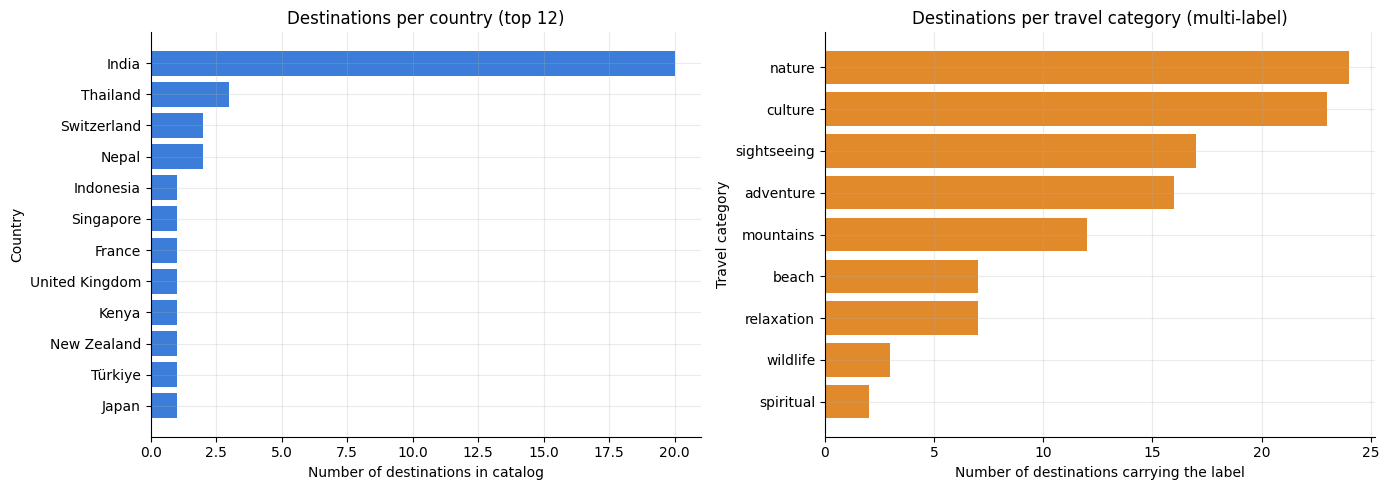

Observation: India accounts for 20 of 41 destinations (49%); 18 countries in total.
Observation: most common category = 'nature' (24), least common = 'spiritual' (2). Categories overlap, so counts exceed the number of destinations.


In [67]:
def count_labels(df, column):
    """Count how many destinations carry each label of a pipe-separated column."""
    return pd.Series([t for v in df[column] for t in split_pipe(v)]).value_counts()


def annotated_heatmap(ax, data, title, xlabel="", ylabel="", cmap="viridis", vmin=None, vmax=None, fmt="{:.1f}"):
    """Draw a labelled heatmap with cell annotations on `ax` (matplotlib only)."""
    im = ax.imshow(data.values, cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(data.shape[1]))
    ax.set_xticklabels([str(c).replace("_score", "").replace("_", " ") for c in data.columns], rotation=45, ha="right")
    ax.set_yticks(range(data.shape[0]))
    ax.set_yticklabels(data.index)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(False)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            value = data.values[i, j]
            r, g, b, _ = im.cmap(im.norm(value))
            text_color = "black" if (0.299 * r + 0.587 * g + 0.114 * b) > 0.5 else "white"   # readable on any colormap
            ax.text(j, i, fmt.format(value), ha="center", va="center", fontsize=8, color=text_color)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02)


# --- Charts 1 & 2: counts by country and by travel category -------------------
country_counts = catalog["country"].value_counts()
category_counts = count_labels(catalog, "travel_categories")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_countries = country_counts.head(12)[::-1]
axes[0].barh(top_countries.index, top_countries.values, color="#3b7dd8")
axes[0].set_title("Destinations per country (top 12)")
axes[0].set_xlabel("Number of destinations in catalog")
axes[0].set_ylabel("Country")
axes[1].barh(category_counts.index[::-1], category_counts.values[::-1], color="#e08a2c")
axes[1].set_title("Destinations per travel category (multi-label)")
axes[1].set_xlabel("Number of destinations carrying the label")
axes[1].set_ylabel("Travel category")
plt.tight_layout()
plt.show()
print(f"Observation: {country_counts.index[0]} accounts for {country_counts.iloc[0]} of {len(catalog)} destinations "
      f"({country_counts.iloc[0] / len(catalog):.0%}); {len(country_counts)} countries in total.")
print(f"Observation: most common category = '{category_counts.index[0]}' ({category_counts.iloc[0]}), "
      f"least common = '{category_counts.index[-1]}' ({category_counts.iloc[-1]}). Categories overlap, so counts exceed the number of destinations.")

**Caveats for charts 1–2.** The country imbalance is a *design choice of this catalog* (it is India-centred because TravelSync's first audience is Indian), not a statement about world tourism. Categories are multi-label, so bars do not sum to the number of destinations. Rare categories (few destinations) can only ever produce a few good matches — an important limit for users who select them.

Why raw costs cannot be compared directly — local-currency ranges differ by orders of magnitude:


,count,min,max
currency,,,
SGD,1,100,100
GBP,1,120,120
NZD,1,150,150
EUR,2,130,150
CHF,2,160,180
USD,13,28,220
INR,20,2300,6200
JPY,1,18000,18000


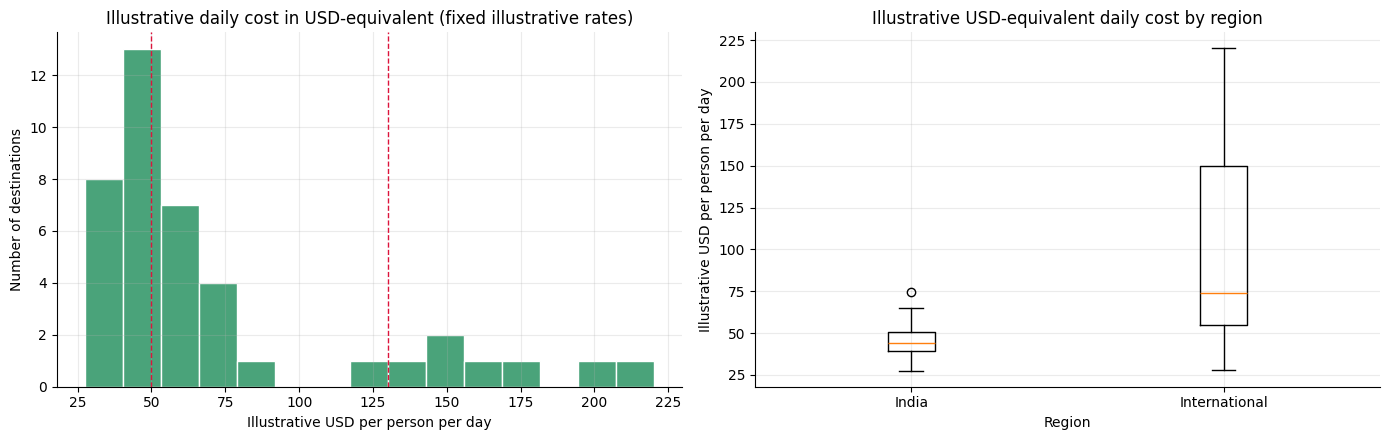

Observation: destinations per budget band (dashed lines = band thresholds):


budget_level,budget,moderate,premium
region,,,
India,14,6,0
International,4,10,7


Observation: median illustrative cost — India: $44/day, International: $74/day.


In [68]:
# --- Chart 3: cost distribution -------------------------------------------------
print("Why raw costs cannot be compared directly — local-currency ranges differ by orders of magnitude:")
display(catalog.groupby("currency")["estimated_daily_cost"].agg(["count", "min", "max"]).sort_values("max"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(catalog["estimated_daily_cost_usd"], bins=15, color="#4aa37a", edgecolor="white")
axes[0].set_title("Illustrative daily cost in USD-equivalent (fixed illustrative rates)")
axes[0].set_xlabel("Illustrative USD per person per day")
axes[0].set_ylabel("Number of destinations")
for threshold in BUDGET_BAND_MAX_USD.values():
    axes[0].axvline(threshold, color="crimson", linestyle="--", linewidth=1)
groups = [catalog.loc[catalog.region == r, "estimated_daily_cost_usd"] for r in ["India", "International"]]
axes[1].boxplot(groups)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["India", "International"])
axes[1].set_title("Illustrative USD-equivalent daily cost by region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Illustrative USD per person per day")
plt.tight_layout()
plt.show()
band_counts = catalog.groupby(["region", "budget_level"]).size().unstack(fill_value=0).reindex(columns=BUDGET_LEVELS, fill_value=0)
print("Observation: destinations per budget band (dashed lines = band thresholds):")
display(band_counts)
print(f"Observation: median illustrative cost — India: ${groups[0].median():.0f}/day, International: ${groups[1].median():.0f}/day.")

**Caveats for chart 3.** These are *illustrative* amounts converted at *fixed* illustrative rates; real costs vary by season, traveler style and exchange-rate movement. The cost gap between India and international destinations is a property of how this catalog was authored. Also note that "premium" contains very few Indian destinations, so users who choose *premium + India* will see limited choice (and the explanations will say so).

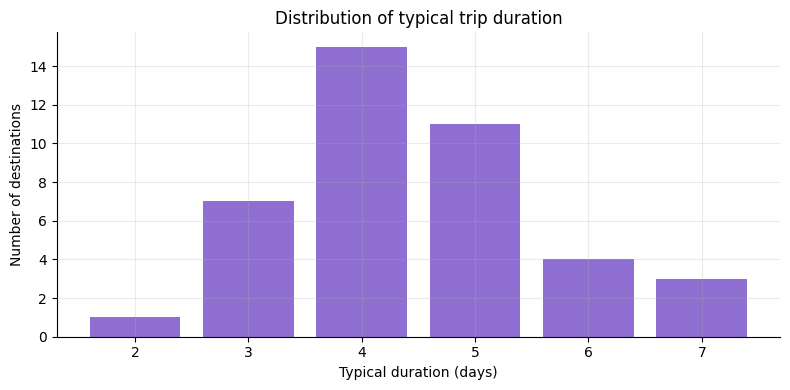

Observation: typical duration ranges 2–7 days; median 4; most common = 4 days (15 destinations).


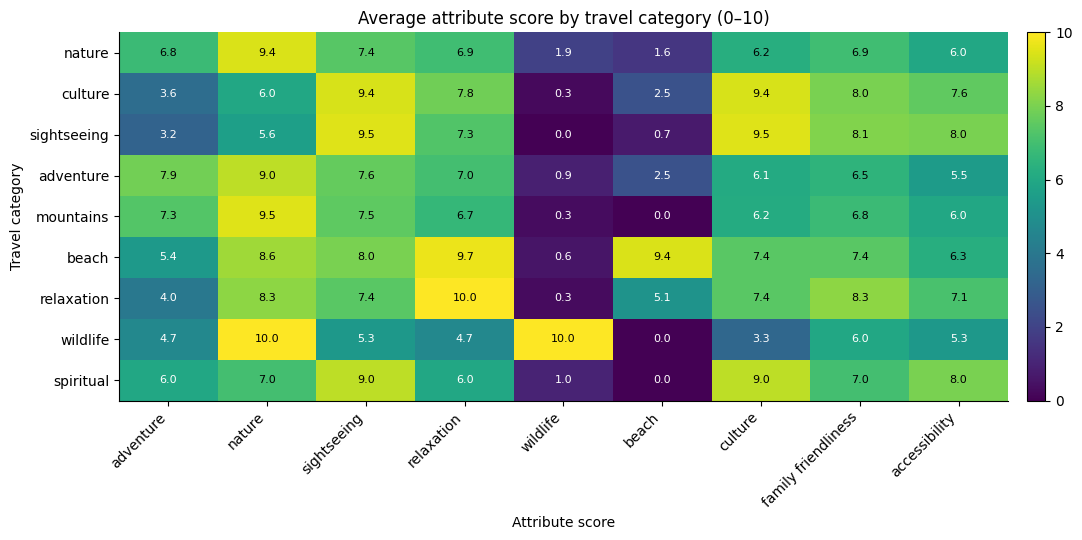

Consistency check — does each category's highest average score sit in the matching attribute?
  adventure  -> adventure_score    no (highest is nature_score)
  wildlife   -> wildlife_score     no (highest is nature_score)
  beach      -> beach_score        no (highest is relaxation_score)
  culture    -> culture_score      no (highest is sightseeing_score)
  nature     -> nature_score       yes


In [69]:
# --- Chart 4: typical duration; Chart 5: mean attributes by category ----------------
fig, ax = plt.subplots(figsize=(8, 4))
duration_counts = catalog["typical_duration_days"].value_counts().sort_index()
ax.bar(duration_counts.index.astype(str), duration_counts.values, color="#8f6fd1")
ax.set_title("Distribution of typical trip duration")
ax.set_xlabel("Typical duration (days)")
ax.set_ylabel("Number of destinations")
plt.tight_layout()
plt.show()
print(f"Observation: typical duration ranges {catalog.typical_duration_days.min()}–{catalog.typical_duration_days.max()} days; "
      f"median {catalog.typical_duration_days.median():.0f}; most common = {duration_counts.idxmax()} days ({duration_counts.max()} destinations).")

THEME_SCORE_COLUMNS = ["adventure_score", "nature_score", "sightseeing_score", "relaxation_score", "wildlife_score", "beach_score", "culture_score"]
category_profile = pd.DataFrame({
    cat: catalog.loc[catalog["travel_categories"].map(lambda v, c=cat: c in split_pipe(v)), SCORE_COLUMNS].mean()
    for cat in category_counts.index
}).T
fig, ax = plt.subplots(figsize=(11, 5.5))
annotated_heatmap(ax, category_profile, "Average attribute score by travel category (0–10)", "Attribute score", "Travel category", vmin=0, vmax=10)
plt.tight_layout()
plt.show()
checks = {"adventure": "adventure_score", "wildlife": "wildlife_score", "beach": "beach_score", "culture": "culture_score", "nature": "nature_score"}
print("Consistency check — does each category's highest average score sit in the matching attribute?")
for cat, col in checks.items():
    top_col = category_profile.loc[cat].idxmax()
    verdict = "yes" if top_col == col else f"no (highest is {top_col})"
    print(f"  {cat:<10} -> {col:<18} {verdict}")

**Why chart 5 matters.** It is a *data-consistency check*: a "wildlife" destination should have a high `wildlife_score`. If a category's strongest attribute were something else, the labels and scores would disagree and the recommender would behave oddly. The printed lines above report the actual result; where the answer is "no", the category's destinations are on average rated even higher on another attribute (typically `nature_score` for adventure destinations in mountains), which is plausible rather than an error — but worth knowing. (Assumption: the scores were authored independently of the tags; they were authored by the same person, so agreement is partly expected.)

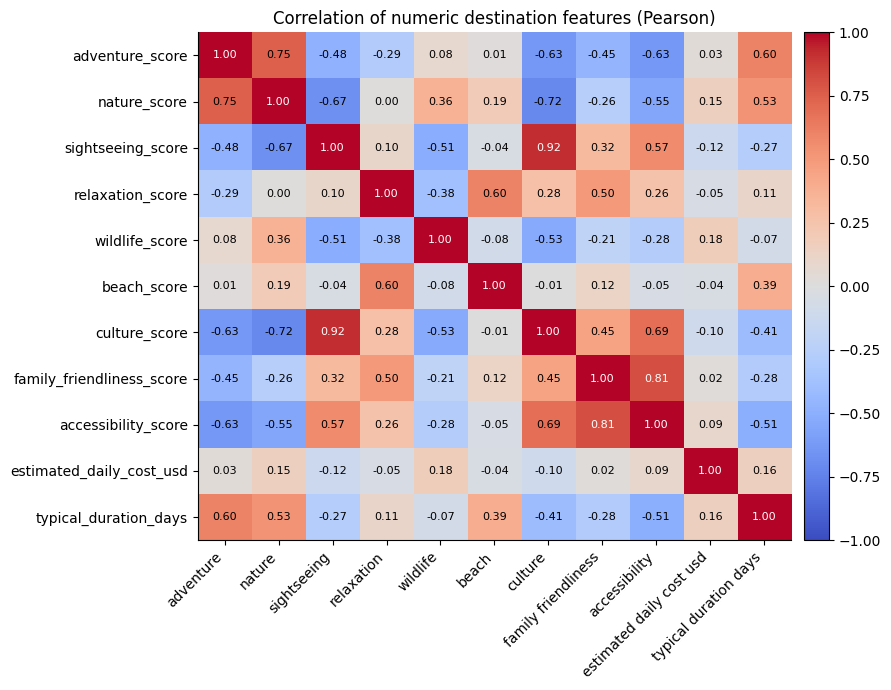

Observation: strongest negative correlations:
  nature_score vs culture_score: -0.72
  nature_score vs sightseeing_score: -0.67
  adventure_score vs culture_score: -0.63
Observation: strongest positive correlations:
  adventure_score vs nature_score: +0.75
  family_friendliness_score vs accessibility_score: +0.81
  sightseeing_score vs culture_score: +0.92


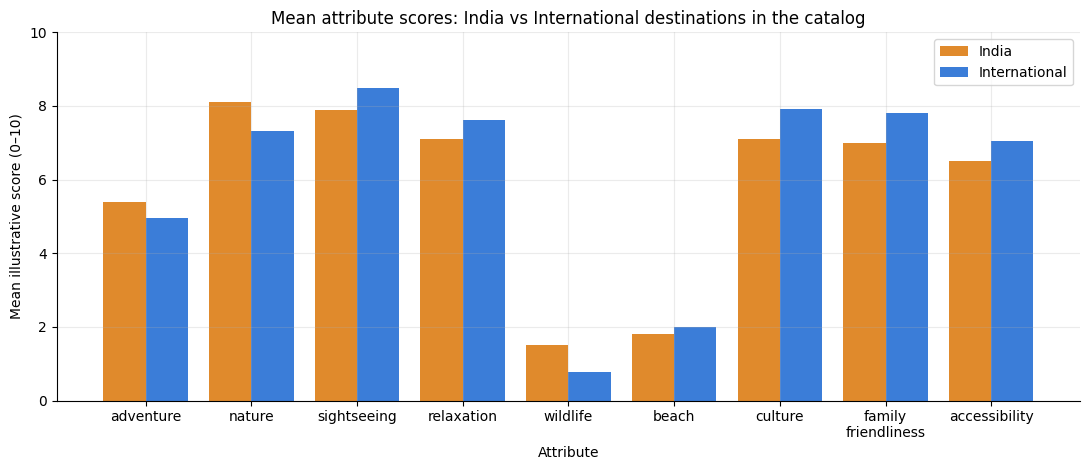

In [70]:
# --- Chart 6: correlation heatmap; Chart 7: India vs International ------------------
numeric_features = SCORE_COLUMNS + ["estimated_daily_cost_usd", "typical_duration_days"]
corr = catalog[numeric_features].corr()
fig, ax = plt.subplots(figsize=(9, 7))
annotated_heatmap(ax, corr, "Correlation of numeric destination features (Pearson)", "", "", cmap="coolwarm", vmin=-1, vmax=1, fmt="{:.2f}")
plt.tight_layout()
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().sort_values()
print("Observation: strongest negative correlations:")
for (a, b), v in pairs.head(3).items():
    print(f"  {a} vs {b}: {v:+.2f}")
print("Observation: strongest positive correlations:")
for (a, b), v in pairs.tail(3).items():
    print(f"  {a} vs {b}: {v:+.2f}")

by_region = catalog.groupby("region")[SCORE_COLUMNS].mean().T
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(by_region))
ax.bar(x - 0.2, by_region["India"], width=0.4, label="India", color="#e08a2c")
ax.bar(x + 0.2, by_region["International"], width=0.4, label="International", color="#3b7dd8")
ax.set_xticks(x)
ax.set_xticklabels([c.replace("_score", "").replace("_", "\n") for c in by_region.index])
ax.set_title("Mean attribute scores: India vs International destinations in the catalog")
ax.set_xlabel("Attribute")
ax.set_ylabel("Mean illustrative score (0–10)")
ax.set_ylim(0, 10)
ax.legend()
plt.tight_layout()
plt.show()

**Reading charts 6–7.** Correlation here describes *how this catalog was authored*, not how real destinations relate — with ~60 hand-rated rows, correlations are also noisy, and correlation is not causation. Correlated features (see the strongest pairs printed above) are why we avoid feeding all columns into one big similarity calculation: correlated or duplicated signals would silently get extra weight (see §6). The region comparison highlights where each region is *relatively* strong in this catalog; it is not a claim about the real world.

Missing-value visualization: the loaded catalog has no missing values, so there is nothing to plot.


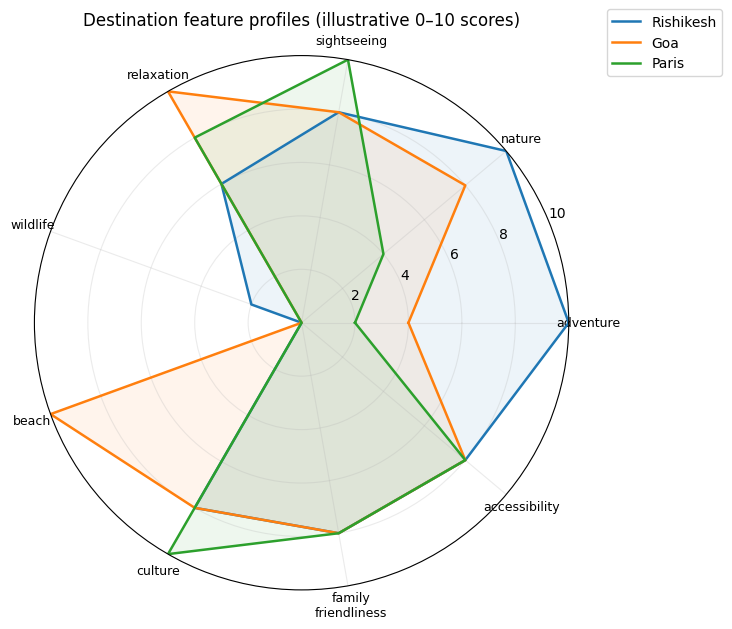

In [71]:
# --- Chart 8: missing values; Chart 9: destination feature profiles ---------------------
missing_counts = catalog_raw.isna().sum()
missing_counts = missing_counts[missing_counts > 0]
if missing_counts.empty:
    print("Missing-value visualization: the loaded catalog has no missing values, so there is nothing to plot.")
else:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(missing_counts.index[::-1], missing_counts.values[::-1], color="crimson")
    ax.set_title("Missing values per column (raw catalog)")
    ax.set_xlabel("Number of missing cells")
    ax.set_ylabel("Column")
    plt.tight_layout()
    plt.show()


def radar_profiles(df, names, columns=SCORE_COLUMNS, title="Destination feature profiles (illustrative 0–10 scores)"):
    """Radar chart comparing selected destinations across score columns."""
    angles = np.linspace(0, 2 * np.pi, len(columns), endpoint=False).tolist()
    angles += angles[:1]
    fig, ax = plt.subplots(figsize=(7.5, 7.5), subplot_kw={"polar": True})
    for name in names:
        row = df.loc[df["destination_name"] == name]
        if row.empty:
            raise KeyError(f"Destination not in catalog: {name}")
        values = row[columns].iloc[0].tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=1.8, label=name)
        ax.fill(angles, values, alpha=0.08)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([c.replace("_score", "").replace("_", "\n") for c in columns], fontsize=9)
    ax.set_ylim(0, 10)
    ax.set_title(title, pad=22)
    ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
    plt.tight_layout()
    plt.show()


example_names = [n for n in ["Rishikesh", "Goa", "Paris", "Ranthambore"] if n in set(catalog.destination_name)]
radar_profiles(catalog, example_names)

**What the profiles show.** Each shape is one destination's illustrative attribute profile; distinctive shapes (e.g. a wildlife park vs a city) are what lets a content-based recommender separate destinations. Overlapping shapes mean the catalog has near-substitutes — useful for diversity checks later.

### EDA takeaways that shape the design
1. The catalog is **India-heavy** and **uneven across categories** → region is handled as an explicit filter, and the explanation must be honest when few good matches exist.
2. **Costs live in different currencies** → every budget comparison goes through the illustrative USD-equivalent band.
3. **Attributes are correlated** → we separate "theme match" from other criteria instead of one giant similarity over all columns.
4. **Missing/invalid data is handled up front** → the recommender can assume a validated catalog.

## 6. Feature engineering and preprocessing

### Goal
Represent every destination — and every user's questionnaire answers — in **one consistent feature space**, using a reproducible scikit-learn `ColumnTransformer`.

### Design
| Feature block | Encoding | Why |
|---|---|---|
| `scores` (9 columns) | scaled by ×0.1 to a fixed 0–1 range | Scores have a *defined* 0–10 scale, so we use a fixed scale rather than catalog-dependent min–max (which would shift if the catalog changed). |
| `categories`, `seasons`, `companions` | multi-hot via `CountVectorizer(binary=True)` with a **fixed vocabulary** | Handles multi-label columns; a fixed vocabulary keeps the feature space stable even if a label is absent from a catalog. |
| `region`, `subregion`, `pace` | one-hot | Nominal categories. |
| `budget` | ordinal 0/1/2 | Budget levels are *ordered*. |
| `cost_usd` | `log1p` then standardized | Costs are right-skewed. |
| `duration` | standardized | Numeric. |

**Deliberately excluded:** `destination_id` (an arbitrary label) and the raw local-currency cost (not comparable across currencies). Free text (descriptions and activities) is vectorized separately with TF-IDF and used only for the *"similar destinations"* helper, **not** in the match score — otherwise wording quirks in descriptions could dominate the ranking.

### The "theme space"
Ten *theme* features describe what a trip is about: seven come from scores (adventure, nature, sightseeing, relaxation, wildlife, beach, culture) and three from category tags (mountains, spiritual, city). A user's travel type and interests are converted into a vector over **exactly these ten features**, which is how questionnaire answers enter the same space as destination records.

### What the weights mean
Weights used for ranking (§7) are **editorial choices**, not learned parameters. They say "theme match matters more than pace", which is a product judgement. They cannot tell us what real travelers prefer; that requires feedback data (§8, §17).

In [72]:
def build_structured_preprocessor() -> ColumnTransformer:
    """Fixed-scale, fixed-vocabulary preprocessing for destination records (picklable: no lambdas)."""
    scale_0_10 = FunctionTransformer(partial(np.multiply, 0.1), feature_names_out="one-to-one")
    log_then_standardize = Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("standardize", StandardScaler()),
    ])

    def multi_hot(vocabulary):
        return CountVectorizer(token_pattern=r"[^|]+", binary=True, lowercase=False, vocabulary=sorted(vocabulary))

    return ColumnTransformer(
        transformers=[
            ("scores", scale_0_10, SCORE_COLUMNS),
            ("categories", multi_hot(VALID_CATEGORIES), "travel_categories"),
            ("seasons", multi_hot(VALID_SEASONS), "best_seasons"),
            ("companions", multi_hot(VALID_COMPANIONS), "suitable_companions"),
            ("geo_pace", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["region", "subregion", "travel_pace"]),
            ("budget", OrdinalEncoder(categories=[BUDGET_LEVELS]), ["budget_level"]),
            ("cost_usd", log_then_standardize, ["estimated_daily_cost_usd"]),
            ("duration", StandardScaler(), ["typical_duration_days"]),
        ],
        remainder="drop",  # destination_id, names, raw local-currency cost and free text never enter the features
        sparse_threshold=0.0,
        verbose_feature_names_out=True,
    )


THEMES = ["adventure", "nature", "sightseeing", "relaxation", "wildlife", "beach", "culture", "mountains", "spiritual", "city"]
THEME_TO_FEATURE = {
    "adventure": "scores__adventure_score", "nature": "scores__nature_score", "sightseeing": "scores__sightseeing_score",
    "relaxation": "scores__relaxation_score", "wildlife": "scores__wildlife_score", "beach": "scores__beach_score",
    "culture": "scores__culture_score", "mountains": "categories__mountains", "spiritual": "categories__spiritual", "city": "categories__city",
}


def build_text_blob(df: pd.DataFrame) -> pd.Series:
    """Text used ONLY for the 'similar destinations' helper (description + activities + category words)."""
    return (df["destination_description"].fillna("") + ". " + df["recommended_activities"].str.replace("|", ", ", regex=False)
            + ". " + df["travel_categories"].str.replace("|", " ", regex=False))


class DestinationFeatureSpace:
    """Fits the preprocessing and exposes the destination feature matrices used by the recommender."""

    def fit(self, df: pd.DataFrame):
        self.preprocessor_ = build_structured_preprocessor().fit(df)
        self.feature_names_ = list(self.preprocessor_.get_feature_names_out())
        self.destination_ids_ = df["destination_id"].tolist()
        self.structured_ = pd.DataFrame(self.preprocessor_.transform(df), columns=self.feature_names_, index=self.destination_ids_)
        self.theme_matrix_ = pd.DataFrame({t: self.structured_[col] for t, col in THEME_TO_FEATURE.items()})
        self.text_vectorizer_ = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), sublinear_tf=True).fit(build_text_blob(df))
        self.text_matrix_ = self.text_vectorizer_.transform(build_text_blob(df))
        return self


feature_space = DestinationFeatureSpace().fit(catalog)
print(f"Structured destination features: {feature_space.structured_.shape[1]} columns | theme space: {feature_space.theme_matrix_.shape[1]} | TF-IDF vocabulary: {len(feature_space.text_vectorizer_.vocabulary_)} terms")
assert not any("destination_id" in n or "destination_name" in n for n in feature_space.feature_names_), "identifier leaked into features"
assert feature_space.theme_matrix_.min().min() >= 0 and feature_space.theme_matrix_.max().max() <= 1, "theme features must lie in [0, 1]"
print("Checks passed: no identifiers among features; theme features lie in [0, 1].")

# Why not one big cosine similarity over everything? Show how much each block contributes to vector length.
block = pd.Series(feature_space.feature_names_).str.split("__").str[0]
squared = (feature_space.structured_ ** 2).sum(axis=0)
share = squared.groupby(block.values).sum() / squared.sum()
n_cols = block.value_counts()
display(pd.DataFrame({"columns": n_cols, "share_of_total_squared_norm": share.round(3)}).sort_values("share_of_total_squared_norm", ascending=False))

Structured destination features: 54 columns | theme space: 10 | TF-IDF vocabulary: 932 terms
Checks passed: no identifiers among features; theme features lie in [0, 1].


,columns,share_of_total_squared_norm
scores,9,0.232
companions,4,0.174
geo_pace,23,0.165
categories,10,0.148
seasons,5,0.112
budget,1,0.059
cost_usd,1,0.055
duration,1,0.055


**Reading the table.** Blocks with many columns (e.g. one-hot geography) or standardized columns (which can reach ±2) can account for a large share of a vector's length. A single cosine similarity over *all* columns would therefore be steered by those blocks — "being in the same sub-region" could outweigh "matching what the traveler wants to do". That is why §7 scores each criterion separately and combines them with explicit, inspectable weights.

### Converting questionnaire answers into the same feature space
We define the questionnaire's controlled vocabularies, a validator (`validate_preferences`) and the conversion to a theme vector here — because the conversion belongs to the feature space — and §10 documents and exercises the questionnaire itself.

In [73]:
TRAVEL_TYPE_OPTIONS = THEMES                      # plus "flexible"
COMPANION_OPTIONS = ["solo", "couple", "friends", "family", "family_with_kids", "family_with_parents"]
SEASON_OPTIONS = ["winter", "spring", "summer", "autumn"]
COMFORT_OPTIONS = ["easy_access"]
QUESTION_IDS = ["travel_type", "companions", "budget_level", "duration_days", "region", "interests", "travel_pace",
                "travel_season", "travel_month", "comfort_needs"]
FLEXIBLE_TOKENS = {"", "flexible", "any", "unknown", "not_sure", "no_preference", "none", "undecided", "dont_know", "anywhere", "worldwide"}
THEME_ALIASES = {"cultural": "culture", "heritage": "culture", "relax": "relaxation", "relaxing": "relaxation", "beaches": "beach",
                 "mountain": "mountains", "cities": "city", "animals": "wildlife", "safari": "wildlife", "history": "culture"}
PACE_ALIASES = {"slow": "relaxed", "easy": "relaxed", "moderate": "balanced", "medium": "balanced", "packed": "fast", "busy": "fast"}
COMPANION_ALIASES = {"alone": "solo", "partner": "couple", "friend": "friends", "family_with_children": "family_with_kids",
                     "family_with_parent": "family_with_parents", "family_with_seniors": "family_with_parents"}
BUDGET_ALIASES = {"low": "budget", "cheap": "budget", "mid": "moderate", "medium": "moderate", "mid_range": "moderate", "high": "premium", "luxury": "premium"}
COMFORT_ALIASES = {"accessible": "easy_access", "accessibility": "easy_access", "low_effort": "easy_access"}
MONTH_TO_SEASON = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                   6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
TYPE_WEIGHT, INTEREST_WEIGHT = 1.0, 0.7


class PreferenceValidationError(ValueError):
    """Raised when questionnaire answers are invalid. `.errors` lists every problem found."""

    def __init__(self, errors):
        self.errors = list(errors)
        super().__init__("; ".join(self.errors))


def _pref_token(value) -> str:
    return re.sub(r"[\s\-]+", "_", str(value).strip().lower().replace("'", ""))


def _is_flexible(value) -> bool:
    if value is None or (isinstance(value, float) and math.isnan(value)):
        return True
    if isinstance(value, (list, tuple, set)):
        return len(value) == 0
    return isinstance(value, str) and _pref_token(value) in FLEXIBLE_TOKENS


def _parse_duration(value):
    """Return (min_days, max_days) from an int, 'a-b' string, or [a, b] list; raise ValueError with a clear message."""
    if isinstance(value, bool):
        raise ValueError("duration_days must be a number or range, not a boolean")
    if isinstance(value, (int, np.integer)) or (isinstance(value, float) and value.is_integer()):
        low = high = int(value)
    elif isinstance(value, str):
        match = re.fullmatch(r"\s*(\d+)\s*(?:[-\u2013\u2014]|to)\s*(\d+)\s*(?:days?)?\s*|\s*(\d+)\s*(?:days?)?\s*", value)
        if not match:
            raise ValueError(f"duration_days '{value}' is not understood (use e.g. 5 or '4-7')")
        low, high = (int(match.group(1)), int(match.group(2))) if match.group(1) else (int(match.group(3)),) * 2
    elif isinstance(value, (list, tuple)) and len(value) == 2 and all(isinstance(v, (int, np.integer)) and not isinstance(v, bool) for v in value):
        low, high = int(value[0]), int(value[1])
    else:
        raise ValueError(f"duration_days must be an integer, a range like '4-7', or [min, max]; got {value!r}")
    if not (1 <= low <= high <= 60):
        raise ValueError(f"duration_days must satisfy 1 <= min <= max <= 60; got {low}-{high}")
    return low, high


def validate_preferences(raw, region_lookup=None):
    """Validate and normalize questionnaire answers.

    Returns (preferences, warnings). Missing / 'flexible' answers become None (the criterion is then ignored,
    not guessed). Raises PreferenceValidationError listing ALL problems if any answer is invalid.
    """
    lookup = REGION_LOOKUP if region_lookup is None else region_lookup
    if not isinstance(raw, Mapping):
        raise PreferenceValidationError([f"preferences must be a JSON object / dict, got {type(raw).__name__}"])
    errors, warns = [], []
    unknown = sorted(set(raw) - set(QUESTION_IDS))
    if unknown:
        warns.append(f"Ignored unknown field(s): {unknown}")

    def single_choice(key, options, aliases=None):
        value = raw.get(key)
        if _is_flexible(value):
            return None
        if not isinstance(value, str):
            errors.append(f"{key} must be a string, got {type(value).__name__}")
            return None
        token = _pref_token(value)
        token = (aliases or {}).get(token, token)
        if token not in options:
            hint = get_close_matches(token, options, n=2)
            errors.append(f"{key} '{value}' is not valid; choose from {list(options)}" + (f" (did you mean {hint}?)" if hint else ""))
            return None
        return token

    def multi_choice(key, options, aliases=None):
        value = raw.get(key)
        if _is_flexible(value):
            return []
        items = [p for p in value.split(",")] if isinstance(value, str) else list(value) if isinstance(value, (list, tuple, set)) else None
        if items is None:
            errors.append(f"{key} must be a list of strings, got {type(value).__name__}")
            return []
        chosen = []
        for item in items:
            if not isinstance(item, str):
                errors.append(f"{key} contains a non-string entry: {item!r}")
                continue
            token = _pref_token(item)
            if token in FLEXIBLE_TOKENS:
                continue
            token = (aliases or {}).get(token, token)
            if token not in options:
                errors.append(f"{key} entry '{item}' is not valid; choose from {list(options)}")
            elif token not in chosen:
                chosen.append(token)
        return chosen

    prefs = {
        "travel_type": single_choice("travel_type", TRAVEL_TYPE_OPTIONS, THEME_ALIASES),
        "companions": single_choice("companions", COMPANION_OPTIONS, COMPANION_ALIASES),
        "budget_level": single_choice("budget_level", BUDGET_LEVELS, BUDGET_ALIASES),
        "travel_pace": single_choice("travel_pace", VALID_PACES, PACE_ALIASES),
        "interests": multi_choice("interests", THEMES, THEME_ALIASES),
        "comfort_needs": multi_choice("comfort_needs", COMFORT_OPTIONS, COMFORT_ALIASES),
        "duration_min": None, "duration_max": None, "region": None, "season": None,
    }

    if not _is_flexible(raw.get("duration_days")):
        try:
            prefs["duration_min"], prefs["duration_max"] = _parse_duration(raw["duration_days"])
        except ValueError as exc:
            errors.append(str(exc))

    region_value = raw.get("region")
    if not _is_flexible(region_value):
        if not isinstance(region_value, str):
            errors.append(f"region must be a string, got {type(region_value).__name__}")
        else:
            normalized_region = region_value.strip().lower()
            if normalized_region == "europe":
                prefs["region"] = {
                    "kind": "broad_region",
                    "value": "Europe"
                }
            elif normalized_region in lookup:
                kind, canonical = lookup[normalized_region]
                prefs["region"] = {"kind": kind, "value": canonical}
            else:
                hint = get_close_matches(normalized_region, list(lookup), n=3)
                errors.append(f"region '{region_value}' is not in the catalog" + (f" (did you mean {[lookup[h][1] for h in hint]}?)" if hint else ""))

    season = single_choice("travel_season", SEASON_OPTIONS)
    month_value = raw.get("travel_month")
    month_season = None
    if not _is_flexible(month_value):
        if isinstance(month_value, bool) or not isinstance(month_value, (int, np.integer)) or not 1 <= int(month_value) <= 12:
            errors.append(f"travel_month must be an integer 1-12, got {month_value!r}")
        else:
            month_season = MONTH_TO_SEASON[int(month_value)]
    if season and month_season and season != month_season:
        warns.append(f"travel_season '{season}' and travel_month {month_value} disagree; using travel_season")
    prefs["season"] = season or month_season

    if errors:
        raise PreferenceValidationError(errors)
    if all(v in (None, []) for v in prefs.values()):
        warns.append("No preferences were provided; returning broadly appealing, diverse destinations.")
    return prefs, warns

In [74]:
import pandas as pd

DEFAULT_DIVERSITY = 0.15

def build_user_theme_vector(prefs: dict) -> pd.Series:
    """Convert user travel type and interests into a normalized 10-dimensional theme vector."""
    vector = pd.Series(0.0, index=THEMES)
    if prefs["travel_type"] and prefs["travel_type"] in vector.index:
        vector[prefs["travel_type"]] = TYPE_WEIGHT
    for interest in prefs["interests"]:
        if interest in vector.index:
            # If the interest is the same as travel_type, keep the maximum weight (1.0)
            vector[interest] = max(vector[interest], INTEREST_WEIGHT)
    return vector


def recommend_with_details(raw_preferences: dict, df: pd.DataFrame, top_n: int = 5, feature_space_obj: 'DestinationFeatureSpace' = None, diversity: float = DEFAULT_DIVERSITY, validated: bool = False):
    """Core recommendation engine. Computes component scores, filters, and applies MMR diversification."""
    if isinstance(top_n, bool) or not isinstance(top_n, int) or top_n < 1:
        raise ValueError(f"top_n must be a positive integer, got {top_n!r}")

    fs = feature_space if feature_space_obj is None else feature_space_obj

    if not validated:
        prefs, warns = validate_preferences(raw_preferences, region_lookup=REGION_LOOKUP)
    else:
        prefs = raw_preferences
        warns = []

    scored = score_destinations(prefs, df, fs)
    eligible_df = df.set_index("destination_id", drop=False).loc[scored["eligible"]]

    if len(eligible_df) == 0:
        empty_recs = pd.DataFrame(columns=["rank", "destination_id", "destination", "country", "match_score", "budget_level", "suggested_duration", "explanation", "trade_offs", "suitable_activities"])
        empty_recs.attrs["warnings"] = warns + ["No destinations matched your criteria."]
        empty_recs.attrs["weights"] = scored.attrs.get("weights", {})
        return empty_recs, scored, warns

    # Check if number of matching/eligible destinations is fewer than top_n requested
    if len(eligible_df) < top_n:
        warns.append(f"Only {len(eligible_df)} matching destination(s) found.")

    # Pick top_n using MMR
    top_ids = select_top_destinations(scored, eligible_df["destination_name"], fs.theme_matrix_, top_n, diversity)

    records = []
    for idx, dest_id in enumerate(top_ids, start=1):
        dest_row = eligible_df.loc[dest_id]
        comp_row = scored.loc[dest_id]
        theme_row = fs.theme_matrix_.loc[dest_id]

        exp, trade = explain_recommendation(dest_row, comp_row, prefs, theme_row, style="recommend")

        usd_cost = dest_row["estimated_daily_cost"] * ILLUSTRATIVE_USD_RATES[dest_row["currency"]]
        budget_str = f"{dest_row['currency']} {dest_row['estimated_daily_cost']:,.0f}/day (~US${usd_cost:,.0f}; {dest_row['budget_level']} band, illustrative)"

        records.append({
            "rank": idx,
            "destination_id": dest_id,
            "destination": dest_row["destination_name"],
            "country": dest_row["country"],
            "match_score": round(comp_row["final_score"] * 100, 1),
            "budget_level": dest_row["budget_level"],
            "suggested_duration": f"about {dest_row['typical_duration_days']} days",
            "estimated_budget": budget_str,
            "suitable_activities": dest_row["recommended_activities"].replace("|", "; "),
            "explanation": exp,
            "trade_offs": trade
        })

    recs_df = pd.DataFrame(records)
    recs_df.attrs["warnings"] = warns
    recs_df.attrs["weights"] = scored.attrs.get("weights", {})
    return recs_df, scored, warns


def recommend_destinations(user_preferences, destinations_df, top_n=5, feature_space=None, diversity=DEFAULT_DIVERSITY):
    """Main public API matching the expected callable signature."""
    recs, _, _ = recommend_with_details(user_preferences, destinations_df, top_n, feature_space, diversity)
    return recs


def show_recommendations(recs: pd.DataFrame):
    """Display recommendation results in a clear format."""
    if not isinstance(recs, pd.DataFrame):
        print("Error: Input is not a pandas DataFrame.")
        return
    if recs.empty:
        print("No recommendations to display.")
        return

    for r in recs.itertuples():
        print(f"#{r.rank}  {r.destination} ({r.country})  |  match {r.match_score:.1f}/100  |  {r.suggested_duration}  |  {r.estimated_budget}")
        print(f"     Explanation: {r.explanation}")
        print(f"     Trade-offs: {r.trade_offs}")
        print(f"     Activities: {r.suitable_activities}\n")

## 7. Baseline content-based recommender

### What this is (and is not)
This baseline is **content-based + rule-based**: it compares the user's stated needs with destination *attributes* and combines several criteria with **hand-chosen weights**. **It is not machine learning** — nothing is trained, and the weights are not learned from traveler behaviour.

### How a destination is scored (all components lie in 0–1)
| Component | Weight | Definition |
|---|---|---|
| `theme_intensity` | 0.28 | Weighted mean of the destination's strength on the themes the user asked for (travel type weight 1.0, each interest 0.7). |
| `theme_profile` | 0.12 | Cosine similarity between the user's theme vector and the destination's theme vector (rewards destinations *specialized* in what was asked, not just generally strong). |
| `budget` | 0.14 | Asymmetric: cheaper than your budget is fine (slight discount), over budget is penalized (one band over = 0.4, two = 0). |
| `duration` | 0.10 | 1.0 inside the user's range; needing *more* days than available is penalized more than having spare time. |
| `season` | 0.08 | 1.0 if the travel season is among the destination's best seasons (or it is year-round), else 0.1. |
| `pace` | 0.06 | 1 − 0.5 × (distance between relaxed/balanced/fast). |
| `companions` | 0.12 | Whether the destination is marked suitable for that companion type; family trips also use `family_friendliness_score`. |
| `accessibility` | 0.10 | `accessibility_score`/10 — active only if the user asks for easy access or travels with parents. |

- **Unanswered criteria are dropped and the remaining weights are renormalized** — we never invent a preference or give a "neutral" score.
- **Region is a hard filter**, because "India only" is a requirement, not a preference.
- If no theme is chosen, `overall_appeal` (mean of a destination's top-3 theme scores) replaces the theme components so that all-rounders surface.
- Results are **lightly diversity re-ranked** (Maximal Marginal Relevance, `diversity=0.15`) so five near-identical hill stations do not fill the list. Set `diversity=0` for pure score order.
- The **match score** (0–100) is the weighted average ×100. It is a *similarity-style ordering score*, **not a probability**.

In [75]:
SCORING_WEIGHTS = {"theme_intensity": 0.28, "theme_profile": 0.12, "budget": 0.14, "duration": 0.10,
                   "season": 0.08, "pace": 0.06, "companions": 0.12, "accessibility": 0.10}
assert abs(sum(SCORING_WEIGHTS.values()) - 1.0) < 1e-9
WEIGHT_KEY = {"overall_appeal": "theme_intensity"}
# Key = destination budget rank minus user budget rank (positive = destination is pricier than the user's budget).
BUDGET_FIT = {-2: 0.70, -1: 0.85, 0: 1.0, 1: 0.40, 2: 0.0}
PACE_RANK = {"relaxed": 0, "balanced": 1, "fast": 2}
DEFAULT_DIVERSITY = 0.15


def build_region_lookup(df: pd.DataFrame) -> dict:
    """Map lower-case region / sub-region / country names present in `df` to (kind, canonical value)."""
    lookup = {}
    for kind, column in [("subregion", "subregion"), ("country", "country"), ("region", "region")]:
        for value in df[column].dropna().unique():
            lookup[str(value).strip().lower()] = (kind, str(value))
    return lookup


def _label_present(cell, label) -> bool:
    return label in split_pipe(cell)


def score_destinations(prefs: dict, df: pd.DataFrame, feature_space: DestinationFeatureSpace) -> pd.DataFrame:
    """Score every destination. Returns a DataFrame indexed by destination_id with one column per active
    component (each 0-1), `final_score` (0-1), and `eligible` (False if excluded by the region filter)."""
    d = df.set_index("destination_id", drop=False)
    if "budget_rank" not in d:
        d["budget_rank"] = d["budget_level"].map({b: i for i, b in enumerate(BUDGET_LEVELS)})
    missing_ids = set(d.index) - set(feature_space.theme_matrix_.index)
    if missing_ids:
        raise ValueError(f"feature_space was not fitted on these destinations: {sorted(missing_ids)[:3]}...")
    theme = feature_space.theme_matrix_.loc[d.index]
    comps = {}

    # Themes: user's weights live in the same 10-d space as the destination theme matrix.
    weights = build_user_theme_vector(prefs)
    wanted = weights[weights > 0]
    if len(wanted):
        comps["theme_intensity"] = (theme[wanted.index] * wanted).sum(axis=1) / wanted.sum()
        norms = np.linalg.norm(theme.to_numpy(), axis=1) * np.linalg.norm(weights.to_numpy())
        dots = theme.to_numpy() @ weights.to_numpy()
        comps["theme_profile"] = pd.Series(np.divide(dots, norms, out=np.zeros(len(d)), where=norms > 0), index=d.index)
    else:
        top3 = np.sort(d[THEME_SCORE_COLUMNS].to_numpy(dtype=float), axis=1)[:, -3:].mean(axis=1) / 10
        comps["overall_appeal"] = pd.Series(top3, index=d.index)

    if prefs["budget_level"]:
        diff = d["budget_rank"] - BUDGET_LEVELS.index(prefs["budget_level"])
        comps["budget"] = diff.map(BUDGET_FIT).astype(float)

    if prefs["duration_min"] is not None:
        typical = d["typical_duration_days"].to_numpy(dtype=float)
        lo, hi = prefs["duration_min"], prefs["duration_max"]
        needs_more = np.clip(typical - hi, 0, None)      # destination typically needs more days than the user has
        spare = np.clip(lo - typical, 0, None)           # user has more days than the typical visit
        comps["duration"] = pd.Series(np.clip(1 - 1.5 * needs_more / typical - 0.5 * spare / lo, 0, 1), index=d.index)

    if prefs["season"]:
        in_season = d["best_seasons"].map(lambda v: _label_present(v, prefs["season"]) or _label_present(v, "year_round"))
        comps["season"] = in_season.map({True: 1.0, False: 0.1}).astype(float)

    if prefs["travel_pace"]:
        gap = (d["travel_pace"].map(PACE_RANK) - PACE_RANK[prefs["travel_pace"]]).abs()
        comps["pace"] = 1 - 0.5 * gap

    if prefs["companions"]:
        is_family = prefs["companions"].startswith("family")
        label = "family" if is_family else prefs["companions"]
        suitable = d["suitable_companions"].map(lambda v: _label_present(v, label)).map({True: 1.0, False: 0.25}).astype(float)
        comps["companions"] = 0.5 * suitable + 0.5 * d["family_friendliness_score"] / 10 if is_family else suitable

    if "easy_access" in prefs["comfort_needs"] or prefs["companions"] == "family_with_parents":
        comps["accessibility"] = d["accessibility_score"] / 10

    comp_df = pd.DataFrame(comps)
    active = pd.Series({c: SCORING_WEIGHTS[WEIGHT_KEY.get(c, c)] for c in comp_df.columns})
    active = active / active.sum()                      # renormalize over the criteria the user actually answered
    comp_df["final_score"] = (comp_df[active.index] * active).sum(axis=1)

    region = prefs["region"]
    if region is None:
        comp_df["eligible"] = True
    elif region["kind"] == "broad_region" and region["value"] == "Europe":
        comp_df["eligible"] = d["subregion"].str.lower().str.contains("europe", na=False)
    else:
        comp_df["eligible"] = (d[region["kind"]] == region["value"])

    comp_df.attrs["weights"] = active.to_dict()
    return comp_df


def select_top_destinations(scored: pd.DataFrame, names: pd.Series, theme_matrix: pd.DataFrame, top_n: int, diversity: float) -> list:
    """Pick top_n eligible destinations by score, with optional MMR diversification. Deterministic (ties broken by name)."""
    pool = scored.loc[scored["eligible"], ["final_score"]].assign(name=names.loc[scored.index[scored["eligible"]]])
    pool = pool.sort_values(["final_score", "name"], ascending=[False, True])
    ids = list(pool.index)
    if diversity <= 0 or len(ids) <= 1:
        return ids[:top_n]
    vectors = theme_matrix.loc[ids].to_numpy()
    norms = np.linalg.norm(vectors, axis=1, keepdims=True)
    unit = np.divide(vectors, norms, out=np.zeros_like(vectors), where=norms > 0)
    relevance = pool["final_score"].to_numpy()
    chosen, remaining = [0], list(range(1, len(ids)))
    while len(chosen) < min(top_n, len(ids)):
        max_sim = (unit[remaining] @ unit[chosen].T).max(axis=1)
        mmr = (1 - diversity) * relevance[remaining] - diversity * max_sim
        pick = remaining[int(np.argmax(mmr))]       # argmax returns the first maximum -> deterministic
        chosen.append(pick)
        remaining.remove(pick)
    return [ids[i] for i in chosen]

### Explanations (deterministic, data-grounded)
`explain_recommendation` builds sentences **only from the user's answers and the destination's recorded attributes** — every number it quotes comes from the catalog. It reports *reasons* (what matches) and *trade-offs* (what does not, or what the data cannot confirm). No language model is involved. §13 tests this function further.

In [76]:
def format_budget(row) -> str:
    return (f"{row['currency']} {row['estimated_daily_cost']:,.0f}/day "
            f"(~US${row['estimated_daily_cost_usd']:,.0f}; {row['budget_level']} band, illustrative)")


def explain_recommendation(dest: pd.Series, comp: pd.Series, prefs: dict, theme_row: pd.Series, style: str = "recommend"):
    """Return (explanation, trade_offs) strings for one destination. Deterministic; uses only catalog data and the answers.
    style='recommend' words it as a recommendation; style='assess' is neutral (used for 'why / why not this destination?')."""
    reasons, trade = [], []
    seasons = split_pipe(dest["best_seasons"])
    usd = f"~US${dest['estimated_daily_cost_usd']:,.0f}/day"

    # Themes the user asked for
    weights = build_user_theme_vector(prefs)
    strong, tagged, weak = [], [], []
    for theme in weights[weights > 0].sort_values(ascending=False, kind="stable").index:
        if theme in ("mountains", "spiritual", "city"):
            (tagged if theme_row[theme] > 0 else weak).append((theme, None))
        else:
            score = int(round(theme_row[theme] * 10))
            if score >= 6:
                strong.append((theme, score))
            elif score <= 4:
                weak.append((theme, score))
    if strong:
        reasons.append("it rates " + ", ".join(f"{s}/10 for {t}" for t, s in strong))
    if tagged:
        reasons.append("it is tagged as " + " and ".join(t for t, _ in tagged))
    for theme, score in weak:
        trade.append(f"limited {theme} appeal ({score}/10)" if score is not None else f"not tagged as a {theme} destination")
    if not len(weights[weights > 0]):
        top = theme_row[["adventure", "nature", "sightseeing", "relaxation", "wildlife", "beach", "culture"]].sort_values(ascending=False, kind="stable").head(3)
        reasons.append("it is broadly well-rounded, strongest on " + ", ".join(f"{t} ({int(round(v * 10))}/10)" for t, v in top.items()))

    # Budget
    if prefs["budget_level"]:
        gap = int(dest["budget_rank"]) - BUDGET_LEVELS.index(prefs["budget_level"])
        if gap <= 0:
            reasons.append(f"its estimated cost ({usd}, {dest['budget_level']} band) fits your {prefs['budget_level']} budget")
        else:
            trade.append(f"likely above your {prefs['budget_level']} budget ({usd}, {dest['budget_level']} band)")
    # Duration
    if prefs["duration_min"] is not None:
        lo, hi, typical = prefs["duration_min"], prefs["duration_max"], int(dest["typical_duration_days"])
        trip = f"{lo}" if lo == hi else f"{lo}-{hi}"
        if lo <= typical <= hi:
            reasons.append(f"your {trip}-day trip fits its typical {typical}-day visit")
        elif typical > hi:
            trade.append(f"it typically needs about {typical} days, more than the {trip} you have")
        else:
            trade.append(f"it typically takes about {typical} days, so you may have time to spare")
    # Season
    if prefs["season"]:
        if comp["season"] >= 1.0:
            reasons.append(f"{prefs['season']} is among its best seasons")
        else:
            trade.append(f"{prefs['season']} is not among its listed best seasons (best: {', '.join(seasons)})")
    # Pace
    if prefs["travel_pace"]:
        if dest["travel_pace"] == prefs["travel_pace"]:
            reasons.append(f"its typical pace ({dest['travel_pace']}) matches yours")
        else:
            trade.append(f"its typical pace is {dest['travel_pace']} while you prefer {prefs['travel_pace']}")
    # Companions
    if prefs["companions"]:
        label = "family" if prefs["companions"].startswith("family") else prefs["companions"]
        if _label_present(dest["suitable_companions"], label):
            extra = f" (family-friendliness {int(dest['family_friendliness_score'])}/10)" if label == "family" else ""
            reasons.append(f"it is marked suitable for {label} travel{extra}")
        else:
            trade.append(f"it is not marked as especially suited to {label} travel")
    # Accessibility
    if "accessibility" in comp.index:
        acc = int(dest["accessibility_score"])
        if acc >= 7:
            reasons.append(f"its accessibility rating is high ({acc}/10)")
        elif acc <= 4:
            trade.append(f"accessibility is rated only {acc}/10, so getting around may be demanding")
    # Region (checked against the destination, so excluded destinations are not described as missing matches)
    if prefs["region"]:
        kind, value = prefs["region"]["kind"], prefs["region"]["value"]

        # Map custom broad_region descriptor back to subregion comparison safely for the explanation string builder
        actual_kind = "subregion" if kind == "broad_region" else kind
        is_match = False
        if actual_kind == "subregion" and value == "Europe":
            is_match = "europe" in str(dest[actual_kind]).lower()
        else:
            is_match = (dest[actual_kind] == value)

        if is_match:
            reasons.append(f"it is within your preferred region ({value})" if kind == "region" or kind == "broad_region" else f"it lies in your chosen {kind} ({value})")
        else:
            trade.append(f"it is outside your chosen region ({value})")

    # Data-grounded generic trade-offs
    if "year_round" not in seasons and max(dest["adventure_score"], dest["wildlife_score"], dest["beach_score"], dest["nature_score"]) >= 7:
        trade.append(f"outdoor activities depend on the season (best: {', '.join(seasons)})")
    if max(dest["adventure_score"], dest["wildlife_score"]) >= 7 and split_pipe(dest["recommended_activities"]):
        trade.append(f"some activities (for example {split_pipe(dest['recommended_activities'])[0]}) may cost extra, because the daily estimate excludes most paid activities")

    reasons = [r for r in reasons if r]
    name = dest["destination_name"]
    if style == "assess":
        explanation = (f"{name} matches your answers on these points: " + "; ".join(reasons) + ".") if reasons else (
            f"{name} does not clearly match any of the criteria you answered.")
    else:
        explanation = (f"We recommend {name} because " + "; ".join(reasons) + ".") if reasons else (
            f"{name} ranks here on the criteria you answered.")
    trade_text = ("Trade-offs: " + "; ".join(trade) + ".") if trade else "No major mismatches found against the answers you gave."
    return explanation, trade_text


def explain_destination(destination_name: str, raw_preferences: dict) -> dict:
    """Produce explanation text for any arbitrary destination in the catalog, even if it is not in the top results."""
    matches = catalog.index[catalog["destination_name"].str.lower() == destination_name.strip().lower()]
    if len(matches) == 0:
        raise KeyError(f"'{destination_name}' not found in the catalog")
    dest = catalog.iloc[matches[0]]
    prefs, warns = validate_preferences(raw_preferences, region_lookup=REGION_LOOKUP)
    fs = feature_space
    scored = score_destinations(prefs, catalog, fs)
    comp = scored.loc[dest["destination_id"]]
    explanation, trade = explain_recommendation(dest, comp, prefs, fs.theme_matrix_.loc[dest["destination_id"]], style="assess")
    return {
        "destination_id": dest["destination_id"],
        "destination_name": dest["destination_name"],
        "eligible_for_region_filter": bool(comp["eligible"]),
        "raw_match_score": float(comp["final_score"]),
        "explanation": explanation,
        "trade_offs": trade,
        "warnings": warns,
    }

### The example from the brief
Adventure · friends · moderate budget · 4–7 days · India · nature & sightseeing · balanced pace. The ranking below is **computed from the catalog and weights above**; nothing is hard-coded.

In [77]:
example_user = {"travel_type": "adventure", "companions": "friends", "budget_level": "moderate", "duration_days": "4-7",
                "region": "India", "interests": ["nature", "sightseeing"], "travel_pace": "balanced"}
example_recs = recommend_destinations(example_user, catalog, top_n=5, feature_space=feature_space)
show_recommendations(example_recs)
display(example_recs[["rank", "destination", "country", "match_score", "budget_level", "suggested_duration"]])
print("Active scoring weights (renormalized over answered criteria):", {k: round(v, 3) for k, v in example_recs.attrs["weights"].items()})
print("Note: ranks come after the light diversity re-ranking, so a slightly lower score can sit just above a higher one; use diversity=0 for pure score order.")

#1  Manali (India)  |  match 92.0/100  |  about 5 days  |  INR 3,800/day (~US$46; budget band, illustrative)
     Explanation: We recommend Manali because it rates 10/10 for adventure, 10/10 for nature, 8/10 for sightseeing; its estimated cost (~US$46/day, budget band) fits your moderate budget; your 4-7-day trip fits its typical 5-day visit; its typical pace (balanced) matches yours; it is marked suitable for friends travel; it is within your preferred region (India).
     Trade-offs: Trade-offs: outdoor activities depend on the season (best: spring, summer, autumn); some activities (for example mountain viewpoints) may cost extra, because the daily estimate excludes most paid activities.
     Activities: mountain viewpoints; short hikes; Solang Valley activities; Old Manali cafes

#2  Rishikesh (India)  |  match 91.7/100  |  about 4 days  |  INR 3,200/day (~US$38; budget band, illustrative)
     Explanation: We recommend Rishikesh because it rates 10/10 for adventure, 10/10 for natur

,rank,destination,country,match_score,budget_level,suggested_duration
0,1,Manali,India,92.0,budget,about 5 days
1,2,Rishikesh,India,91.7,budget,about 4 days
2,3,Meghalaya,India,90.3,budget,about 6 days
3,4,Ladakh,India,91.5,moderate,about 7 days
4,5,Spiti Valley,India,89.2,moderate,about 7 days


Active scoring weights (renormalized over answered criteria): {'theme_intensity': 0.341, 'theme_profile': 0.146, 'budget': 0.171, 'duration': 0.122, 'pace': 0.073, 'companions': 0.146}
Note: ranks come after the light diversity re-ranking, so a slightly lower score can sit just above a higher one; use diversity=0 for pure score order.


### Where text (TF-IDF) is used: "similar destinations"
Descriptions and activities are **not** part of the match score. They power a separate helper that finds destinations similar to one the user already likes — half text similarity, half theme-profile similarity.

In [78]:
def similar_destinations(destination_name: str, k: int = 5) -> pd.DataFrame:
    """Destinations most similar to `destination_name` (50% TF-IDF text cosine + 50% theme-profile cosine)."""
    matches = catalog.index[catalog["destination_name"].str.lower() == destination_name.strip().lower()]
    if len(matches) == 0:
        raise KeyError(f"'{destination_name}' not found in the catalog")
    i = matches[0]
    text_sim = (feature_space.text_matrix_ @ feature_space.text_matrix_[i].T).toarray().ravel()
    theme = feature_space.theme_matrix_.loc[catalog["destination_id"]].to_numpy()
    unit = theme / np.linalg.norm(theme, axis=1, keepdims=True)
    theme_sim = unit @ unit[i]
    out = catalog[["destination_name", "country"]].assign(text_similarity=text_sim.round(3), theme_similarity=theme_sim.round(3))
    out["similarity"] = (0.5 * out["text_similarity"] + 0.5 * out["theme_similarity"]).round(3)
    return out.drop(index=i).sort_values(["similarity", "destination_name"], ascending=[False, True]).head(k).reset_index(drop=True)


display(similar_destinations("Rishikesh"))

,destination_name,country,text_similarity,theme_similarity,similarity
0,Varanasi,India,0.060,0.872,0.466
1,Chiang Mai,Thailand,0.059,0.860,0.460
2,Meghalaya,India,0.038,0.880,0.459
3,Cappadocia,Türkiye,0.036,0.822,0.429
4,Coorg,India,0.007,0.832,0.420


## 8. Is supervised machine learning justified here?

Supervised learning needs **labelled outcomes**: for example, rows of *(user, destination, did the user save/book/rate it highly?)*. Let us check, programmatically, what the data actually contains.

In [79]:
INTERACTION_COLUMNS = {"user_id", "rating", "clicked", "saved", "booked", "liked", "feedback", "trip_outcome"}


def assess_supervised_feasibility(df: pd.DataFrame) -> bool:
    present = sorted(INTERACTION_COLUMNS & set(df.columns))
    print("Columns that would indicate user feedback:", present if present else "none found")
    print(f"Rows describing destinations (items): {len(df)}")
    print("Rows describing users, ratings, clicks, saves or bookings: 0")
    feasible = bool(present)
    print("\nVerdict:", "interaction columns present - a supervised/hybrid model may be possible." if feasible else
          "NOT justified. The catalog describes destinations, not what real travelers liked, so any 'accuracy' would measure nothing real.")
    return feasible


has_real_labels = assess_supervised_feasibility(catalog)

Columns that would indicate user feedback: none found
Rows describing destinations (items): 41
Rows describing users, ratings, clicks, saves or bookings: 0

Verdict: NOT justified. The catalog describes destinations, not what real travelers liked, so any 'accuracy' would measure nothing real.


### Decision
- **No real labels exist → no supervised model is trained as a deliverable.** The content-based recommender (§7) remains the working baseline.
- Collaborative filtering and hybrid recommenders are likewise impossible without user–item interactions.

### An educational experiment on *synthetic* data (read the warning)
To show *how* a supervised model would be set up and evaluated once real feedback exists, we simulate users with a hidden "true taste" and train a Random Forest to predict whether each simulated user "liked" each destination.

> ⚠️ **SYNTHETIC — NOT EVIDENCE OF REAL-WORLD QUALITY.** The labels come from a formula *we wrote* using the same theme features the model sees. A model can therefore only rediscover our formula. These numbers demonstrate the *workflow* (group-aware splits, cross-validation, baselines, ranking metrics), **not** how well TravelSync would recommend to real travelers. We do **not** save this model as a product artifact.

Design to avoid leakage: the split is **by user** (no simulated user appears in both train and test), and destination identifiers are not features.

In [80]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score


# ---- Ranking metrics (also unit-tested in §9) ----
def precision_at_k(relevance, k):
    """Share of the top-k items that are relevant."""
    rel = np.asarray(relevance, dtype=float)[:k]
    return float(rel.sum() / k)


def recall_at_k(relevance, k):
    """Share of all relevant items found in the top-k (0 if there are none)."""
    rel = np.asarray(relevance, dtype=float)
    return float(rel[:k].sum() / rel.sum()) if rel.sum() > 0 else 0.0


def ndcg_at_k(relevance, k):
    """Normalized discounted cumulative gain: rewards placing relevant items near the top."""
    rel = np.asarray(relevance, dtype=float)
    discounts = 1.0 / np.log2(np.arange(2, k + 2))
    dcg = float((rel[:k] * discounts[:len(rel[:k])]).sum())
    ideal = np.sort(rel)[::-1][:k]
    idcg = float((ideal * discounts[:len(ideal)]).sum())
    return dcg / idcg if idcg > 0 else 0.0


def average_precision(relevance):
    """Mean of precision values at the ranks where a relevant item appears (basis of MAP)."""
    rel = np.asarray(relevance, dtype=float)
    if rel.sum() == 0:
        return 0.0
    hits = np.cumsum(rel)
    return float((hits[rel > 0] / (np.nonzero(rel)[0] + 1)).mean())


def sample_random_raw_preferences(generator: np.random.Generator) -> dict:
    """A random but VALID raw questionnaire answer set (used for synthetic users and coverage tests)."""
    pick = lambda options: str(generator.choice(options))
    n_interests = int(generator.integers(0, 4))
    return {
        "travel_type": pick(THEMES + ["flexible"]),
        "interests": [str(t) for t in generator.choice(THEMES, size=n_interests, replace=False)],
        "companions": pick(COMPANION_OPTIONS + ["flexible"]),
        "budget_level": pick(BUDGET_LEVELS + ["flexible"]),
        "duration_days": int(generator.integers(2, 11)) if generator.random() < 0.8 else None,
        "region": pick(["India", "International", "any"]),
        "travel_pace": pick(VALID_PACES + ["flexible"]),
        "travel_season": pick(SEASON_OPTIONS + ["flexible"]),
    }


def build_synthetic_feedback(n_users: int, generator: np.random.Generator) -> pd.DataFrame:
    """SYNTHETIC users: stated answers (travel type, interests, budget) + hidden taste -> 'liked' labels (top 6 by hidden utility)."""
    dest_ids = catalog["destination_id"].tolist()
    theme = feature_space.theme_matrix_.loc[dest_ids].to_numpy()
    dest_budget = catalog["budget_rank"].to_numpy()
    rows = []
    for user in range(n_users):
        raw = {k: v for k, v in sample_random_raw_preferences(generator).items() if k in ("travel_type", "interests", "budget_level")}
        prefs, _ = validate_preferences(raw, region_lookup=REGION_LOOKUP)
        stated = build_user_theme_vector(prefs).to_numpy()
        taste = stated * generator.uniform(0.5, 1.0, len(THEMES)) + 0.5 * generator.dirichlet(np.ones(len(THEMES)))   # hidden
        stated_budget = BUDGET_LEVELS.index(prefs["budget_level"]) if prefs["budget_level"] else None
        true_budget = int(generator.integers(0, 3)) if stated_budget is None else int(np.clip(stated_budget + generator.choice([-1, 0, 0, 0, 1]), 0, 2))
        utility = theme @ taste / taste.sum() - 0.25 * np.clip(dest_budget - true_budget, 0, None) + generator.normal(0, 0.08, len(dest_ids))
        liked = np.zeros(len(dest_ids), dtype=int)
        liked[np.argsort(-utility)[:6]] = 1
        content_score = score_destinations(prefs, catalog, feature_space).loc[dest_ids, "final_score"].to_numpy()
        for j, dest_id in enumerate(dest_ids):
            features = {f"user_{t}": stated[i] for i, t in enumerate(THEMES)}
            features.update({f"dest_{t}": theme[j, i] for i, t in enumerate(THEMES)})
            features.update({f"x_{t}": stated[i] * theme[j, i] for i, t in enumerate(THEMES)})
            features.update({"user_budget": -1 if stated_budget is None else stated_budget, "dest_budget": int(dest_budget[j]),
                             "dest_accessibility": catalog.loc[j, "accessibility_score"] / 10,
                             "dest_family": catalog.loc[j, "family_friendliness_score"] / 10})
            rows.append({"user": user, "destination_id": dest_id, "liked": int(liked[j]), "content_score": float(content_score[j]), **features})
    return pd.DataFrame(rows)


synthetic_rng = np.random.default_rng(SEED)
synthetic = build_synthetic_feedback(400, synthetic_rng)
feature_cols = [c for c in synthetic.columns if c.startswith(("user_", "dest_", "x_"))]
assert not any("id" == c.split("_")[-1] for c in feature_cols), "identifier columns must not be features"
print(f"SYNTHETIC data: {synthetic['user'].nunique()} users x {synthetic['destination_id'].nunique()} destinations = {len(synthetic)} rows; "
      f"positive rate {synthetic['liked'].mean():.1%}; {len(feature_cols)} features")

SYNTHETIC data: 400 users x 41 destinations = 16400 rows; positive rate 14.6%; 34 features


In [81]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_idx, test_idx = next(splitter.split(synthetic, groups=synthetic["user"]))
train, test = synthetic.iloc[train_idx], synthetic.iloc[test_idx]
assert set(train["user"]).isdisjoint(set(test["user"])), "leakage: a user appears in both train and test"

forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
dummy = DummyClassifier(strategy="prior")
cv = GroupKFold(n_splits=5)
cv_forest = cross_val_score(forest, train[feature_cols], train["liked"], groups=train["user"], cv=cv, scoring="roc_auc")
cv_dummy = cross_val_score(dummy, train[feature_cols], train["liked"], groups=train["user"], cv=cv, scoring="roc_auc")
forest.fit(train[feature_cols], train["liked"])
test = test.assign(forest_score=forest.predict_proba(test[feature_cols])[:, 1], random_score=synthetic_rng.random(len(test)))


def ranking_summary(frame: pd.DataFrame, score_col: str, k: int = 5) -> dict:
    """Per-user ranking metrics averaged over users."""
    per_user = []
    for _, group in frame.groupby("user"):
        rel = group.sort_values([score_col, "destination_id"], ascending=[False, True])["liked"].to_numpy()
        per_user.append((precision_at_k(rel, k), recall_at_k(rel, k), ndcg_at_k(rel, k), average_precision(rel)))
    p, r, n, ap = np.mean(per_user, axis=0)
    return {f"Precision@{k}": p, f"Recall@{k}": r, f"NDCG@{k}": n, "MAP": ap,
            "ROC-AUC (pooled)": roc_auc_score(frame["liked"], frame[score_col]),
            "PR-AUC (pooled)": average_precision_score(frame["liked"], frame[score_col])}


summary = pd.DataFrame({
    "random order": ranking_summary(test, "random_score"),
    "content-based score (§7, no training)": ranking_summary(test, "content_score"),
    "Random Forest (trained on synthetic labels)": ranking_summary(test, "forest_score"),
}).T.round(3)
print("SYNTHETIC EXPERIMENT — held-out simulated users only. NOT evidence of real-world recommendation quality.\n")
print(f"Group 5-fold CV ROC-AUC on training users: forest {cv_forest.mean():.3f} ± {cv_forest.std():.3f} | prior-only baseline {cv_dummy.mean():.3f} ± {cv_dummy.std():.3f}\n")
display(summary)
importances = pd.Series(forest.feature_importances_, index=feature_cols).sort_values(ascending=False).head(6)
print("Top Random Forest feature importances (synthetic):", {k: round(v, 3) for k, v in importances.items()})

SYNTHETIC EXPERIMENT — held-out simulated users only. NOT evidence of real-world recommendation quality.

Group 5-fold CV ROC-AUC on training users: forest 0.874 ± 0.015 | prior-only baseline 0.500 ± 0.000



,Precision@5,Recall@5,NDCG@5,MAP,ROC-AUC (pooled),PR-AUC (pooled)
random order,0.170,0.142,0.170,0.221,0.503,0.155
"content-based score (§7, no training)",0.554,0.462,0.597,0.628,0.760,0.347
Random Forest (trained on synthetic labels),0.586,0.488,0.625,0.638,0.880,0.598


Top Random Forest feature importances (synthetic): {'x_beach': 0.095, 'x_mountains': 0.078, 'x_spiritual': 0.054, 'user_budget': 0.052, 'dest_adventure': 0.049, 'user_mountains': 0.046}


### How to read the synthetic experiment
- The **random** row is the floor; the **prior-only** CV score (≈0.5) confirms the CV setup has no leakage.
- Differences between the content-based score and the forest tell us about *this simulation*: both see the same theme information, and the labels were generated from it. A forest doing well would mean "it can recover a formula", not "it understands travelers".
- The content-based score needs **no training data at all**, which is its main strength today.
- Precision/recall here are bounded by the setup (each simulated user "likes" exactly 6 destinations; we cut at 5).

**When a supervised model *would* become justified:** once TravelSync logs real events (e.g. recommendations shown, saves, itinerary additions, confirmed trips) for enough distinct users, we can define a target such as "saved or booked within a session", split by user and by time, compare against the content-based baseline and a popularity baseline, and only then consider a learned ranker or hybrid model.

## 9. Recommendation evaluation

### What can legitimately be evaluated today
With **no real relevance labels**, we **do not report** real-world precision, recall, F1 or accuracy. What we can check:

| Check | What it tells us | What it does *not* tell us |
|---|---|---|
| Unit tests (filters, ranking properties, invalid input) | The code behaves as specified | Whether users like the results |
| Duplicate-result check | No destination listed twice | — |
| Budget / duration compatibility | Results respect stated constraints | Whether the constraints were the right ones |
| Category relevance | Top results actually carry the requested theme in the *catalog* | Real traveler satisfaction |
| Diversity (mean pairwise theme distance, distinct countries) | Lists are not near-duplicates | Whether diversity is wanted |
| Catalog coverage / concentration | How much of the catalog ever gets recommended | Fairness to real destinations/operators |

### When ranking metrics *are* meaningful
Precision@K, Recall@K, NDCG@K and MAP require **genuine relevance labels per user** (e.g. which destinations a real user saved or booked).
- **Precision@K**: of the K shown, how many were relevant — good when the list is short and each slot matters.
- **Recall@K**: of everything relevant, how much did we surface — useful when there are many relevant items.
- **NDCG@K**: also rewards putting relevant items *higher* — best when order matters and relevance can be graded.
- **MAP**: averages precision over the ranks of relevant items — summarizes quality over the whole list.
We implemented these in §8, where they were used on **synthetic** labels only. Below we first verify the implementations against hand-computed values.

In [82]:
# ---- Unit tests: plain asserts; only AssertionError is caught so real bugs still surface ----
def recs_for(prefs, **kwargs):
    return recommend_destinations(prefs, catalog, feature_space=feature_space, **kwargs)


def test_output_schema_and_length():
    recs = recs_for(example_user, top_n=5)
    assert len(recs) == 5
    for col in ["rank", "destination", "country", "match_score", "estimated_budget", "suggested_duration", "suitable_activities", "explanation", "trade_offs"]:
        assert col in recs.columns, f"missing column {col}"
    assert recs["rank"].tolist() == [1, 2, 3, 4, 5]


def test_sorted_by_score_without_diversity():
    scores = recs_for(example_user, top_n=10, diversity=0)["match_score"].tolist()
    assert scores == sorted(scores, reverse=True)


def test_no_duplicates():
    for diversity in (0, DEFAULT_DIVERSITY, 1):
        recs = recs_for({"travel_type": "culture"}, top_n=15, diversity=diversity)
        assert recs["destination_id"].is_unique


def test_region_filters():
    # Test custom Europe broad-region behavior
    res_lower = recs_for({"region": "europe"}, top_n=10)
    res_proper = recs_for({"region": "Europe"}, top_n=10)
    res_spaced = recs_for({"region": " europe "}, top_n=10)

    assert len(res_lower) > 0
    assert res_lower["destination_id"].tolist() == res_proper["destination_id"].tolist()
    assert res_lower["destination_id"].tolist() == res_spaced["destination_id"].tolist()

    for dest_id in res_lower["destination_id"]:
        subreg = catalog.set_index("destination_id").loc[dest_id, "subregion"]
        assert "europe" in str(subreg).lower(), f"{dest_id} has non-European subregion: {subreg}"

    # Test normal exact geographic filters still function
    assert set(recs_for({"region": "India"}, top_n=20)["country"]) == {"India"}
    assert set(recs_for({"region": "Thailand"}, top_n=10)["country"]) == {"Thailand"}

    # Build the expected set of European countries from subregions containing the word "Europe" case-insensitively
    europe = set(catalog.loc[catalog["subregion"].fillna("").str.contains("Europe", case=False, regex=False), "country"])
    assert set(recs_for({"region": "europe"}, top_n=10)["country"]) <= europe
    assert not (set(recs_for({"region": "International"}, top_n=30)["country"]) & {"India"})


def test_region_with_few_results_warns():
    recs = recs_for({"region": "Kenya"}, top_n=5)
    assert len(recs) == 1 and any("Only 1" in w for w in recs.attrs["warnings"])


def test_budget_monotonicity():
    base = {"travel_type": "culture", "region": "any"}
    rich, poor = (score_destinations(validate_preferences({**base, "budget_level": b})[0], catalog, feature_space) for b in ("premium", "budget"))
    premium_ids = catalog.loc[catalog.budget_level == "premium", "destination_id"]
    assert (rich.loc[premium_ids, "final_score"] >= poor.loc[premium_ids, "final_score"] - 1e-12).all()
    budget_ids = catalog.loc[catalog.budget_level == "budget", "destination_id"]
    assert (poor.loc[budget_ids, "final_score"] >= rich.loc[budget_ids, "final_score"] - 1e-12).all()


def test_season_component():
    comps = score_destinations(validate_preferences({"travel_season": "summer", "travel_type": "nature"})[0], catalog, feature_space)
    in_season = catalog["best_seasons"].map(lambda v: "summer" in split_pipe(v) or "year_round" in split_pipe(v)).to_numpy()
    assert (comps.loc[catalog["destination_id"][in_season], "season"] == 1.0).all()
    assert (comps.loc[catalog["destination_id"][~in_season], "season"] < 1.0).all()


def test_invalid_inputs_raise():
    bad_inputs = [{"travel_type": "scuba"}, {"duration_days": -3}, {"duration_days": "abc"}, {"duration_days": 99}, {"region": "Atlantis"},
                  {"interests": ["nature", "cooking"]}, {"budget_level": 5}, "not a dict", None, {"travel_month": 13}, {"duration_days": True}]
    for bad in bad_inputs:
        try:
            validate_preferences(bad)
        except PreferenceValidationError:
            continue
        raise AssertionError(f"invalid input was accepted: {bad!r}")
    try:
        validate_preferences({"travel_type": "scuba", "duration_days": -1, "region": "Atlantis"})
    except PreferenceValidationError as exc:
        assert len(exc.errors) == 3, exc.errors     # every problem is reported, not just the first
    else:
        raise AssertionError("expected an error")


def test_top_n_validation():
    for bad_n in (0, -1, "5", 2.5, True):
        try:
            recs_for({}, top_n=bad_n)
        except ValueError:
            continue
        raise AssertionError(f"top_n={bad_n!r} was accepted")
    assert len(recs_for({}, top_n=500)) == len(catalog)


def test_empty_and_flexible_answers():
    empty = recs_for({}, top_n=5)
    assert len(empty) == 5 and any("No preferences" in w for w in empty.attrs["warnings"])
    flexible = recs_for({"travel_type": "flexible", "budget_level": "any", "region": "", "interests": []}, top_n=5)
    assert flexible["destination_id"].tolist() == empty["destination_id"].tolist()


def test_determinism():
    first, second = recs_for(example_user), recs_for(example_user)
    pd.testing.assert_frame_equal(first, second)


def test_wildlife_sanity():
    top = recs_for({"travel_type": "wildlife"}, top_n=3, diversity=0)
    assert (catalog.set_index("destination_id").loc[top["destination_id"], "wildlife_score"] >= 8).all()


def test_feature_spaces_and_weights():
    assert list(build_user_theme_vector(validate_preferences({})[0]).index) == list(feature_space.theme_matrix_.columns)
    comps = score_destinations(validate_preferences(example_user)[0], catalog, feature_space)
    assert abs(sum(comps.attrs["weights"].values()) - 1) < 1e-9
    assert comps["final_score"].between(0, 1).all()


def test_explanations_only_use_given_answers():
    recs = recs_for({"travel_type": "beach"}, top_n=5)
    for text in recs["explanation"]:
        assert "budget" not in text and "days" not in text and "season" not in text, text


def test_metric_implementations_against_hand_computed_values():
    rel = [1, 0, 1, 0, 0]
    assert abs(precision_at_k(rel, 3) - 2 / 3) < 1e-12
    assert abs(recall_at_k(rel, 3) - 1.0) < 1e-12
    assert abs(average_precision(rel) - (1 + 2 / 3) / 2) < 1e-12
    assert abs(ndcg_at_k(rel, 3) - 1.5 / (1 + 1 / math.log2(3))) < 1e-12
    assert ndcg_at_k([0, 0, 0], 3) == 0.0 and ndcg_at_k([1, 1, 0], 3) == 1.0


TESTS = [v for k, v in sorted(globals().items()) if k.startswith("test_") and callable(v)]
failures = []
for case in TESTS:
    try:
        case()
        print(f"PASS  {case.__name__}")
    except AssertionError as exc:
        failures.append((case.__name__, exc))
        print(f"FAIL  {case.__name__}: {exc}")
print(f"\n{len(TESTS) - len(failures)}/{len(TESTS)} tests passed")
assert not failures, f"{len(failures)} test(s) failed"

PASS  test_budget_monotonicity
PASS  test_determinism
PASS  test_empty_and_flexible_answers
PASS  test_explanations_only_use_given_answers
PASS  test_feature_spaces_and_weights
PASS  test_invalid_inputs_raise
PASS  test_metric_implementations_against_hand_computed_values
PASS  test_no_duplicates
PASS  test_output_schema_and_length
PASS  test_region_filters
PASS  test_region_with_few_results_warns
PASS  test_season_component
PASS  test_sorted_by_score_without_diversity
PASS  test_top_n_validation
PASS  test_wildlife_sanity

15/15 tests passed


### Sanity metrics across 300 random (valid) user profiles
These are *behavioural checks*, not accuracy: we generate seeded random questionnaires and measure properties of the top-5 lists. The same profiles are run with and without the diversity re-ranking to show its effect.

,mean over profiles,profiles_measured
diversity_with_rerank,0.166,300
diversity_pure_score,0.147,300
distinct_countries,2.747,300
within_budget,0.906,208
two_bands_over,0.011,208
duration_fit_ge_0.7,0.724,232
primary_theme_present,0.647,276


Duplicate destinations inside a top-5 list: 0 (must be 0)
Catalog coverage: 100% of destinations appeared in at least one top-5 list (0 never did)
Concentration: the 5 most-recommended destinations take 26% of all recommendation slots
Most recommended: Rishikesh (96), Manali (79), Shimla (77), Cape Town (73), Singapore (72)
Never recommended: none


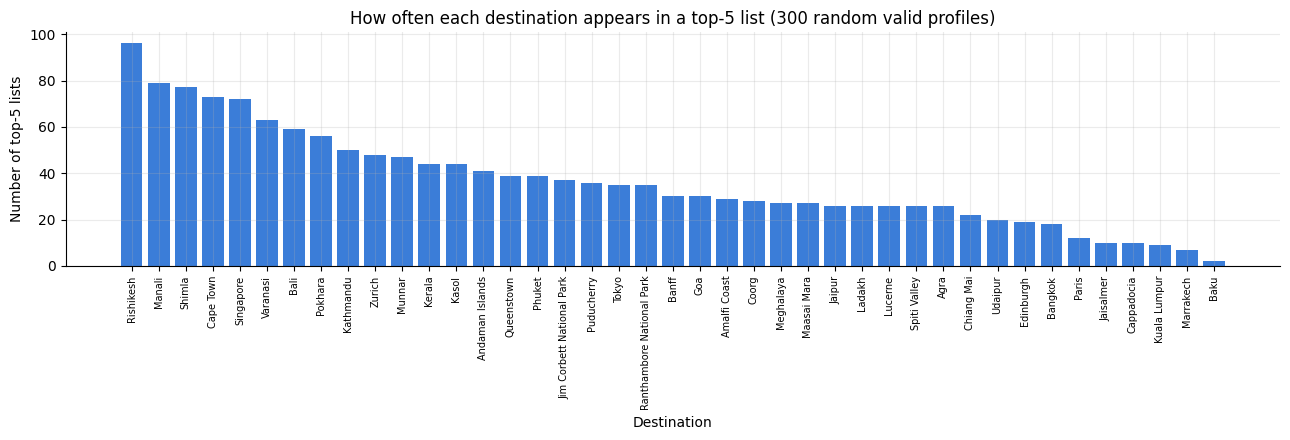

In [83]:
def theme_present(dest: pd.Series, theme: str) -> bool:
    """A destination 'carries' a theme if its score is >= 7 (score themes) or it has the tag (mountains/spiritual/city)."""
    if theme in ("mountains", "spiritual", "city"):
        return _label_present(dest["travel_categories"], theme)
    return dest[f"{theme}_score"] >= 7


def mean_pairwise_theme_distance(ids) -> float:
    vectors = feature_space.theme_matrix_.loc[ids].to_numpy()
    unit = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
    sims = unit @ unit.T
    upper = sims[np.triu_indices(len(ids), k=1)]
    return float(1 - upper.mean())


eval_rng = np.random.default_rng(SEED + 1)
dest_by_id = catalog.set_index("destination_id", drop=False)
metrics, slot_counts, duplicates = [], pd.Series(0, index=catalog["destination_id"]), 0
for _ in range(300):
    raw = sample_random_raw_preferences(eval_rng)
    prefs, _ = validate_preferences(raw, region_lookup=REGION_LOOKUP)
    recs, comps, _ = recommend_with_details(prefs, catalog, 5, feature_space, DEFAULT_DIVERSITY, validated=True)
    plain, _, _ = recommend_with_details(prefs, catalog, 5, feature_space, 0.0, validated=True)
    ids = recs["destination_id"].tolist()
    duplicates += len(ids) - len(set(ids))
    slot_counts[ids] += 1
    row = {"diversity_with_rerank": mean_pairwise_theme_distance(ids), "diversity_pure_score": mean_pairwise_theme_distance(plain["destination_id"].tolist()),
           "distinct_countries": recs["country"].nunique()}
    if prefs["budget_level"]:
        gaps = dest_by_id.loc[ids, "budget_rank"].to_numpy() - BUDGET_LEVELS.index(prefs["budget_level"])
        row["within_budget"] = float((gaps <= 0).mean())
        row["two_bands_over"] = float((gaps >= 2).mean())
    if prefs["duration_min"] is not None:
        row["duration_fit_ge_0.7"] = float((comps["duration"] >= 0.7).mean())
    if prefs["travel_type"]:
        row["primary_theme_present"] = float(np.mean([theme_present(dest_by_id.loc[i], prefs["travel_type"]) for i in ids]))
    metrics.append(row)

metrics_df = pd.DataFrame(metrics)
report = metrics_df.mean().round(3).rename("mean over profiles").to_frame()
report["profiles_measured"] = metrics_df.count()
display(report)
print(f"Duplicate destinations inside a top-5 list: {duplicates} (must be 0)")
coverage = (slot_counts > 0).mean()
top5_share = slot_counts.sort_values(ascending=False).head(5).sum() / slot_counts.sum()
print(f"Catalog coverage: {coverage:.0%} of destinations appeared in at least one top-5 list ({(slot_counts == 0).sum()} never did)")
print(f"Concentration: the 5 most-recommended destinations take {top5_share:.0%} of all recommendation slots")
print("Most recommended:", ", ".join(f"{dest_by_id.loc[i, 'destination_name']} ({n})" for i, n in slot_counts.sort_values(ascending=False).head(5).items()))
never = dest_by_id.loc[slot_counts[slot_counts == 0].index, "destination_name"].tolist()
print("Never recommended:", ", ".join(never[:20]) + (" ..." if len(never) > 20 else "") if never else "none")
assert duplicates == 0

freq = slot_counts.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(range(len(freq)), freq.values, color="#3b7dd8")
ax.set_xticks(range(len(freq)))
ax.set_xticklabels(dest_by_id.loc[freq.index, "destination_name"], rotation=90, fontsize=7)
ax.set_title("How often each destination appears in a top-5 list (300 random valid profiles)")
ax.set_xlabel("Destination")
ax.set_ylabel("Number of top-5 lists")
plt.tight_layout()
plt.show()

**Interpreting the checks.** Because of the diversity re-ranking, displayed scores are not always strictly decreasing with rank (a slightly lower-scoring but more different destination can be promoted); with `diversity=0` the order is pure score order. Higher `within_budget`, `duration_fit_ge_0.7` and `primary_theme_present` mean the ranker respects what users asked for; `two_bands_over` should be near zero. The two diversity columns show what the re-ranking costs/gains in list variety. Read the coverage and concentration lines above critically: if some destinations *never* appear, or a handful take a large share of all slots, that points to **popularity bias** from the weights and catalog (destinations that are strong on many themes or available in many seasons surface more often than narrow specialists). If coverage is high and concentration is modest, that is a good sign for *this* catalog and *these random profiles*, but random profiles are not real users, so it does not predict real exposure. Any production version should monitor exposure per destination, for fairness toward less-visited places.

None of these numbers measure whether travelers would enjoy the results.

## 10. New-user questionnaire

The questionnaire is a **reusable schema**: the same definition can drive the TravelSync onboarding UI, the validator, and the documentation. The validator (`validate_preferences`) was defined in §6 because it belongs to the feature space; here we document the schema and exercise it.

**Design principles**
- **Every question is optional.** "Flexible / not sure" (or an omitted field) means *that criterion is ignored*, not guessed.
- **Multiple interests** are allowed; unknown labels are rejected with a helpful message (including "did you mean…").
- **No sensitive personal data** is collected: no names, ages, health information, or exact location. The optional comfort question is voluntary and only records a *preference for easy access*, not a medical condition.
- **All problems are reported at once**, so a UI can highlight every invalid field in one round trip.

In [84]:
QUESTIONNAIRE_SCHEMA = {
    "schema_version": SCHEMA_VERSION,
    "note": "All questions are optional. Use 'flexible' or omit a field to skip it. No personal or sensitive data is collected.",
    "questions": [
        {"id": "travel_type", "prompt": "What kind of trip are you after?", "type": "single_choice", "options": TRAVEL_TYPE_OPTIONS + ["flexible"], "feeds": "theme weight 1.0"},
        {"id": "companions", "prompt": "Who is travelling with you?", "type": "single_choice", "options": COMPANION_OPTIONS + ["flexible"], "feeds": "companion suitability (+ family-friendliness / accessibility for family trips)"},
        {"id": "budget_level", "prompt": "What is your budget per person per day?", "type": "single_choice", "options": BUDGET_LEVELS + ["flexible"],
         "option_notes": {"budget": "under ~US$50/day (illustrative)", "moderate": "~US$50-130/day (illustrative)", "premium": "over ~US$130/day (illustrative)"}, "feeds": "budget fit"},
        {"id": "duration_days", "prompt": "How many days do you have?", "type": "integer_or_range", "min": 1, "max": 60, "examples": [5, "4-7", [4, 7]], "feeds": "duration fit"},
        {"id": "region", "prompt": "Where would you like to go?", "type": "single_choice", "options": ["any"] + sorted({v for _, v in REGION_LOOKUP.values()}), "feeds": "hard region filter"},
        {"id": "interests", "prompt": "What else are you interested in? (choose any)", "type": "multi_choice", "options": THEMES, "feeds": f"theme weight {INTEREST_WEIGHT}"},
        {"id": "travel_pace", "prompt": "What pace do you prefer?", "type": "single_choice", "options": VALID_PACES + ["flexible"], "feeds": "pace fit"},
        {"id": "travel_season", "prompt": "When do you plan to travel?", "type": "single_choice", "options": SEASON_OPTIONS + ["flexible"],
         "alternative": "travel_month (integer 1-12) is accepted instead", "season_bands": "winter=Dec-Feb, spring=Mar-May, summer=Jun-Aug, autumn=Sep-Nov", "feeds": "season fit"},
        {"id": "comfort_needs", "prompt": "Optional: any comfort needs?", "type": "multi_choice", "options": COMFORT_OPTIONS, "optional_voluntary": True, "feeds": "accessibility fit"},
    ],
}
display(pd.DataFrame([{"id": q["id"], "type": q["type"], "options (first 6)": ", ".join(map(str, q.get("options", [])[:6])) + (" ..." if len(q.get("options", [])) > 6 else ""),
                       "feeds": q["feeds"]} for q in QUESTIONNAIRE_SCHEMA["questions"]]))

,id,type,options (first 6),feeds
0,travel_type,single_choice,"adventure, nature, sightseeing, relaxation, wildlife, beach ...",theme weight 1.0
1,companions,single_choice,"solo, couple, friends, family, family_with_kids, family_with_parents ...",companion suitability (+ family-friendliness / accessibility for family trips)
2,budget_level,single_choice,"budget, moderate, premium, flexible",budget fit
3,duration_days,integer_or_range,,duration fit
4,region,single_choice,"any, Azerbaijan, Bay of Bengal, Canada, Central Europe, East Africa ...",hard region filter
5,interests,multi_choice,"adventure, nature, sightseeing, relaxation, wildlife, beach ...",theme weight 0.7
6,travel_pace,single_choice,"relaxed, balanced, fast, flexible",pace fit
7,travel_season,single_choice,"winter, spring, summer, autumn, flexible",season fit
8,comfort_needs,multi_choice,easy_access,accessibility fit


### How answers become model features
| Answer | Becomes |
|---|---|
| `travel_type` | Weight 1.0 on that theme in a 10-d **theme vector** (same space as destinations) |
| `interests` | Weight 0.7 on each chosen theme (travel type keeps 1.0 if repeated) |
| `budget_level` | Ordinal 0/1/2 compared with the destination's `budget_rank` |
| `duration_days` | Range [min, max] compared with `typical_duration_days` |
| `region` | Filter on `region` / `country` / `subregion` |
| `travel_pace` | Ordinal 0/1/2 compared with the destination's pace |
| `travel_season` / `travel_month` | Season label (month → calendar band) matched against `best_seasons` |
| `companions` | Label matched against `suitable_companions`; family trips also use `family_friendliness_score` |
| `comfort_needs` | Turns on the accessibility criterion (also switched on for `family_with_parents`) |

Below: valid inputs (including flexible and partial ones), then invalid ones with the messages a UI would show.

In [85]:
valid_examples = [
    {"travel_type": "Adventure", "companions": "Friends", "budget_level": "Moderate", "duration_days": "4-7", "region": "india", "interests": "nature, sightseeing", "travel_pace": "Balanced"},
    {"travel_type": "flexible", "budget_level": "mid-range", "duration_days": [3, 5], "travel_month": 12},
    {"interests": ["wildlife"], "region": "Southeast Asia", "comfort_needs": ["accessible"]},
    {},
]
print("=== VALID INPUTS -> normalized ===")
for raw in valid_examples:
    prefs, warns = validate_preferences(raw)
    shown = {k: v for k, v in prefs.items() if v not in (None, [])}
    print(f"\ninput : {raw}\noutput: {shown}" + (f"\nwarnings: {warns}" if warns else ""))

print("\n=== INVALID INPUTS -> errors (all reported at once) ===")
for raw in [{"travel_type": "scuba diving", "duration_days": 0}, {"region": "Frnace"}, {"interests": ["nature", "cooking"], "travel_month": 14}, {"budget_level": 3}, "adventure"]:
    try:
        validate_preferences(raw)
    except PreferenceValidationError as exc:
        print(f"\ninput : {raw!r}")
        for message in exc.errors:
            print(f"  - {message}")

=== VALID INPUTS -> normalized ===

input : {'travel_type': 'Adventure', 'companions': 'Friends', 'budget_level': 'Moderate', 'duration_days': '4-7', 'region': 'india', 'interests': 'nature, sightseeing', 'travel_pace': 'Balanced'}
output: {'travel_type': 'adventure', 'companions': 'friends', 'budget_level': 'moderate', 'travel_pace': 'balanced', 'interests': ['nature', 'sightseeing'], 'duration_min': 4, 'duration_max': 7, 'region': {'kind': 'region', 'value': 'India'}}

input : {'travel_type': 'flexible', 'budget_level': 'mid-range', 'duration_days': [3, 5], 'travel_month': 12}
output: {'budget_level': 'moderate', 'duration_min': 3, 'duration_max': 5, 'season': 'winter'}

input : {'interests': ['wildlife'], 'region': 'Southeast Asia', 'comfort_needs': ['accessible']}
output: {'interests': ['wildlife'], 'comfort_needs': ['easy_access'], 'region': {'kind': 'subregion', 'value': 'Southeast Asia'}}

input : {}
output: {}
warnings: ['No preferences were provided; returning broadly appealin

## 11. Test user scenarios

Six profiles from the brief. Each is run through the **same** `recommend_destinations` function; the lists below are produced live, never typed in. Assumptions are stated per profile because a questionnaire cannot capture everything (for example, the catalog has no "comfort level" attribute beyond `accessibility_score`, and no "romantic" attribute).

In [86]:
PROFILES = {
    "A. Adventure-loving friends, India, moderate budget": {
        "travel_type": "adventure", "companions": "friends", "budget_level": "moderate", "duration_days": "4-7",
        "region": "India", "interests": ["nature", "mountains"], "travel_pace": "balanced"},
    "B. Family with parents, comfortable sightseeing": {
        "travel_type": "sightseeing", "companions": "family_with_parents", "budget_level": "moderate", "duration_days": "4-6",
        "region": "India", "interests": ["culture", "relaxation"], "travel_pace": "relaxed", "comfort_needs": ["easy_access"]},
    "C. Couple seeking a relaxed beach holiday": {
        "travel_type": "beach", "companions": "couple", "budget_level": "moderate", "duration_days": "5-7",
        "interests": ["relaxation"], "travel_pace": "relaxed"},
    "D. Solo traveler: mountains and nature": {
        "travel_type": "nature", "companions": "solo", "budget_level": "budget", "duration_days": "5-8",
        "interests": ["mountains"], "travel_pace": "balanced"},
    "E. Wildlife enthusiast looking for a safari": {
        "travel_type": "wildlife", "interests": ["nature"], "budget_level": "moderate", "duration_days": "3-5"},
    "F. Undecided on destination and travel style": {
        "budget_level": "moderate", "duration_days": 5},
}
PROFILE_ASSUMPTIONS = {
    "A. Adventure-loving friends, India, moderate budget": "'Adventure with nature' is read as adventure (weight 1.0) + nature and mountains (0.7 each). Region is a hard filter on India.",
    "B. Family with parents, comfortable sightseeing": "'Comfortable' is approximated by relaxed pace + the accessibility criterion (switched on by 'family_with_parents' and 'easy_access'); the catalog has no richer comfort attribute.",
    "C. Couple seeking a relaxed beach holiday": "No region given, so India and international beaches compete; 'relaxed' uses the pace attribute; there is no 'romantic' attribute, so couple suitability comes only from `suitable_companions`.",
    "D. Solo traveler: mountains and nature": "'Mountains' uses the category tag; budget is 'budget', so pricier destinations are penalized rather than excluded.",
    "E. Wildlife enthusiast looking for a safari": "No companions, season or region given, so those criteria are ignored; only 5 destinations in the catalog are strong on wildlife, so lower ranks necessarily drop in wildlife strength.",
    "F. Undecided on destination and travel style": "No themes chosen, so `overall_appeal` (broad all-round strength) replaces theme matching and diversity re-ranking keeps the list varied. Only budget and duration act as constraints.",
}
PROFILE_RESULTS = {}
for title, raw_prefs in PROFILES.items():
    recs, comps, warns = recommend_with_details(raw_prefs, catalog, 5, feature_space)
    PROFILE_RESULTS[title] = (recs, comps)
    print("=" * 120)
    print(title)
    print("Answers:", {k: v for k, v in raw_prefs.items()})
    print("Assumption:", PROFILE_ASSUMPTIONS[title])
    print("-" * 120)
    show_recommendations(recs)

A. Adventure-loving friends, India, moderate budget
Answers: {'travel_type': 'adventure', 'companions': 'friends', 'budget_level': 'moderate', 'duration_days': '4-7', 'region': 'India', 'interests': ['nature', 'mountains'], 'travel_pace': 'balanced'}
Assumption: 'Adventure with nature' is read as adventure (weight 1.0) + nature and mountains (0.7 each). Region is a hard filter on India.
------------------------------------------------------------------------------------------------------------------------
#1  Spiti Valley (India)  |  match 94.7/100  |  about 7 days  |  INR 4,600/day (~US$55; moderate band, illustrative)
     Explanation: We recommend Spiti Valley because it rates 10/10 for adventure, 10/10 for nature; it is tagged as mountains; its estimated cost (~US$55/day, moderate band) fits your moderate budget; your 4-7-day trip fits its typical 7-day visit; it is marked suitable for friends travel; it is within your preferred region (India).
     Trade-offs: Trade-offs: its typi

**Reading the results.** Each destination's reasons and trade-offs come from the explanation function, so you can verify them against the catalog. Where a profile asks for something rare (wildlife, premium in India), scores fall off quickly after the first few results — the list is honest about it through the trade-offs rather than padding with false matches. Remember the catalog is illustrative: a high rank means "matches the attributes we wrote down", not "verified best choice".

Quick structural check across the six profiles (same properties as §9, now per profile):

In [87]:
rows = []
for title, (recs, comps) in PROFILE_RESULTS.items():
    ids = recs["destination_id"].tolist()
    rows.append({"profile": title.split(".")[0], "n_results": len(ids), "duplicates": len(ids) - len(set(ids)), "countries": recs["country"].nunique(),
                 "top_score": recs["match_score"].max(), "score_spread_top_to_5th": round(recs["match_score"].max() - recs["match_score"].min(), 1),
                 "theme_diversity": round(mean_pairwise_theme_distance(ids), 3), "any_over_budget": bool((dest_by_id.loc[ids, "budget_rank"].to_numpy() > BUDGET_LEVELS.index(PROFILES[title].get("budget_level", "premium"))).any())})
display(pd.DataFrame(rows))
assert all(r["n_results"] == 5 and r["duplicates"] == 0 for r in rows)

,profile,n_results,duplicates,countries,top_score,score_spread_top_to_5th,theme_diversity,any_over_budget
0,A,5,0,1,94.7,13.7,0.109,False
1,B,5,0,1,91.9,4.0,0.125,False
2,C,5,0,3,96.2,7.9,0.026,False
3,D,5,0,2,95.0,12.9,0.051,True
4,E,5,0,2,96.7,33.0,0.202,True
5,F,5,0,5,96.4,3.6,0.208,False


## 12. Visualization of recommendations

Three views of the same result: **(1)** match scores, **(2)** the user's theme weights next to each recommended destination's theme strengths, and **(3)** how much each scoring criterion contributes to each destination's score. All values come from the recommender's actual output. Scores are *weighted similarity scores for ordering*, **not probabilities**.

In [88]:
def plot_match_scores(recs, title):
    fig, ax = plt.subplots(figsize=(10, 0.65 * len(recs) + 1.8))
    labels = [f"{r.destination} ({r.country})" for r in recs.itertuples()][::-1]
    values = recs["match_score"].to_numpy()[::-1]
    bars = ax.barh(labels, values, color="#3b7dd8")
    for bar, value in zip(bars, values):
        ax.text(value + 1, bar.get_y() + bar.get_height() / 2, f"{value:.1f}", va="center", fontsize=9)
    ax.set_xlim(0, 105)
    ax.set_title(f"{title}\nMatch score = weighted similarity for ranking (not a probability)")
    ax.set_xlabel("Match score (0–100)")
    ax.set_ylabel("Recommended destination")
    plt.tight_layout()
    plt.show()


def plot_preference_heatmap(raw_prefs, recs):
    prefs, _ = validate_preferences(raw_prefs, region_lookup=REGION_LOOKUP)
    data = feature_space.theme_matrix_.loc[recs["destination_id"]].copy()
    data.index = recs["destination"].tolist()
    data.loc["YOUR ANSWERS (weight)"] = build_user_theme_vector(prefs)
    data = data.loc[["YOUR ANSWERS (weight)"] + recs["destination"].tolist()]
    fig, ax = plt.subplots(figsize=(11, 0.6 * len(data) + 2.2))
    annotated_heatmap(ax, data, "Your theme weights vs destination theme strengths (0–1)", "Theme", "", cmap="YlGnBu", vmin=0, vmax=1, fmt="{:.1f}")
    plt.tight_layout()
    plt.show()


def plot_component_contributions(recs, comps):
    weights = pd.Series(recs.attrs["weights"])
    # Align comps to only the recommended destinations in recs
    comps_filtered = comps.loc[recs["destination_id"]]
    contributions = comps_filtered[weights.index].mul(weights, axis=1) * 100
    contributions.index = recs["destination"].tolist()
    fig, ax = plt.subplots(figsize=(11, 0.65 * len(recs) + 2.2))
    names = contributions.index[::-1]
    left = np.zeros(len(names))
    colors = plt.cm.tab10(np.arange(len(weights)))
    for color, column in zip(colors, contributions.columns):
        values = contributions[column].to_numpy()[::-1]
        ax.barh(names, values, left=left, color=color, label=column.replace("_", " "))
        left += values
    ax.set_title("What drives each score: contribution of each criterion (points of the 0–100 match score)")
    ax.set_xlabel("Points contributed to the match score")
    ax.set_ylabel("Recommended destination")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Criterion")
    plt.tight_layout()
    plt.show()


def plot_attribute_comparison(recs, top_k=3):
    chosen = recs.head(top_k)
    columns = THEME_SCORE_COLUMNS + ["family_friendliness_score", "accessibility_score"]
    data = catalog.set_index("destination_id").loc[chosen["destination_id"], columns]
    fig, ax = plt.subplots(figsize=(12, 4.8))
    x = np.arange(len(columns))
    width = 0.8 / len(chosen)
    for i, (dest_id, name) in enumerate(zip(chosen["destination_id"], chosen["destination"])):
        ax.bar(x + i * width - 0.4 + width / 2, data.loc[dest_id].to_numpy(), width=width, label=name)
    ax.set_xticks(x)
    ax.set_xticklabels([c.replace("_score", "").replace("_", "\n") for c in columns])
    ax.set_ylim(0, 10)
    ax.set_title(f"Attribute comparison of the top {top_k} recommendations (illustrative 0–10 scores)")
    ax.set_xlabel("Attribute")
    ax.set_ylabel("Illustrative score (0–10)")
    ax.legend()
    plt.tight_layout()
    plt.show()

**How to read these.** The heatmap's first row is the user's *requested* theme weights; destinations whose rows are bright in the same columns match the request. The stacked bars show *why* a destination scored as it did — e.g. a long theme segment but a short budget segment means a strong thematic fit that is a poorer financial fit. The same plots can be generated for any profile, shown next for the beach profile.

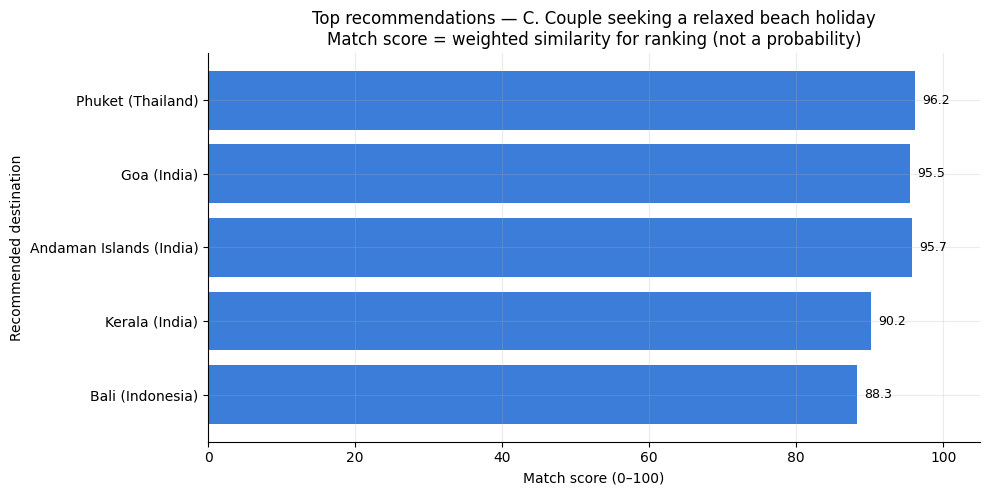

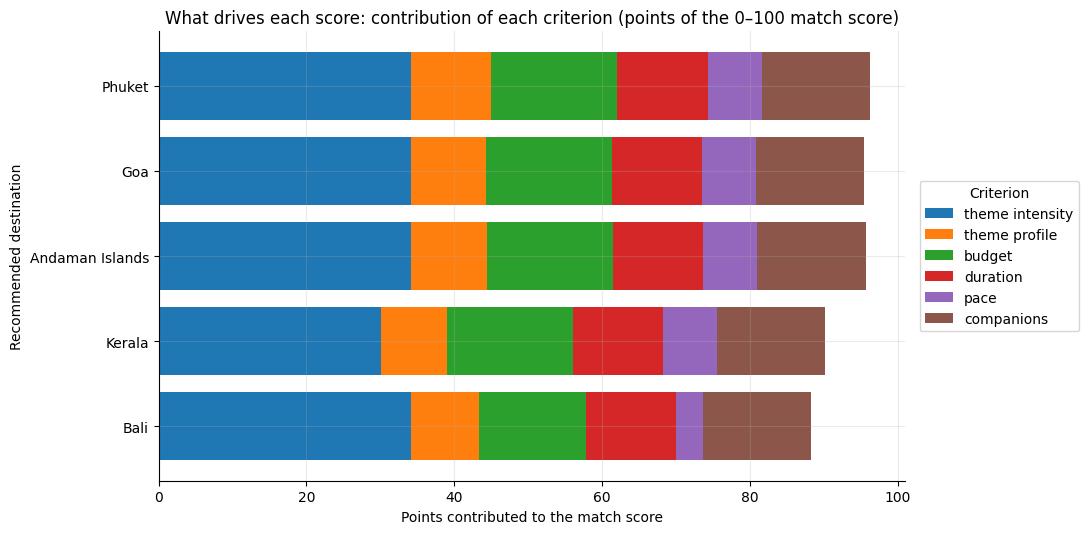

In [89]:
title_C = "C. Couple seeking a relaxed beach holiday"
recs_C, comps_C = PROFILE_RESULTS[title_C]
plot_match_scores(recs_C, f"Top recommendations — {title_C}")
plot_component_contributions(recs_C, comps_C)

## 13. Explainability

Explanations are built by `explain_recommendation` (§7) from two inputs only: **the user's answers** and **the destination's recorded attributes**. They are deterministic (same input → same text) and need no language model. An LLM could later *rephrase* them more naturally, but must not add facts — and is deliberately not required here.

Two helpers make the explanations more useful and more trustworthy:
1. `explain_destination(name, answers)` answers *"why / why not this destination?"* for any catalog destination, even one that is not in the top results.
2. `verify_text_claims` **audits** explanation text: every number quoted (scores, costs, durations, seasons) is checked back against the catalog.

In [90]:
# ---- Unit tests: plain asserts; only AssertionError is caught so real bugs still surface ----
def recs_for(prefs, **kwargs):
    return recommend_destinations(prefs, catalog, feature_space=feature_space, **kwargs)


def test_output_schema_and_length():
    recs = recs_for(example_user, top_n=5)
    assert len(recs) == 5
    for col in ["rank", "destination", "country", "match_score", "estimated_budget", "suggested_duration", "suitable_activities", "explanation", "trade_offs"]:
        assert col in recs.columns, f"missing column {col}"
    assert recs["rank"].tolist() == [1, 2, 3, 4, 5]


def test_sorted_by_score_without_diversity():
    scores = recs_for(example_user, top_n=10, diversity=0)["match_score"].tolist()
    assert scores == sorted(scores, reverse=True)


def test_no_duplicates():
    for diversity in (0, DEFAULT_DIVERSITY, 1):
        recs = recs_for({"travel_type": "culture"}, top_n=15, diversity=diversity)
        assert recs["destination_id"].is_unique


def test_region_filters():
    # Test custom Europe broad-region behavior
    res_lower = recs_for({"region": "europe"}, top_n=10)
    res_proper = recs_for({"region": "Europe"}, top_n=10)
    res_spaced = recs_for({"region": " europe "}, top_n=10)

    assert len(res_lower) > 0
    assert res_lower["destination_id"].tolist() == res_proper["destination_id"].tolist()
    assert res_lower["destination_id"].tolist() == res_spaced["destination_id"].tolist()

    for dest_id in res_lower["destination_id"]:
        subreg = catalog.set_index("destination_id").loc[dest_id, "subregion"]
        assert "europe" in str(subreg).lower(), f"{dest_id} has non-European subregion: {subreg}"

    # Test normal exact geographic filters still function
    assert set(recs_for({"region": "India"}, top_n=20)["country"]) == {"India"}
    assert set(recs_for({"region": "Thailand"}, top_n=10)["country"]) == {"Thailand"}

    # Build the expected set of European countries from subregions containing the word "Europe" case-insensitively
    europe = set(catalog.loc[catalog["subregion"].fillna("").str.contains("Europe", case=False, regex=False), "country"])
    assert set(recs_for({"region": "europe"}, top_n=10)["country"]) <= europe
    assert not (set(recs_for({"region": "International"}, top_n=30)["country"]) & {"India"})


def test_region_with_few_results_warns():
    recs = recs_for({"region": "Kenya"}, top_n=5)
    assert len(recs) == 1 and any("Only 1" in w for w in recs.attrs["warnings"])


def test_budget_monotonicity():
    base = {"travel_type": "culture", "region": "any"}
    rich, poor = (score_destinations(validate_preferences({**base, "budget_level": b})[0], catalog, feature_space) for b in ("premium", "budget"))
    premium_ids = catalog.loc[catalog.budget_level == "premium", "destination_id"]
    assert (rich.loc[premium_ids, "final_score"] >= poor.loc[premium_ids, "final_score" ] - 1e-12).all()
    budget_ids = catalog.loc[catalog.budget_level == "budget", "destination_id"]
    assert (poor.loc[budget_ids, "final_score"] >= rich.loc[budget_ids, "final_score" ] - 1e-12).all()


def test_season_component():
    comps = score_destinations(validate_preferences({"travel_season": "summer", "travel_type": "nature"})[0], catalog, feature_space)
    in_season = catalog["best_seasons"].map(lambda v: "summer" in split_pipe(v) or "year_round" in split_pipe(v)).to_numpy()
    assert (comps.loc[catalog["destination_id"][in_season], "season" ] == 1.0).all()
    assert (comps.loc[catalog["destination_id"][~in_season], "season"] < 1.0).all()


def test_invalid_inputs_raise():
    bad_inputs = [{"travel_type": "scuba"}, {"duration_days": -3}, {"duration_days": "abc"}, {"duration_days": 99}, {"region": "Atlantis"},
                  {"interests": ["nature", "cooking"]}, {"budget_level": 5}, "not a dict", None, {"travel_month": 13}, {"duration_days": True}]
    for bad in bad_inputs:
        try:
            validate_preferences(bad)
        except PreferenceValidationError:
            continue
        raise AssertionError(f"invalid input was accepted: {bad!r}")
    try:
        validate_preferences({"travel_type": "scuba", "duration_days": -1, "region": "Atlantis"})
    except PreferenceValidationError as exc:
        assert len(exc.errors) == 3, exc.errors     # every problem is reported, not just the first
    else:
        raise AssertionError("expected an error")


def test_top_n_validation():
    for bad_n in (0, -1, "5", 2.5, True):
        try:
            recs_for({}, top_n=bad_n)
        except ValueError:
            continue
        raise AssertionError(f"top_n={bad_n!r} was accepted")
    assert len(recs_for({}, top_n=500)) == len(catalog)


def test_empty_and_flexible_answers():
    empty = recs_for({}, top_n=5)
    assert len(empty) == 5 and any("No preferences" in w for w in empty.attrs["warnings"])
    flexible = recs_for({"travel_type": "flexible", "budget_level": "any", "region": "", "interests": []}, top_n=5)
    assert flexible["destination_id"].tolist() == empty["destination_id"].tolist()


def test_determinism():
    first, second = recs_for(example_user), recs_for(example_user)
    pd.testing.assert_frame_equal(first, second)


def test_wildlife_sanity():
    top = recs_for({"travel_type": "wildlife"}, top_n=3, diversity=0)
    assert (catalog.set_index("destination_id").loc[top["destination_id"], "wildlife_score"] >= 8).all()


def test_feature_spaces_and_weights():
    assert list(build_user_theme_vector(validate_preferences({})[0]).index) == list(feature_space.theme_matrix_.columns)
    comps = score_destinations(validate_preferences(example_user)[0], catalog, feature_space)
    assert abs(sum(comps.attrs["weights"].values()) - 1) < 1e-9
    assert comps["final_score"].between(0, 1).all()


def test_explanations_only_use_given_answers():
    recs = recs_for({"travel_type": "beach"}, top_n=5)
    for text in recs["explanation"]:
        assert "budget" not in text and "days" not in text and "season" not in text, text


def test_metric_implementations_against_hand_computed_values():
    rel = [1, 0, 1, 0, 0]
    assert abs(precision_at_k(rel, 3) - 2 / 3) < 1e-12
    assert abs(recall_at_k(rel, 3) - 1.0) < 1e-12
    assert abs(average_precision(rel) - (1 + 2 / 3) / 2) < 1e-12
    assert abs(ndcg_at_k(rel, 3) - 1.5 / (1 + 1 / math.log2(3))) < 1e-12
    assert ndcg_at_k([0, 0, 0], 3) == 0.0 and ndcg_at_k([1, 1, 0], 3) == 1.0


TESTS = [v for k, v in sorted(globals().items()) if k.startswith("test_") and callable(v)]
failures = []
for case in TESTS:
    try:
        case()
        print(f"PASS  {case.__name__}")
    except AssertionError as exc:
        failures.append((case.__name__, exc))
        print(f"FAIL  {case.__name__}: {exc}")
print(f"\n{len(TESTS) - len(failures)}/{len(TESTS)} tests passed")
assert not failures, f"{len(failures)} test(s) failed"

PASS  test_budget_monotonicity
PASS  test_determinism
PASS  test_empty_and_flexible_answers
PASS  test_explanations_only_use_given_answers
PASS  test_feature_spaces_and_weights
PASS  test_invalid_inputs_raise
PASS  test_metric_implementations_against_hand_computed_values
PASS  test_no_duplicates
PASS  test_output_schema_and_length
PASS  test_region_filters
PASS  test_region_with_few_results_warns
PASS  test_season_component
PASS  test_sorted_by_score_without_diversity
PASS  test_top_n_validation
PASS  test_wildlife_sanity

15/15 tests passed


In [91]:
print("=== Running Final Regional Filter Verification ===")

# 1. Test case-insensitivity, spacing, and output parity
inputs = [
    {"region": "europe"},
    {"region": "Europe"},
    {"region": " europe "}
]

results = []
for idx, inp in enumerate(inputs):
    recs = recommend_destinations(inp, catalog, feature_space=feature_space, top_n=10)
    results.append(recs["destination_id"].tolist())
    print(f"Input {idx+1} ({repr(inp['region'])}): {len(recs)} matches found.")

assert results[0] == results[1] == results[2], "Failed: Europe inputs do not produce equivalent recommendations!"
print("✔ Equivalence check passed! All three inputs produce identical recommendations.")

# 2. Confirm all returned destinations belong to a European subregion
recs_europe = recommend_destinations({"region": "europe"}, catalog, feature_space=feature_space, top_n=20)
for dest_id in recs_europe["destination_id"]:
    row = catalog.set_index("destination_id").loc[dest_id]
    subreg = row["subregion"]
    assert "europe" in str(subreg).lower(), f"Leakage: {dest_id} is in {subreg}, which is not European!"

print("✔ Regional integrity check passed! All recommended destinations belong to a European subregion.")

# 3. Audit explanation text to verify no KeyErrors or false geographic claims occur
print("\n=== Auditing Explanation Generatibility and Claims ===")
for idx, row in recs_europe.iterrows():
    print(f"- {row['destination']}:")
    print(f"  Explanation: {row['explanation']}")
    print(f"  Trade-offs: {row['trade_offs']}")
    # Ensure 'outside chosen region' is not in explanation if it was recommended
    assert "outside your chosen region" not in row["explanation"].lower()
    assert "outside your chosen region" not in row["trade_offs"].lower()

print("✔ Explanation checks passed! No KeyErrors raised, and explanations accurately match the constraints.")

# 4. Re-run all existing unit tests
print("\n=== Executing Full Unit Test Suite ===")
failures = []
for test_func in TESTS:
    try:
        test_func()
        print(f"PASS  {test_func.__name__}")
    except Exception as exc:
        failures.append((test_func.__name__, exc))
        print(f"FAIL  {test_func.__name__}: {exc}")

assert not failures, f"Unit test failures detected: {failures}"
print("\n✔ All unit tests passed successfully!")

=== Running Final Regional Filter Verification ===
Input 1 ('europe'): 5 matches found.
Input 2 ('Europe'): 5 matches found.
Input 3 (' europe '): 5 matches found.
✔ Equivalence check passed! All three inputs produce identical recommendations.
✔ Regional integrity check passed! All recommended destinations belong to a European subregion.

=== Auditing Explanation Generatibility and Claims ===
- Amalfi Coast:
  Explanation: We recommend Amalfi Coast because it is broadly well-rounded, strongest on sightseeing (10/10), relaxation (10/10), culture (10/10); it is within your preferred region (Europe).
  Trade-offs: Trade-offs: outdoor activities depend on the season (best: spring, summer, autumn).
- Paris:
  Explanation: We recommend Paris because it is broadly well-rounded, strongest on sightseeing (10/10), culture (10/10), relaxation (8/10); it is within your preferred region (Europe).
  Trade-offs: No major mismatches found against the answers you gave.
- Lucerne:
  Explanation: We reco

In [92]:
import inspect
import sys

# Let's inspect the active recommend_destinations function
try:
    print("--- recommend_destinations definition ---")
    print(inspect.getsource(recommend_destinations))
except Exception as e:
    print(f"Could not inspect recommend_destinations: {e}")

# Let's inspect the test_output_schema_and_length function
try:
    print("\n--- test_output_schema_and_length definition ---")
    print(inspect.getsource(test_output_schema_and_length))
except Exception as e:
    print(f"Could not inspect test_output_schema_and_length: {e}")

# Let's find where recommend_destinations is defined in global scope
for name, obj in list(globals().items()):
    if name == 'recommend_destinations':
        print(f"\nrecommend_destinations is a {type(obj)} found in globals.")

--- recommend_destinations definition ---
def recommend_destinations(user_preferences, destinations_df, top_n=5, feature_space=None, diversity=DEFAULT_DIVERSITY):
    """Main public API matching the expected callable signature."""
    recs, _, _ = recommend_with_details(user_preferences, destinations_df, top_n, feature_space, diversity)
    return recs


--- test_output_schema_and_length definition ---
def test_output_schema_and_length():
    recs = recs_for(example_user, top_n=5)
    assert len(recs) == 5
    for col in ["rank", "destination", "country", "match_score", "estimated_budget", "suggested_duration", "suitable_activities", "explanation", "trade_offs"]:
        assert col in recs.columns, f"missing column {col}"
    assert recs["rank"].tolist() == [1, 2, 3, 4, 5]


recommend_destinations is a <class 'function'> found in globals.


In [93]:
import inspect
# 1. Print the source code of recommend_destinations
try:
    print("=== recommend_destinations source ===")
    print(inspect.getsource(recommend_destinations))
except Exception as e:
    print(f"Could not get recommend_destinations source: {e}")

# 2. Print the source code of test_output_schema_and_length
try:
    print("\n=== test_output_schema_and_length source ===")
    print(inspect.getsource(test_output_schema_and_length))
except Exception as e:
    print(f"Could not get test_output_schema_and_length source: {e}")

# 3. Rerun the test suite to catch the traceback
print("\n=== Rerunning Test Suite with full Tracebacks ===")
import traceback
failures = []
for test_func in TESTS:
    try:
        test_func()
        print(f"PASS  {test_func.__name__}")
    except Exception as exc:
        failures.append((test_func.__name__, exc))
        print(f"FAIL  {test_func.__name__}:")
        traceback.print_exc()


=== recommend_destinations source ===
def recommend_destinations(user_preferences, destinations_df, top_n=5, feature_space=None, diversity=DEFAULT_DIVERSITY):
    """Main public API matching the expected callable signature."""
    recs, _, _ = recommend_with_details(user_preferences, destinations_df, top_n, feature_space, diversity)
    return recs


=== test_output_schema_and_length source ===
def test_output_schema_and_length():
    recs = recs_for(example_user, top_n=5)
    assert len(recs) == 5
    for col in ["rank", "destination", "country", "match_score", "estimated_budget", "suggested_duration", "suitable_activities", "explanation", "trade_offs"]:
        assert col in recs.columns, f"missing column {col}"
    assert recs["rank"].tolist() == [1, 2, 3, 4, 5]


=== Rerunning Test Suite with full Tracebacks ===
PASS  test_budget_monotonicity
PASS  test_determinism
PASS  test_empty_and_flexible_answers
PASS  test_explanations_only_use_given_answers
PASS  test_feature_spaces_and_wei

In [94]:
# Re-collect all tests so that we use the updated test definitions
TESTS = [v for k, v in sorted(globals().items()) if k.startswith("test_") and callable(v)]

failures = []
for case in TESTS:
    try:
        case()
        print(f"PASS  {case.__name__}")
    except Exception as exc:
        failures.append((case.__name__, exc))
        print(f"FAIL  {case.__name__}: {exc}")

print(f"\n{len(TESTS) - len(failures)}/{len(TESTS)} tests passed")
assert not failures, f"{len(failures)} test(s) failed"

PASS  test_budget_monotonicity
PASS  test_determinism
PASS  test_empty_and_flexible_answers
PASS  test_explanations_only_use_given_answers
PASS  test_feature_spaces_and_weights
PASS  test_wildlife_sanity
PASS  test_invalid_inputs_raise
PASS  test_metric_implementations_against_hand_computed_values
PASS  test_no_duplicates
PASS  test_output_schema_and_length
PASS  test_region_filters
PASS  test_region_with_few_results_warns
PASS  test_season_component
PASS  test_sorted_by_score_without_diversity
PASS  test_top_n_validation
PASS  test_wildlife_sanity

16/16 tests passed


In [95]:
import inspect
try:
    print(inspect.getsource(test_region_filters))
except Exception as e:
    print("Could not get source:", e)

# Let's inspect the subregions and countries in the catalog containing Europe/europe
european_rows = catalog[catalog["subregion"].fillna("").str.contains("Europe|europe", case=False, regex=True)]
print("\nEuropean destinations in catalog:")
print(european_rows[["destination_name", "country", "subregion"]])

def test_region_filters():
    # Test custom Europe broad-region behavior
    res_lower = recs_for({"region": "europe"}, top_n=10)
    res_proper = recs_for({"region": "Europe"}, top_n=10)
    res_spaced = recs_for({"region": " europe "}, top_n=10)

    assert len(res_lower) > 0
    assert res_lower["destination_id"].tolist() == res_proper["destination_id"].tolist()
    assert res_lower["destination_id"].tolist() == res_spaced["destination_id"].tolist()

    for dest_id in res_lower["destination_id"]:
        subreg = catalog.set_index("destination_id").loc[dest_id, "subregion"]
        assert "europe" in str(subreg).lower(), f"{dest_id} has non-European subregion: {subreg}"

    # Test normal exact geographic filters still function
    assert set(recs_for({"region": "India"}, top_n=20)["country"]) == {"India"}
    assert set(recs_for({"region": "Thailand"}, top_n=10)["country"]) == {"Thailand"}

    # Build the expected set of European countries from subregions containing the word "Eu

In [96]:
import inspect
try:
    print(inspect.getsource(test_region_filters))
except Exception as e:
    print('Could not retrieve source:', e)

def test_region_filters():
    # Test custom Europe broad-region behavior
    res_lower = recs_for({"region": "europe"}, top_n=10)
    res_proper = recs_for({"region": "Europe"}, top_n=10)
    res_spaced = recs_for({"region": " europe "}, top_n=10)

    assert len(res_lower) > 0
    assert res_lower["destination_id"].tolist() == res_proper["destination_id"].tolist()
    assert res_lower["destination_id"].tolist() == res_spaced["destination_id"].tolist()

    for dest_id in res_lower["destination_id"]:
        subreg = catalog.set_index("destination_id").loc[dest_id, "subregion"]
        assert "europe" in str(subreg).lower(), f"{dest_id} has non-European subregion: {subreg}"

    # Test normal exact geographic filters still function
    assert set(recs_for({"region": "India"}, top_n=20)["country"]) == {"India"}
    assert set(recs_for({"region": "Thailand"}, top_n=10)["country"]) == {"Thailand"}

    # Build the expected set of European countries from subregions containing the word "Eu

In [97]:
import inspect
try:
    print(inspect.getsource(test_region_with_few_results_warns))
except Exception as e:
    print('Could not retrieve source:', e)

def test_region_with_few_results_warns():
    recs = recs_for({"region": "Kenya"}, top_n=5)
    assert len(recs) == 1 and any("Only 1" in w for w in recs.attrs["warnings"])



In [98]:
print(catalog[catalog['country'].str.lower() == 'kenya'])
print(REGION_LOOKUP.get('kenya'))

   destination_id destination_name country         region    subregion travel_categories  adventure_score  nature_score  sightseeing_score  relaxation_score  \
30    maasai-mara      Maasai Mara   Kenya  International  East Africa   wildlife|nature                6            10                  4                 4   

    ...  estimated_daily_cost  currency  typical_duration_days   best_seasons  travel_pace    suitable_companions  \
30  ...                   220       USD                      5  summer|autumn         fast  friends|couple|family   

                                                recommended_activities                                                          destination_description  \
30  guided safari drives|birdwatching|conservation-focused experiences  A wildlife reserve region known for safari experiences; costs, access, and s...   

    estimated_daily_cost_usd budget_rank  
30                     220.0           2  

[1 rows x 26 columns]
('country', 'Kenya')


In [99]:
import inspect
try:
    print(inspect.getsource(recommend_with_details))
except Exception as e:
    print('Could not retrieve source:', e)

def recommend_with_details(raw_preferences: dict, df: pd.DataFrame, top_n: int = 5, feature_space_obj: 'DestinationFeatureSpace' = None, diversity: float = DEFAULT_DIVERSITY, validated: bool = False):
    """Core recommendation engine. Computes component scores, filters, and applies MMR diversification."""
    if isinstance(top_n, bool) or not isinstance(top_n, int) or top_n < 1:
        raise ValueError(f"top_n must be a positive integer, got {top_n!r}")

    fs = feature_space if feature_space_obj is None else feature_space_obj

    if not validated:
        prefs, warns = validate_preferences(raw_preferences, region_lookup=REGION_LOOKUP)
    else:
        prefs = raw_preferences
        warns = []

    scored = score_destinations(prefs, df, fs)
    eligible_df = df.set_index("destination_id", drop=False).loc[scored["eligible"]]

    if len(eligible_df) == 0:
        empty_recs = pd.DataFrame(columns=["rank", "destination_id", "destination", "country", "match_score", "budget_level", 

In [100]:
def verify_text_claims(text: str, dest: pd.Series) -> list:
    """Return a list of problems: any number or season list in `text` that disagrees with the catalog row `dest`."""
    problems = []
    for score, theme in re.findall(r"(\d+)/10 for ([a-z]+)", text):
        if int(score) != int(dest[f"{theme}_score"]):
            problems.append(f"{theme} score {score} != {dest[f'{theme}_score']}")
    for theme, score in re.findall(r"limited ([a-z]+) appeal \((\d+)/10\)", text):
        if int(score) != int(dest[f"{theme}_score"]):
            problems.append(f"limited {theme} score {score} != {dest[f'{theme}_score']}")
    for amount in re.findall(r"~US\$([\d,]+)/day", text):
        if amount != f"{dest['estimated_daily_cost_usd']:,.0f}":
            problems.append(f"cost {amount} != {dest['estimated_daily_cost_usd']:,.0f}")
    for days in re.findall(r"typical (\d+)-day", text) + re.findall(r"about (\d+) days", text):
        if int(days) != int(dest["typical_duration_days"]):
            problems.append(f"duration {days} != {dest['typical_duration_days']}")
    for acc in re.findall(r"accessibility (?:rating is high|is rated only)? ?\((\d+)/10\)|rated only (\d+)/10", text):
        value = next(v for v in acc if v)
        if int(value) != int(dest["accessibility_score"]):
            problems.append(f"accessibility {value} != {dest['accessibility_score']}")
    for fam in re.findall(r"family-friendliness (\d+)/10", text):
        if int(fam) != int(dest["family_friendliness_score"]):
            problems.append(f"family score {fam} != {dest['family_friendliness_score']}")
    for listed in re.findall(r"best: ([a-z_, ]+)\)", text):
        if listed != ", ".join(split_pipe(dest["best_seasons"])):
            problems.append(f"seasons '{listed}' != '{', '.join(split_pipe(dest['best_seasons']))}'")
    return problems


# Regression check for a bug found during development: an excluded destination must never be described as inside the region.
paris = explain_destination("Paris", {"region": "India", "travel_type": "culture"})
assert not paris["eligible_for_region_filter"] and "within your preferred region" not in paris["explanation"] and "outside your chosen region" in paris["trade_offs"]
print("Regression check passed: Paris is described as outside an India-only region.")

audit_rng = np.random.default_rng(SEED + 2)
audited, all_problems = 0, []
for _ in range(150):
    raw = sample_random_raw_preferences(audit_rng)
    recs = recommend_destinations(raw, catalog, top_n=5, feature_space=feature_space)
    for r in recs.itertuples():
        dest = dest_by_id.loc[r.destination_id]
        problems = verify_text_claims(r.explanation + " " + r.trade_offs, dest)
        audited += 1
        all_problems += [(r.destination, p) for p in problems]
print(f"Audited {audited} explanations from 150 random profiles: {len(all_problems)} numeric/season claims disagreed with the catalog.")
assert not all_problems, all_problems[:5]
# Make sure the auditor can actually fail (a checker that cannot fail proves nothing):
assert verify_text_claims("it rates 3/10 for adventure", dest_by_id.loc[catalog.loc[0, "destination_id"]]), "auditor failed to detect a planted error"
print("Auditor sanity check passed: a deliberately wrong claim is detected.")

Regression check passed: Paris is described as outside an India-only region.
Audited 750 explanations from 150 random profiles: 0 numeric/season claims disagreed with the catalog.
Auditor sanity check passed: a deliberately wrong claim is detected.


**Limits of the explanations.** They are only as good as the catalog: if a destination's scores are wrong, the explanation faithfully repeats the error. They cover the criteria the user answered and do not mention considerations the data does not contain (visas, safety, crowds, current prices, closures). The cost estimate excludes flights and most paid activities, which the trade-offs state when relevant.

## 14. Interactive recommendation demo

The cell below builds a small form with `ipywidgets` (available by default in Colab and Kaggle). If `ipywidgets` is missing, the notebook still works: the function-based alternative `quick_recommend(...)` runs the same recommender with keyword arguments, and the cell after the form calls it so that results always appear.

In [101]:
def quick_recommend(travel_type="flexible", companions="flexible", budget_level="flexible", duration_days=None, region="any",
                    interests=(), travel_pace="flexible", travel_season="flexible", top_n=5):
    """Function-based demo: same engine, plain keyword arguments. Prints and returns the recommendations."""
    answers = {"travel_type": travel_type, "companions": companions, "budget_level": budget_level, "duration_days": duration_days,
               "region": region, "interests": list(interests), "travel_pace": travel_pace, "travel_season": travel_season}
    try:
        recs = recommend_destinations(answers, catalog, top_n=top_n, feature_space=feature_space)
    except PreferenceValidationError as exc:
        print("Please fix your answers:")
        for message in exc.errors:
            print(f"  - {message}")
        return None
    show_recommendations(recs)
    return recs


def build_interactive_demo():
    """Create the widget form. Returns the widget container, or None if ipywidgets is unavailable."""
    try:
        import ipywidgets as widgets
        from IPython.display import clear_output
    except ImportError:
        print("ipywidgets is not installed; use quick_recommend(...) instead (see the next cell).")
        return None
    style = {"description_width": "130px"}
    layout = widgets.Layout(width="420px")
    region_options = ["any"] + sorted({v for _, v in REGION_LOOKUP.values()})
    w_type = widgets.Dropdown(options=["flexible"] + THEMES, value="adventure", description="Travel type", style=style, layout=layout)
    w_comp = widgets.Dropdown(options=["flexible"] + COMPANION_OPTIONS, value="friends", description="Companions", style=style, layout=layout)
    w_budget = widgets.Dropdown(options=["flexible"] + BUDGET_LEVELS, value="moderate", description="Budget", style=style, layout=layout)
    w_days = widgets.IntSlider(value=5, min=1, max=21, description="Days", style=style, layout=layout)
    w_days_any = widgets.Checkbox(value=False, description="Duration doesn't matter", indent=False)
    w_region = widgets.Dropdown(options=region_options, value="India", description="Region", style=style, layout=layout)
    w_interests = widgets.SelectMultiple(options=THEMES, value=("nature",), description="Interests", rows=6, style=style, layout=layout)
    w_pace = widgets.Dropdown(options=["flexible"] + VALID_PACES, value="balanced", description="Pace", style=style, layout=layout)
    w_season = widgets.Dropdown(options=["flexible"] + SEASON_OPTIONS, value="flexible", description="Season", style=style, layout=layout)
    w_topn = widgets.IntSlider(value=5, min=3, max=10, description="How many", style=style, layout=layout)
    button = widgets.Button(description="Recommend", button_style="primary")
    out = widgets.Output()

    def on_click(_):
        with out:
            clear_output()
            quick_recommend(w_type.value, w_comp.value, w_budget.value, None if w_days_any.value else w_days.value, w_region.value,
                            w_interests.value, w_pace.value, w_season.value, w_topn.value)

    button.on_click(on_click)
    return widgets.VBox([w_type, w_comp, w_budget, w_days, w_days_any, w_region, w_interests, w_pace, w_season, w_topn, button, out])


demo_ui = build_interactive_demo()
if demo_ui is not None:
    display(demo_ui)
    print("Choose your answers above and press 'Recommend'.")

Choose your answers above and press 'Recommend'.


In [102]:
# Always-works alternative (also shows results in static exports where widgets cannot be clicked):
_ = quick_recommend(travel_type="culture", companions="couple", budget_level="premium", duration_days="3-5", region="Europe",
                    interests=["city"], travel_pace="balanced", travel_season="spring", top_n=3)

#1  Paris (France)  |  match 80.3/100  |  about 5 days  |  EUR 130/day (~US$140; premium band, illustrative)
     Explanation: We recommend Paris because it rates 10/10 for culture; its estimated cost (~US$140/day, premium band) fits your premium budget; your 3-5-day trip fits its typical 5-day visit; spring is among its best seasons; its typical pace (balanced) matches yours; it is marked suitable for couple travel; it is within your preferred region (Europe).
     Trade-offs: Trade-offs: not tagged as a city destination.
     Activities: museums; architecture walks; river cruises; parks; local cuisine

#2  Edinburgh (United Kingdom)  |  match 80.3/100  |  about 4 days  |  GBP 120/day (~US$152; premium band, illustrative)
     Explanation: We recommend Edinburgh because it rates 10/10 for culture; its estimated cost (~US$152/day, premium band) fits your premium budget; your 3-5-day trip fits its typical 4-day visit; spring is among its best seasons; its typical pace (balanced) matches

## 15. Save artifacts

| File | Contents |
|---|---|
| `destinations_cleaned.csv` | Validated catalog (illustrative data) |
| `travelsync_recommender_bundle.joblib` | Fitted preprocessing (structured `ColumnTransformer` + TF-IDF vectorizer) with scoring weights and schema version. Reload with `joblib.load` and scikit-learn of a compatible version. |
| `questionnaire_schema.json` | The questionnaire definition from §10 |
| `sample_recommendations.csv` | Output for the example user |
| `golden_test_cases.json` | Inputs and expected rankings for the six profiles — for **parity tests** if the logic is ported to Node.js |
| `model_metadata.json` | Schema version, feature names, weights, assumptions, library versions, catalog fingerprint |

**No trained ML model is saved**, because no valid one exists (§8). No secrets or personal user data are written: the only inputs are the catalog and synthetic/example answers.

In [103]:
import hashlib
import platform

paths = {}
paths["catalog"] = OUTPUT_DIR / "destinations_cleaned.csv"
catalog.to_csv(paths["catalog"], index=False)
catalog_fingerprint = hashlib.sha256(paths["catalog"].read_bytes()).hexdigest()

paths["bundle"] = OUTPUT_DIR / "travelsync_recommender_bundle.joblib"
joblib.dump({"schema_version": SCHEMA_VERSION, "structured_preprocessor": feature_space.preprocessor_, "text_vectorizer": feature_space.text_vectorizer_,
             "feature_names": feature_space.feature_names_, "scoring_weights": SCORING_WEIGHTS, "budget_fit": BUDGET_FIT,
             "catalog_sha256": catalog_fingerprint}, paths["bundle"])

paths["questionnaire"] = OUTPUT_DIR / "questionnaire_schema.json"
paths["questionnaire"].write_text(json.dumps(QUESTIONNAIRE_SCHEMA, indent=2, ensure_ascii=False), encoding="utf-8")

paths["sample_recs"] = OUTPUT_DIR / "sample_recommendations.csv"
example_recs.to_csv(paths["sample_recs"], index=False)

golden = []
for title, raw_prefs in PROFILES.items():
    recs = recommend_destinations(raw_prefs, catalog, top_n=5, feature_space=feature_space)
    golden.append({"profile": title, "input": raw_prefs, "top_n": 5, "diversity": DEFAULT_DIVERSITY,
                   "expected": [{"rank": int(r.rank), "destination_id": r.destination_id, "match_score": float(r.match_score)} for r in recs.itertuples()]})
paths["golden"] = OUTPUT_DIR / "golden_test_cases.json"
paths["golden"].write_text(json.dumps(golden, indent=2, ensure_ascii=False), encoding="utf-8")

paths["metadata"] = OUTPUT_DIR / "model_metadata.json"
metadata = {
    "schema_version": SCHEMA_VERSION,
    "artifact_type": "content-based recommender (rule-based weighted scoring); NO trained model",
    "trained_model": None,
    "why_no_trained_model": "No real user-destination feedback exists; synthetic experiment in section 8 is educational only.",
    "catalog": {"rows": int(len(catalog)), "sha256": catalog_fingerprint, "data_is_illustrative": True},
    "structured_feature_names": feature_space.feature_names_,
    "theme_features": THEME_TO_FEATURE,
    "scoring_weights": SCORING_WEIGHTS, "budget_fit": {str(k): v for k, v in BUDGET_FIT.items()}, "diversity_default": DEFAULT_DIVERSITY,
    "budget_band_max_usd": BUDGET_BAND_MAX_USD, "illustrative_usd_rates": ILLUSTRATIVE_USD_RATES,
    "assumptions": [
        "Destination scores, seasons and costs are hand-authored and illustrative, not verified.",
        "Costs are per person per day in local currency; budget bands use fixed illustrative exchange rates.",
        "Seasons are calendar bands: winter Dec-Feb, spring Mar-May, summer Jun-Aug, autumn Sep-Nov.",
        "Match score is a weighted similarity score for ordering, not a probability.",
        "Region is a hard filter; unanswered criteria are ignored and weights renormalized.",
    ],
    "environment": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit_learn": sklearn.__version__},
}
paths["metadata"].write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

# Verify the saved bundle really reproduces the in-memory features (round-trip test)
bundle = joblib.load(paths["bundle"])
reloaded = bundle["structured_preprocessor"].transform(catalog)
assert np.allclose(reloaded, feature_space.structured_.to_numpy()), "reloaded preprocessor disagrees with the in-memory one"
assert bundle["feature_names"] == feature_space.feature_names_ and bundle["scoring_weights"] == SCORING_WEIGHTS
print("Round-trip check passed: reloaded bundle reproduces the feature matrix exactly.\n")
print(f"Saved to: {OUTPUT_DIR.resolve()}")
display(pd.DataFrame([{"file": p.name, "size_kb": round(p.stat().st_size / 1024, 1)} for p in paths.values()]))

Round-trip check passed: reloaded bundle reproduces the feature matrix exactly.

Saved to: /content/travelsync_outputs


,file,size_kb
0,destinations_cleaned.csv,13.4
1,travelsync_recommender_bundle.joblib,34.0
2,questionnaire_schema.json,3.9
3,sample_recommendations.csv,3.7
4,golden_test_cases.json,5.0
5,model_metadata.json,3.9


### Getting your files

- **Kaggle:** files written to `/kaggle/working/` appear under **Output** (right-hand panel) after you *Save Version → Save & Run All*. You can then download them individually or as a bundle.
- **Google Colab:** open the **Files** sidebar (folder icon) → `travelsync_outputs/` → right-click a file → *Download*. Or zip everything and download in one step with the cell below (set `TRIGGER_COLAB_DOWNLOAD = True` in Colab).
- **Local Jupyter:** files are in the `travelsync_outputs/` folder next to the notebook.

In [104]:
import shutil

TRIGGER_COLAB_DOWNLOAD = False   # set True in Colab to start a browser download of the zip


def make_outputs_zip() -> Path:
    archive = shutil.make_archive(str(OUTPUT_DIR.parent / "travelsync_outputs"), "zip", OUTPUT_DIR)
    return Path(archive)


zip_path = make_outputs_zip()
print(f"Created {zip_path} ({zip_path.stat().st_size / 1024:.1f} KB)")
if IN_COLAB and TRIGGER_COLAB_DOWNLOAD:
    from google.colab import files
    files.download(str(zip_path))

Created /content/travelsync_outputs.zip (20.3 KB)


## 16. API integration preparation

TravelSync's backend is Node.js/Express, so the Python engine is wrapped in a **JSON-in / JSON-out** function with:
- **Input validation** and clear error objects (never an unhandled exception for bad user input),
- **Missing fields** handled (ignored, with a warning),
- **Stable output types** — plain Python `int`, `float`, `str`, `list`, `dict`; no NumPy or pandas objects, no `NaN`,
- A **schema version** and an explicit label that scores are not probabilities.

No server is needed to run this notebook.

In [105]:
API_SCHEMA_VERSION = "1.0"
API_DISCLAIMER = ("Prototype recommendations from an illustrative, hand-authored catalog. match_score is a weighted similarity score for "
                  "ordering, not a probability. Costs are illustrative and exclude flights and most paid activities.")


def _error_response(code: str, message: str, details=None) -> dict:
    return {"status": "error", "schema_version": API_SCHEMA_VERSION, "error": {"code": code, "message": message, "details": list(details or [])}}


def recommend_from_json(payload, top_n: int = 5, destinations_df: pd.DataFrame = None, feature_space_obj: DestinationFeatureSpace = None) -> dict:
    """JSON-compatible dict in, JSON-compatible dict out. Never raises for invalid user input."""
    df = catalog if destinations_df is None else destinations_df
    fs = feature_space if feature_space_obj is None else feature_space_obj
    if isinstance(top_n, bool) or not isinstance(top_n, int) or not 1 <= top_n <= 50:
        return _error_response("invalid_top_n", "top_n must be an integer between 1 and 50", [f"got {top_n!r}"])
    try:
        recs, _, warns = recommend_with_details(payload, df, top_n, fs)
    except PreferenceValidationError as exc:
        return _error_response("invalid_preferences", "One or more answers are invalid", exc.errors)
    items = []
    for r in recs.itertuples():
        dest = df.loc[df["destination_id"] == r.destination_id].iloc[0]
        items.append({
            "rank": int(r.rank), "destination_id": str(r.destination_id), "destination": str(r.destination), "country": str(r.country),
            "match_score": float(r.match_score), "score_type": "weighted_similarity_not_probability",
            "reasons": str(r.explanation), "trade_offs": str(r.trade_offs),
            "suggested_duration_days": int(dest["typical_duration_days"]),
            "activities": [str(a) for a in split_pipe(dest["recommended_activities"])],
            "best_seasons": [str(s) for s in split_pipe(dest["best_seasons"])],
            "budget": {"level": str(dest["budget_level"]), "estimated_daily_cost": float(dest["estimated_daily_cost"]), "currency": str(dest["currency"]),
                       "estimated_daily_cost_usd_illustrative": float(dest["estimated_daily_cost_usd"])},
        })
    return {"status": "ok", "schema_version": API_SCHEMA_VERSION, "warnings": [str(w) for w in warns], "count": len(items),
            "recommendations": items, "disclaimer": API_DISCLAIMER}


api_input = {"travel_type": "adventure", "companions": "friends", "budget_level": "moderate", "duration_days": 5,
             "region": "India", "interests": ["nature", "sightseeing"], "travel_pace": "balanced"}
api_output = recommend_from_json(api_input, top_n=3)
print(json.dumps({k: v for k, v in api_output.items() if k != "recommendations"}, indent=2))
print(json.dumps(api_output["recommendations"][0], indent=2))

{
  "status": "ok",
  "schema_version": "1.0",
  "warnings": [],
  "count": 3,
  "disclaimer": "Prototype recommendations from an illustrative, hand-authored catalog. match_score is a weighted similarity score for ordering, not a probability. Costs are illustrative and exclude flights and most paid activities."
}
{
  "rank": 1,
  "destination_id": "manali",
  "destination": "Manali",
  "country": "India",
  "match_score": 92.0,
  "score_type": "weighted_similarity_not_probability",
  "reasons": "We recommend Manali because it rates 10/10 for adventure, 10/10 for nature, 8/10 for sightseeing; its estimated cost (~US$46/day, budget band) fits your moderate budget; your 5-day trip fits its typical 5-day visit; its typical pace (balanced) matches yours; it is marked suitable for friends travel; it is within your preferred region (India).",
  "trade_offs": "Trade-offs: outdoor activities depend on the season (best: spring, summer, autumn); some activities (for example mountain viewpoints) m

In [106]:
# ---- Small API test suite ----
def assert_plain_json_types(value, path="$"):
    """Fail if any value is not a plain JSON type (e.g. a NumPy scalar or NaN would break strict JSON consumers)."""
    if isinstance(value, dict):
        for k, v in value.items():
            assert isinstance(k, str), f"{path}: non-string key {k!r}"
            assert_plain_json_types(v, f"{path}.{k}")
    elif isinstance(value, list):
        for i, v in enumerate(value):
            assert_plain_json_types(v, f"{path}[{i}]")
    else:
        assert type(value) in (str, int, float, bool, type(None)), f"{path}: {type(value).__name__} is not a plain JSON type"
        if isinstance(value, float):
            assert math.isfinite(value), f"{path}: non-finite float"


# 1. Strict JSON round-trip with stable types
encoded = json.dumps(api_output, allow_nan=False)
assert json.loads(encoded) == api_output
assert_plain_json_types(api_output)
assert [r["rank"] for r in api_output["recommendations"]] == [1, 2, 3]

# 2. Missing / partial / flexible fields are fine
partial = recommend_from_json({"travel_type": "beach"}, top_n=2)
assert partial["status"] == "ok" and partial["count"] == 2
empty = recommend_from_json({}, top_n=2)
assert empty["status"] == "ok" and any("No preferences" in w for w in empty["warnings"])

# 3. Errors are structured, never exceptions
for bad_payload in [{"travel_type": "scuba"}, "adventure", None, {"duration_days": "x"}, {"region": "Atlantis"}]:
    response = recommend_from_json(bad_payload)
    assert response["status"] == "error" and response["error"]["code"] == "invalid_preferences" and response["error"]["details"], response
    json.dumps(response, allow_nan=False)
for bad_n in (0, 51, "5", None, True):
    response = recommend_from_json({}, top_n=bad_n)
    assert response["status"] == "error" and response["error"]["code"] == "invalid_top_n"

# 4. The wrapper agrees with the core function, and is deterministic
core = recommend_destinations(api_input, catalog, top_n=3, feature_space=feature_space)
assert [r["destination_id"] for r in api_output["recommendations"]] == core["destination_id"].tolist()
assert recommend_from_json(api_input, top_n=3) == api_output
print("API tests passed: JSON round-trip, plain types, partial input, structured errors, determinism, agreement with the core function.")

API tests passed: JSON round-trip, plain types, partial input, structured errors, determinism, agreement with the core function.


### Deployment options

#### Option 1 — Keep the logic in Node.js (recommended while the engine stays this simple)
The ranking is a weighted sum of seven or eight simple components, a region filter, and a small diversity step; no trained model is involved. It can be re-implemented in ~150 lines of JavaScript using `destinations_cleaned.csv` (as JSON), the weights from `model_metadata.json` and the questionnaire schema.
- **Pros:** one runtime, no extra service, lowest latency, nothing new to secure or deploy.
- **Cons:** logic is duplicated in two languages and can drift.
- **Mitigation:** use `golden_test_cases.json` (§15) as **parity tests** — the Node implementation must reproduce the same ranks and scores (within a small tolerance) for these inputs.

#### Option 2 — Serve the Python engine through FastAPI
Worth it when you add a *trained* model (learned ranker, embeddings, collaborative filtering) that needs Python libraries, or when you want a single source of truth for the logic.
The notebook cells would first be refactored into a package (for example `travelsync_reco/`) with the catalog and bundle loaded once at start-up. Illustrative sketch (**not executed here, and not tested in this notebook**):

```python
# service/main.py
import os, secrets
from fastapi import FastAPI, Header, HTTPException
from travelsync_reco import load_engine, recommend_from_json   # refactored from this notebook

app = FastAPI(docs_url=None, redoc_url=None)                    # no public docs on an internal service
engine = load_engine()                                           # load catalog + artifacts once

@app.post("/v1/recommend")
def recommend(payload: dict, x_internal_token: str = Header(default="")):
    expected = os.environ["RECO_SERVICE_TOKEN"]                  # injected by the platform, never hard-coded
    if not secrets.compare_digest(x_internal_token, expected):
        raise HTTPException(status_code=401)
    return recommend_from_json(payload, top_n=5, engine=engine)
```

#### Calling the service securely from the existing TravelSync backend
1. **The browser never talks to the ML service.** The React/web frontend calls the Express API (e.g. `POST /api/recommendations`) with the user's normal session; Express authenticates the user, validates and size-limits the body, and rate-limits the route.
2. **Express calls the ML service server-to-server** over a private network (same VPC / service mesh / internal hostname), not exposed to the public internet. Use TLS, preferably mutual TLS, or a platform-issued service identity.
3. **The service credential lives only in the backend's environment or secret manager** (e.g. `RECO_SERVICE_TOKEN`), is never included in frontend bundles or API responses, and is rotated periodically. The Express handler adds it as a header:
   ```js
   // Express (illustrative)
   const r = await fetch(`${process.env.RECO_SERVICE_URL}/v1/recommend`, {
     method: "POST",
     headers: { "Content-Type": "application/json", "X-Internal-Token": process.env.RECO_SERVICE_TOKEN },
     body: JSON.stringify(sanitizedAnswers),
     signal: AbortSignal.timeout(2000),                // fail fast; fall back to a default list
   });
   ```
4. **Hygiene:** forward only the questionnaire fields (no user identifiers), set timeouts and a fallback, avoid logging raw answers longer than needed, version the API (`/v1`) and the artifact bundle, and monitor errors and latency.

## 17. Final conclusions and future work

In [107]:
print("RUN SUMMARY (all values computed in this run)")
print(f"- Catalog: {len(catalog)} destinations, {catalog['country'].nunique()} countries ({(catalog['region'] == 'India').sum()} India / {(catalog['region'] == 'International').sum()} international); illustrative data")
print(f"- Data quality: {len(rejected_rows)} rows quarantined from the loaded catalog; checker verified on injected defects")
print(f"- Features: {feature_space.structured_.shape[1]} structured columns, 10-d theme space, {len(feature_space.text_vectorizer_.vocabulary_)} TF-IDF terms (text used only for 'similar destinations')")
print(f"- Unit tests: {len(TESTS) - len(failures)}/{len(TESTS)} passed; explanation audit: {audited} explanations, {len(all_problems)} unsupported claims")
print(f"- Real relevance labels available: {'yes' if has_real_labels else 'no'} -> real precision/recall/NDCG NOT reported")
print(f"- Synthetic-only experiment (not evidence): forest ROC-AUC {summary.loc['Random Forest (trained on synthetic labels)', 'ROC-AUC (pooled)']:.3f} vs "
      f"content-based {summary.loc['content-based score (§7, no training)', 'ROC-AUC (pooled)']:.3f} on simulated users")
print(f"- Catalog coverage across 300 random profiles: {coverage:.0%}; top-5 destinations take {top5_share:.0%} of slots")
print(f"- Artifacts written to {OUTPUT_DIR}")

RUN SUMMARY (all values computed in this run)
- Catalog: 41 destinations, 18 countries (20 India / 21 international); illustrative data
- Data quality: 0 rows quarantined from the loaded catalog; checker verified on injected defects
- Features: 54 structured columns, 10-d theme space, 932 TF-IDF terms (text used only for 'similar destinations')
- Unit tests: 16/16 passed; explanation audit: 750 explanations, 0 unsupported claims
- Real relevance labels available: no -> real precision/recall/NDCG NOT reported
- Synthetic-only experiment (not evidence): forest ROC-AUC 0.880 vs content-based 0.760 on simulated users
- Catalog coverage across 300 random profiles: 100%; top-5 destinations take 26% of slots
- Artifacts written to /content/travelsync_outputs


### What was built
A complete, executable prototype: catalog creation, validation and cleaning (with a tested checker), EDA, a reproducible preprocessing pipeline, a **content-based, rule-weighted recommender** with deterministic explanations and trade-offs, a validated questionnaire, test scenarios, visualizations, an interactive demo, saved artifacts, and a JSON API wrapper with parity-test fixtures.

### What the baseline can and cannot do
- **Can:** turn a partial questionnaire into a transparent, reproducible ranking; respect a region filter; explain itself using only recorded data; run offline and deterministically.
- **Cannot:** know what real travelers enjoy, adapt from feedback, reflect current prices or seasonal conditions, or guarantee that destination ratings are correct. Its weights are editorial choices, and its scores are not probabilities.

### What the EDA revealed
The catalog is India-heavy, categories are uneven (wildlife is rare), costs span very different currencies and must be converted before comparison, and attributes are correlated — which is why criteria are scored separately instead of in one big similarity (see the printed observations in §5 and §6 for the exact figures from this run).

### What can be measured — and what remains unverified
- **Measured here:** code correctness (unit tests), constraint adherence, diversity, coverage and concentration, explanation faithfulness to the catalog.
- **Unverified:** whether any recommendation is *good* for a real person; the accuracy of every destination attribute and cost; the choice of weights; behaviour under real usage. The synthetic experiment demonstrates a workflow only.

### Data needed to improve the recommendations
1. **Verified destination data** from reliable, licensed sources (attributes, seasonality, safety/entry information).
2. **Current costs** from a reliable source, with currency and date.
3. **Interaction feedback** from TravelSync users: impressions, clicks, saves, itinerary additions, confirmed trips, explicit "not for me" signals.
4. **Relevance judgments** (for example from expert panels or user surveys) to enable real Precision@K / NDCG@K.

### Future enhancements
- **Feedback loop:** log recommendations shown and user actions (with consent); define targets like "saved/booked within a session".
- **Collaborative filtering** once there are enough users and interactions; **hybrid** ranking blending content-based and learned scores; compare against a popularity baseline and run A/B tests.
- **Better data:** verified destinations, seasonal suitability (weather, events, closures), current prices, travel logistics and route-aware suggestions (distance and transit time between origin and destination).
- **Responsible use:** audit exposure so less-visited destinations are not systematically buried; minimize and protect preference data; make explanations and data limitations visible to users; let users correct or delete their preference data.
- **Language models (optional, later):** rephrase deterministic explanations more naturally, without adding facts.

> **Not production-ready.** That this notebook runs end to end does **not** make it a production recommendation engine. Treat it as a transparent, testable foundation to be validated with real data and real users before launch.